# Hit selection by the function CAV vs by the PWM — regions 0, 8, 20

Every SNV that lies inside at least one JASPAR hit with a function direction (L2-logistic, PWM/GC/CpG-matched,
HepG2 + K562 sites) gets **one prediction per rule**. The effect size always comes from ΔPWM; the rules differ only in
which information picks the hit (and weights it):

| rule | hit chosen | prediction | information used |
|---|---|---|---|
| **CAV: max P × P** (primary) | highest P(bound) | ΔPWM × P | CAV |
| CAV: max P | highest P(bound) | ΔPWM | CAV (choice only) |
| CAV: Σ ΔPWM × P | all hits | Σ ΔPWM × P | CAV (soft) |
| PWM: max relative score | highest PWM score / the motif's maximum score | ΔPWM | sequence only, length-fair |
| PWM: best p | smallest FIMO p | ΔPWM | sequence only (favours long matrices) |
| PWM: Σ ΔPWM | all hits | Σ ΔPWM | sequence only (soft) |

P(bound) = sigmoid(mean out-of-fold logit) of the hit. Ties: the smaller FIMO p. Same SNVs and same candidate hits for every rule.

**Fixed before looking at the result**: primary rule *CAV: max P × P*, primary layer `LP = 24`, metric = Spearman
averaged over the three regions (signed: prediction vs log2FC; |·|: |prediction| vs |log2FC|).

Nulls for the CAV rules (same permutation applied in all three regions, statistic = the 3-region mean):
- **N1, shuffled across hits**: P permuted among the hits of each region, the rule re-applied (re-selection included).
  Beating N1 = the CAV's numbers carry information about which hits matter.
- **N2, shuffled within motif**: P permuted only among hits of the **same motif** (pooled over the three regions; motifs
  with one hit keep their P). Keeps each motif's typical P. Beating N2 = information about *this site*, beyond "the CAV
  likes FOXA / ETS / SP motifs".

Inputs: `fcav_pgc_hk{,_r0,_r20}/` (Section 1: SNVs, hits, ΔPWM) and `fcav_pgc_hk_lr{,_r0,_r20}/fits/` (L2-logistic
fits). Output: `WORK_DIR/hit_selection/`. CPU only.

In [1]:
!pip install -q pymemesuite scipy pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 22.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1 Load the three regions

In [3]:
WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"
import os, json
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from pymemesuite.common import MotifFile

C = json.load(open(f"{WORK_DIR}/config.json"))
OUT = f"{WORK_DIR}/hit_selection"
os.makedirs(OUT, exist_ok=True)
REG = {0: ("fcav_pgc_hk_r0", "fcav_pgc_hk_lr_r0"), 8: ("fcav_pgc_hk", "fcav_pgc_hk_lr"), 20: ("fcav_pgc_hk_r20", "fcav_pgc_hk_lr_r20")}
LP = 24                       # primary layer, fixed in advance
N_PERM = 1000                 # permutations at LP; 200 per layer for the layer curve
pd.set_option("display.width", 250)
INK = "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK})

# each motif's maximum PWM score, with the same log-odds as Section 1's site_score
with MotifFile(C["meme_path"]) as _mf:
    _all = list(_mf)
MOTIF = {}
for m in _all:
    MOTIF.setdefault(m.name.decode(), m)


def max_score(name):
    f = np.asarray(MOTIF[name].frequencies, float)
    f = f / f.sum(1, keepdims=True)
    return float(np.log2(np.clip(f, 1e-9, 1.0) / 0.25).max(1).sum())


D = {}
for r, (src, fit) in REG.items():
    S, F = f"{WORK_DIR}/{src}", f"{WORK_DIR}/{fit}"
    MWJ = json.load(open(f"{S}/mpra_windows.json"))
    tfs = sorted(m for m, s in MWJ["status"].items() if s == "built" and os.path.exists(f"{F}/fits/{m}.npz"))
    fits = {m: np.load(f"{F}/fits/{m}.npz") for m in tfs}
    layers = list(fits[tfs[0]]["layers"])
    dec = pd.concat([pd.DataFrame(fits[m]["dec_hit"], index=fits[m]["hit_id"], columns=layers) for m in tfs])
    hits = pd.read_csv(f"{S}/hits.csv").set_index("hit_id")
    hits["rel"] = hits["pwm"] / hits["motif"].map({m: max_score(m) for m in hits["motif"].unique()})
    snv = pd.read_csv(f"{S}/snvs.csv")
    pair = pd.read_csv(f"{S}/snv_hit_dpwm.csv")
    q = pair[pair["hit_id"].isin(dec.index)].sort_values(["snv", "hit_id"]).reset_index(drop=True)
    hs = np.array(sorted(q["hit_id"].unique()))
    sn = q["snv"].values
    D[r] = dict(region=r, layers=layers, P=1 / (1 + np.exp(-dec.loc[hs])), hs=hs, motif=hits.loc[hs, "motif"].values,
                hits=hits, snv=snv, q=q, hi=np.searchsorted(hs, q["hit_id"].values), hid=q["hit_id"].values,
                dp=q["dpwm"].values, rel=hits.loc[q["hit_id"], "rel"].values, sn=sn,
                st=np.r_[0, np.flatnonzero(sn[1:] != sn[:-1]) + 1])
    D[r]["y"] = snv.loc[sn[D[r]["st"]], "log2FC"].values
    D[r]["local"] = snv.loc[sn[D[r]["st"]], "local"].values
    print(f"region {r:2d}: {len(tfs)} TFs with a fit, {len(hs)} hits with a direction, {len(D[r]['st'])} SNVs inside them "
          f"(of {len(snv)}); relative PWM score of the hits {hits.loc[hs, 'rel'].min():.2f}–{hits.loc[hs, 'rel'].max():.2f}")
LAYERS = D[8]["layers"]
assert all(D[r]["layers"] == LAYERS for r in D)


region  0: 78 TFs with a fit, 141 hits with a direction, 1335 SNVs inside them (of 1800); relative PWM score of the hits 0.12–1.00
region  8: 31 TFs with a fit, 33 hits with a direction, 459 SNVs inside them (of 954); relative PWM score of the hits -0.01–1.00
region 20: 29 TFs with a fit, 30 hits with a direction, 374 SNVs inside them (of 904); relative PWM score of the hits -0.21–1.00


## 2 Rules and nulls

In [4]:
def first_by(d, key):
    # per SNV, the row with the largest key; ties -> smallest hit_id (= smallest FIMO p)
    return np.lexsort((d["hid"], -key, d["sn"]))[d["st"]]


def predict(d, p_hit):
    # p_hit: P(bound) per hit, aligned with d["hs"]. Returns {rule: prediction per SNV}
    g = p_hit[d["hi"]]
    v = d["dp"] * g
    iP, iR = first_by(d, g), first_by(d, d["rel"])
    return {"CAV: max P × P": v[iP], "CAV: max P": d["dp"][iP], "CAV: Σ ΔPWM × P": np.add.reduceat(v, d["st"]),
            "PWM: max relative score": d["dp"][iR], "PWM: best p": d["dp"][d["st"]], "PWM: Σ ΔPWM": np.add.reduceat(d["dp"], d["st"])}


CAV_RULES = ["CAV: max P × P", "CAV: max P", "CAV: Σ ΔPWM × P"]
RULES = CAV_RULES + ["PWM: max relative score", "PWM: best p", "PWM: Σ ΔPWM"]


def scores(pred, y):
    if np.std(pred) == 0:
        return np.array([np.nan, np.nan, np.nan])
    return np.array([stats.spearmanr(pred, y)[0], stats.spearmanr(np.abs(pred), np.abs(y))[0], stats.pearsonr(pred, y)[0]])


METRICS = ["Spearman signed", "Spearman |.|", "Pearson signed"]


def evaluate(pmap, rules):
    # pmap: {region: P per hit}. Returns {rule: array (regions, metrics)}
    out = {k: [] for k in rules}
    for r, d in D.items():
        pr = predict(d, pmap[r])
        for k in rules:
            out[k].append(scores(pr[k], d["y"]))
    return {k: np.array(v) for k, v in out.items()}


# within-motif groups pooled over regions: (region, position in hs) for every hit of each motif
GROUPS = {}
for r, d in D.items():
    for i, m in enumerate(d["motif"]):
        GROUPS.setdefault(m, []).append((r, i))


def perm_global(l, rng):
    return {r: rng.permutation(d["P"][l].values) for r, d in D.items()}


def perm_motif(l, rng):
    out = {r: d["P"][l].values.copy() for r, d in D.items()}
    for m, mem in GROUPS.items():
        if len(mem) > 1:
            vals = np.array([D[r]["P"][l].values[i] for r, i in mem])[rng.permutation(len(mem))]
            for (r, i), v in zip(mem, vals):
                out[r][i] = v
    return out


n_ex = sum(len(v) for v in GROUPS.values() if len(v) > 1)
print(f"{sum(len(d['hs']) for d in D.values())} hits in all; {n_ex} share their motif with another hit (exchangeable under N2), "
      f"in {sum(len(v) > 1 for v in GROUPS.values())} motifs")


204 hits in all; 134 share their motif with another hit (exchangeable under N2), in 40 motifs


## 3 Primary layer: every rule, both nulls

Mean over the three regions; per-region values in the second table. `p N1` / `p N2`: share of shuffles with a 3-region
mean ≥ the observed one (CAV rules only; the PWM rules have no CAV input and are fixed numbers).

In [5]:
rng = np.random.default_rng(0)
pmap = {r: d["P"][LP].values for r, d in D.items()}
obs = evaluate(pmap, RULES)
n1 = np.array([[evaluate(perm_global(LP, rng), CAV_RULES)[k].mean(0) for k in CAV_RULES] for _ in range(N_PERM)])   # (perm, rule, metric)
n2 = np.array([[evaluate(perm_motif(LP, rng), CAV_RULES)[k].mean(0) for k in CAV_RULES] for _ in range(N_PERM)])
rows = []
for k in RULES:
    row = {"rule": k}
    for j, mt in enumerate(METRICS):
        row[mt] = obs[k].mean(0)[j]
        if k in CAV_RULES:
            ki = CAV_RULES.index(k)
            row[f"{mt}: null N1"] = np.nanmean(n1[:, ki, j])
            row[f"{mt}: p N1"] = np.mean(n1[:, ki, j] >= row[mt])
            row[f"{mt}: null N2"] = np.nanmean(n2[:, ki, j])
            row[f"{mt}: p N2"] = np.mean(n2[:, ki, j] >= row[mt])
    rows.append(row)
T = pd.DataFrame(rows).set_index("rule")
T.to_csv(f"{OUT}/rules_L{LP}.csv")
print(f"layer {LP}, mean over regions 0 / 8 / 20 ({sum(len(d['st']) for d in D.values())} SNVs)\n")
for mt in METRICS:
    cols = [mt] + [c for c in T.columns if c.startswith(mt + ":")]
    print(f"--- {mt}")
    print(T[cols].rename(columns=lambda c: c.replace(mt + ": ", "")).to_string(float_format=lambda x: f"{x:+.3f}", na_rep=""))
    print()
PR = pd.DataFrame({(k, f"r{r}"): obs[k][i] for k in RULES for i, r in enumerate(D)}, index=METRICS).T
print("--- per region")
print(PR.unstack(1).to_string(float_format=lambda x: f"{x:+.3f}"))


layer 24, mean over regions 0 / 8 / 20 (2168 SNVs)

--- Spearman signed
                         Spearman signed  null N1   p N1  null N2   p N2
rule                                                                    
CAV: max P × P                    +0.137   +0.133 +0.476   +0.131 +0.365
CAV: max P                        +0.098   +0.097 +0.499   +0.089 +0.285
CAV: Σ ΔPWM × P                   +0.208   +0.209 +0.529   +0.204 +0.294
PWM: max relative score           +0.104                                
PWM: best p                       +0.068                                
PWM: Σ ΔPWM                       +0.214                                

--- Spearman |.|
                         Spearman |.|  null N1   p N1  null N2   p N2
rule                                                                 
CAV: max P × P                 +0.195   +0.148 +0.105   +0.176 +0.093
CAV: max P                     +0.101   +0.106 +0.595   +0.101 +0.505
CAV: Σ ΔPWM × P                +0.272   +0.231

## 4 The primary rule at every layer

3-region mean of the primary rule at every layer, with the N1 null (200 shuffles per layer, mean and 95th percentile).
The PWM rules do not depend on the layer (horizontal lines).

--- Spearman signed: layers with p < .05: 0 of 30
layer      0      3      6      9      12     15     18     21     24     27     29
obs    +0.151 +0.098 +0.105 +0.137 +0.113 +0.119 +0.155 +0.157 +0.137 +0.133 +0.147
null   +0.134 +0.131 +0.135 +0.135 +0.132 +0.131 +0.135 +0.135 +0.135 +0.135 +0.132
null95 +0.187 +0.186 +0.193 +0.192 +0.186 +0.188 +0.193 +0.192 +0.193 +0.190 +0.190
p      +0.310 +0.825 +0.825 +0.505 +0.705 +0.650 +0.235 +0.325 +0.520 +0.550 +0.400

--- Spearman |.|: layers with p < .05: 8 of 30
layer      0      3      6      9      12     15     18     21     24     27     29
obs    +0.206 +0.133 +0.163 +0.234 +0.204 +0.192 +0.196 +0.211 +0.195 +0.201 +0.198
null   +0.148 +0.150 +0.153 +0.154 +0.151 +0.150 +0.150 +0.150 +0.151 +0.152 +0.150
null95 +0.207 +0.203 +0.210 +0.218 +0.206 +0.210 +0.206 +0.207 +0.210 +0.210 +0.209
p      +0.055 +0.710 +0.410 +0.015 +0.065 +0.145 +0.090 +0.045 +0.085 +0.090 +0.100



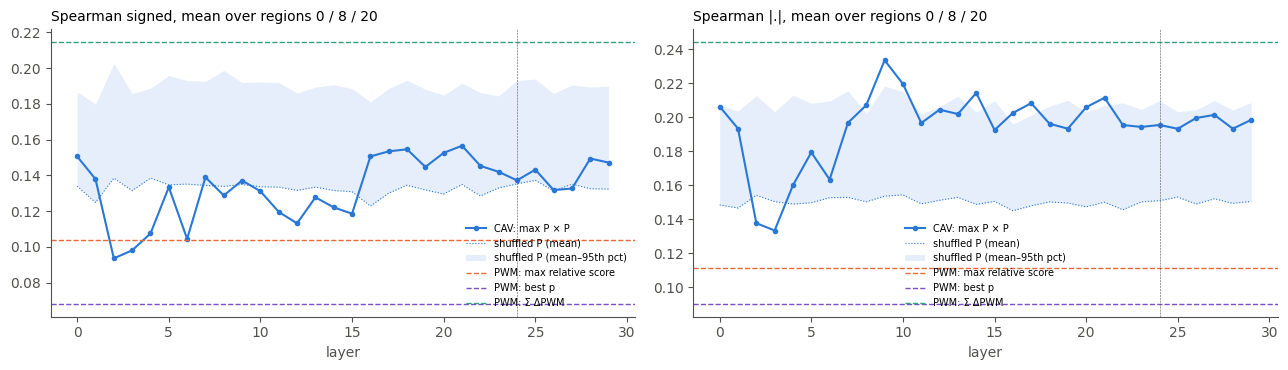

In [6]:
rows = []
for l in LAYERS:
    pm = {r: d["P"][l].values for r, d in D.items()}
    o = evaluate(pm, ["CAV: max P × P"])["CAV: max P × P"].mean(0)
    nl = np.array([evaluate(perm_global(l, rng), ["CAV: max P × P"])["CAV: max P × P"].mean(0) for _ in range(200)])
    for j, mt in enumerate(METRICS):
        rows.append({"layer": l, "metric": mt, "obs": o[j], "null": np.nanmean(nl[:, j]),
                     "null95": np.nanpercentile(nl[:, j], 95), "p": np.mean(nl[:, j] >= o[j])})
LC = pd.DataFrame(rows)
LC.to_csv(f"{OUT}/primary_by_layer.csv", index=False)
show = [l for l in LAYERS if l % 3 == 0 or l == LAYERS[-1] or l == LP]
for mt in METRICS[:2]:
    t = LC[LC.metric == mt].set_index("layer")
    print(f"--- {mt}: layers with p < .05: {int((t['p'] < .05).sum())} of {len(t)}")
    print(t.loc[show, ["obs", "null", "null95", "p"]].T.to_string(float_format=lambda x: f"{x:+.3f}"))
    print()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, mt in zip(ax, METRICS[:2]):
    t = LC[LC.metric == mt]
    a.plot(t.layer, t.obs, c="#2a78d6", marker="o", ms=3, label="CAV: max P × P")
    a.plot(t.layer, t.null, c="#2a78d6", lw=.8, ls=":", label="shuffled P (mean)")
    a.fill_between(t.layer, t.null, t.null95, color="#2a78d6", alpha=.12, lw=0, label="shuffled P (mean–95th pct)")
    j = METRICS.index(mt)
    for k, c in (("PWM: max relative score", "#eb6834"), ("PWM: best p", "#7a4fc8"), ("PWM: Σ ΔPWM", "#2fa37a")):
        a.axhline(obs[k].mean(0)[j], c=c, lw=1, ls="--", label=k)
    a.axvline(LP, c=INK, lw=.4, ls="--")
    a.set_xlabel("layer"); a.set_title(f"{mt}, mean over regions 0 / 8 / 20", loc="left", fontsize=10)
    a.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/primary_by_layer.png", dpi=150, bbox_inches="tight"); plt.show()


## 5 Which motif each rule picks at the strongest positions

Per region, the 8 positions (inside hits with a direction) with the largest mean |log2FC|, and the motif chosen there by
the CAV (max P, at `LP`), by the relative PWM score and by the best p (most common choice over the position's SNVs).

In [7]:
rows = []
for r, d in D.items():
    p = d["P"][LP].values
    g = p[d["hi"]]
    ch = {"CAV max P": first_by(d, g), "PWM max rel": first_by(d, d["rel"]), "PWM best p": d["st"]}
    S = pd.DataFrame({"local": d["local"], "y": d["y"]})
    for k, idx in ch.items():
        S[k] = [f"{m} {pp:.2f}" for m, pp in zip(d["hits"].loc[d["hid"][idx], "motif"].values, g[idx])]
    top = S.groupby("local")["y"].apply(lambda v: v.abs().mean()).nlargest(8).index
    for loc in sorted(top):
        s = S[S.local == loc]
        rows.append({"region": r, "position": loc, "mean |log2FC|": s["y"].abs().mean(),
                     **{k: s[k].mode().iloc[0] for k in ch}})
W = pd.DataFrame(rows)
W.to_csv(f"{OUT}/choices_at_top_positions_L{LP}.csv", index=False)
print("(motif and its P(bound) at the chosen hit)")
print(W.to_string(index=False, float_format=lambda x: f"{x:.2f}"))


(motif and its P(bound) at the chosen hit)
 region  position  mean |log2FC|    CAV max P  PWM max rel   PWM best p
      0       376           1.59  ZNF281 0.79  ZNF263 0.63    KLF9 0.30
      0       387           1.95   FOXA1 0.88   FOXA3 0.84   ZNF57 0.69
      0       388           1.95   FOXA1 0.88   FOXA3 0.84   ZNF57 0.69
      0       389           2.43   FOXA1 0.88   FOXA3 0.84   ZNF57 0.69
      0       390           1.91   FOXA1 0.88   FOXA3 0.84   ZNF57 0.69
      0       391           1.59   FOXA1 0.88   FOXA3 0.84   ZNF57 0.69
      0       475           1.70  ZNF740 0.87    KLF1 0.39   RREB1 0.33
      0       488           1.96   RREB1 0.36   RREB1 0.36   RREB1 0.36
      8       262           2.44  SREBF1 0.60  SREBF1 0.60  SREBF1 0.60
      8       268           2.50  SREBF1 0.60  SREBF1 0.60  SREBF1 0.60
      8       276           2.66     SP2 0.83     SP4 0.60  ZNF281 0.60
      8       278           2.81     SP2 0.83  ZNF263 0.09  ZNF281 0.60
      8       279    

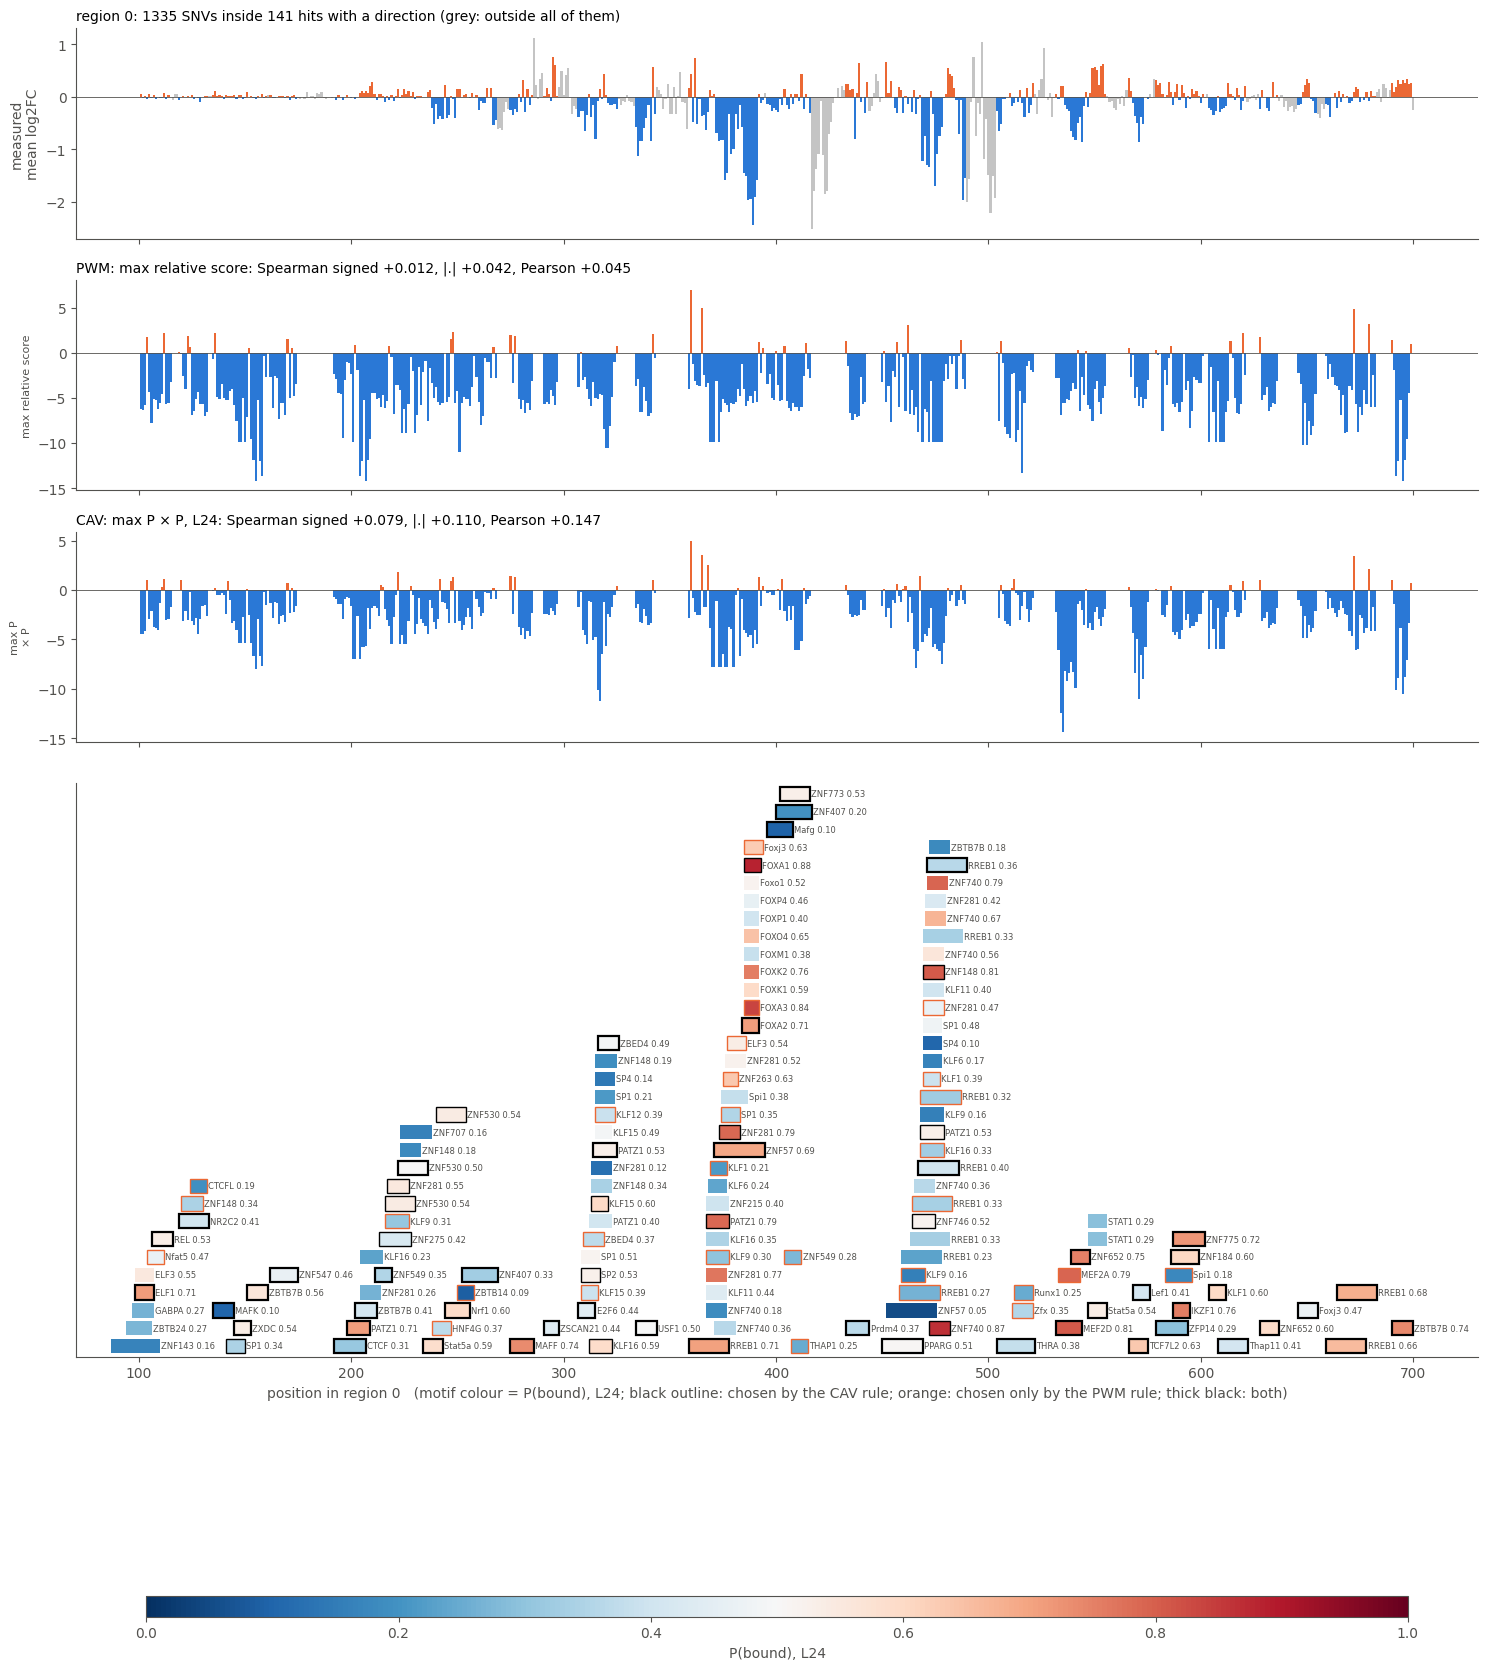

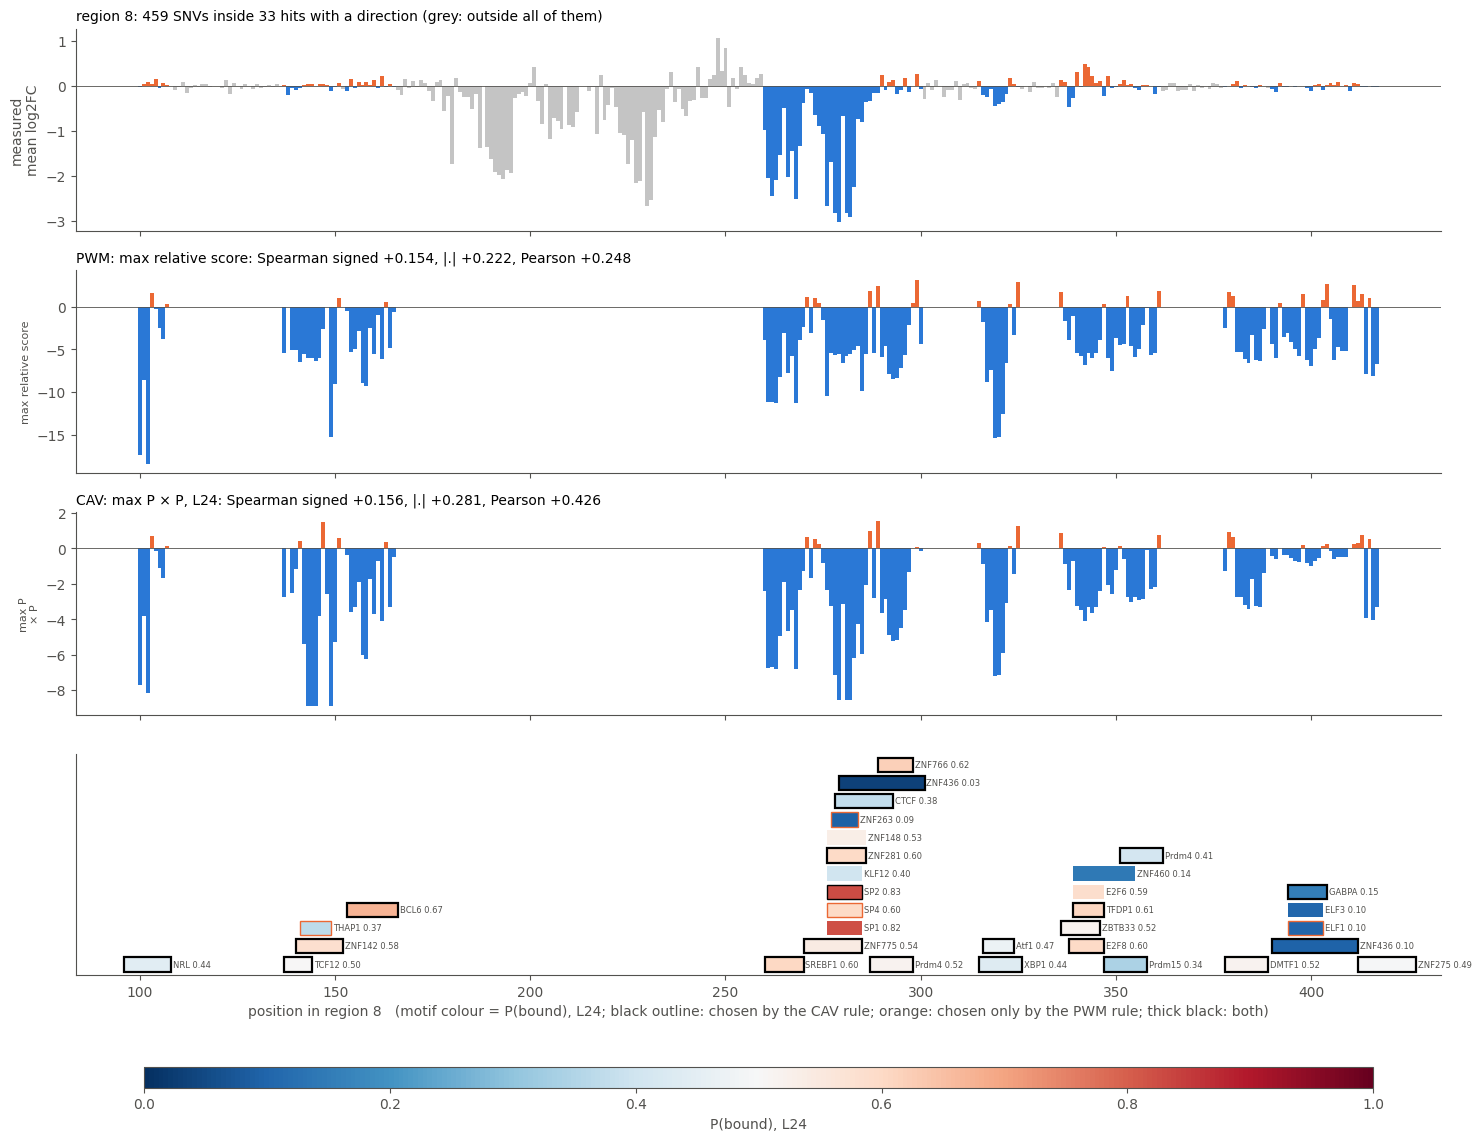

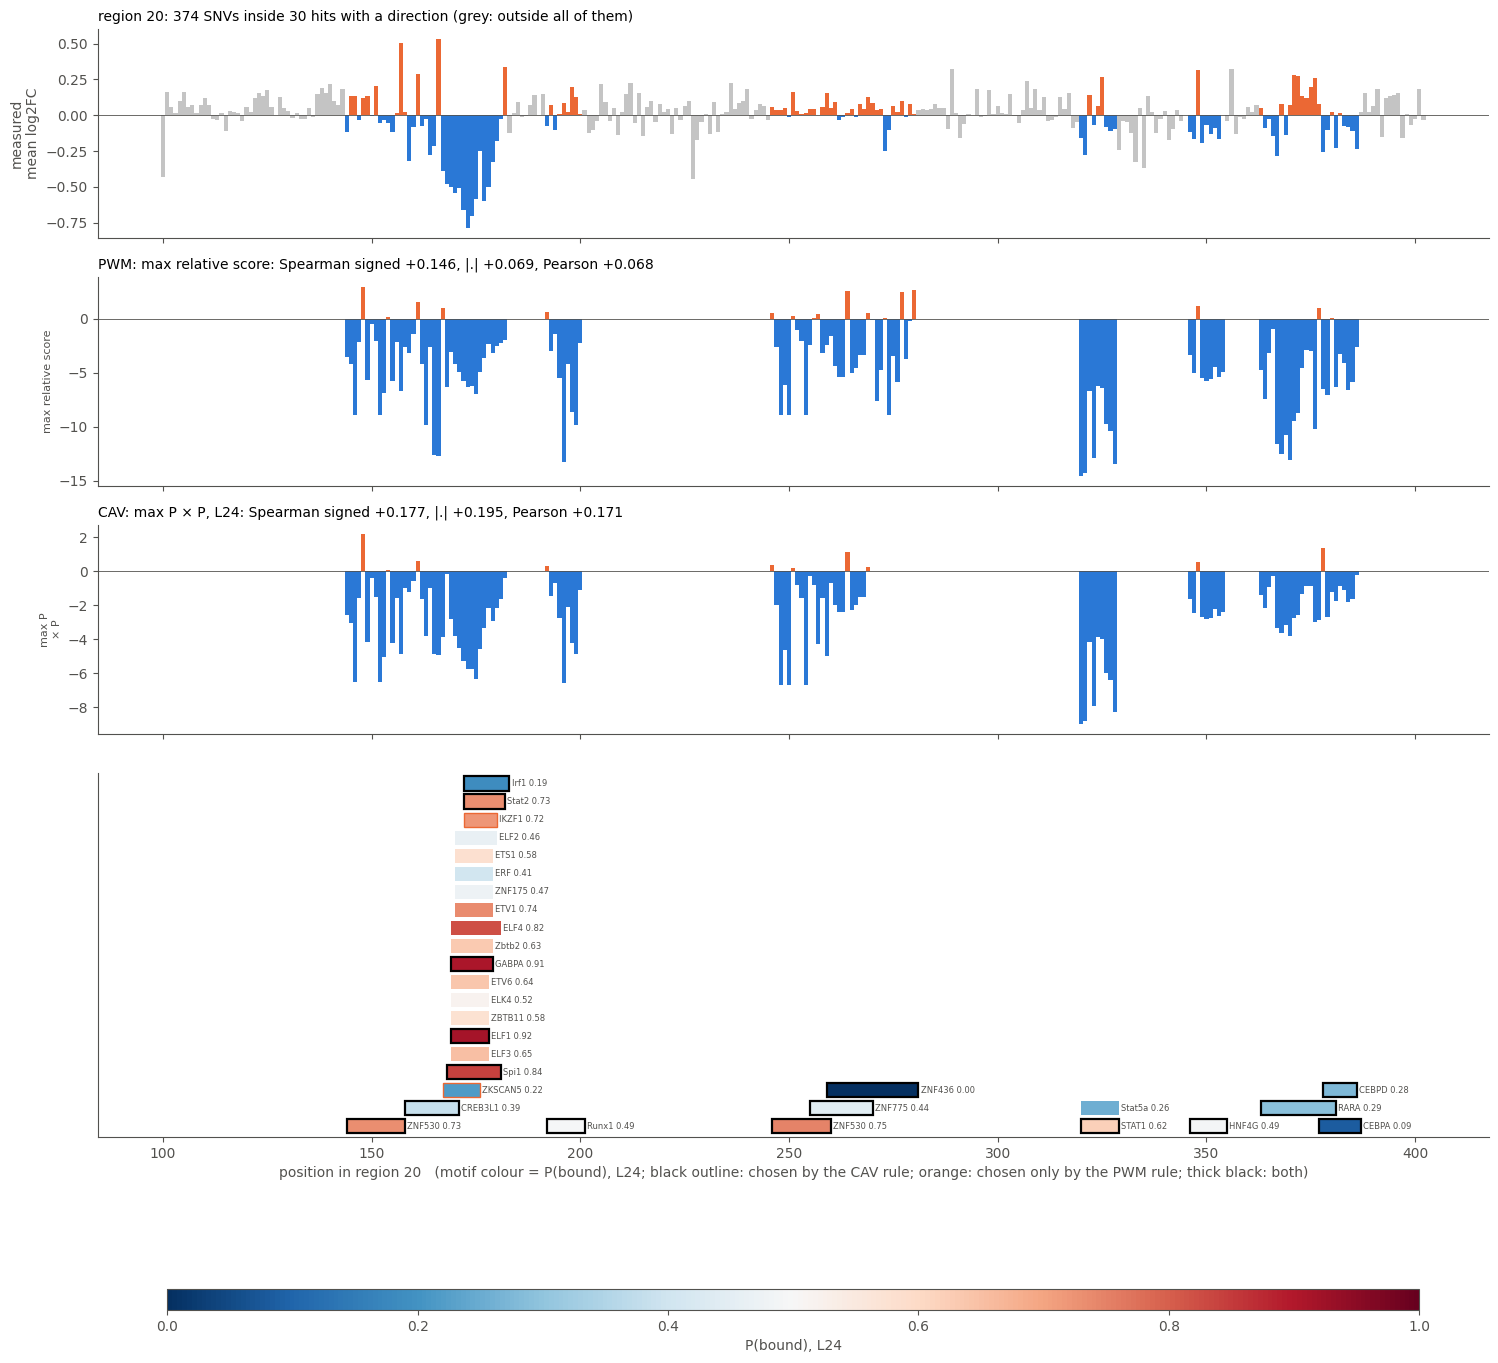

In [10]:
import matplotlib.colors as mcolors
SHOW = ("PWM: max relative score", "CAV: max P × P")   # or ("PWM: Σ ΔPWM", "CAV: Σ ΔPWM × P")
C1, C2, GREY = "#2a78d6", "#eb6834", "#c4c4c4"
cm, nm = plt.get_cmap("RdBu_r"), mcolors.TwoSlopeNorm(vmin=0, vcenter=0.5, vmax=1)
col = lambda v: np.where(v < 0, C1, C2)

for r, d in D.items():
    p = d["P"][LP].values
    pr = predict(d, p)
    S = pd.DataFrame({"local": d["local"], "y": d["y"], "pwm": pr[SHOW[0]], "cav": pr[SHOW[1]]})
    pos_all = d["snv"].groupby("local")["log2FC"].mean()
    pos = S.groupby("local")[["pwm", "cav"]].mean()
    sc = {k: scores(S[k].values, S["y"].values) for k in ("pwm", "cav")}
    # hits chosen by each rule (only meaningful for the "max" rules; for Σ every hit is used)
    g = p[d["hi"]]
    chosen_cav = set(d["hid"][first_by(d, g)]) if "max" in SHOW[1] else set(d["hs"])
    chosen_pwm = set(d["hid"][first_by(d, d["rel"])] if "relative" in SHOW[0] else d["hid"][d["st"]]) if "Σ" not in SHOW[0] else set(d["hs"])

    hh = d["hits"].loc[d["hs"], ["motif", "start", "end"]].copy()
    hh["hit_id"], hh["P"] = d["hs"], p
    hh = hh.sort_values(["start", "end"]).reset_index(drop=True)
    hh["label"] = [f"{m} {q:.2f}" for m, q in zip(hh["motif"], hh["P"])]
    span = pos_all.index.max() - pos_all.index.min() + 1
    ends, lane = [], []
    for a, b, lab in zip(hh["start"], hh["end"], hh["label"]):
        b = b + 1 + 0.0045 * span * len(lab)
        k = next((i for i, e in enumerate(ends) if e <= a), len(ends))
        if k == len(ends):
            ends.append(b)
        else:
            ends[k] = b
        lane.append(k)
    nrow = max(lane) + 1 if lane else 1

    fig, ax = plt.subplots(4, 1, figsize=(15, 8 + 0.3 * nrow), sharex=True,
                           gridspec_kw={"height_ratios": [2.2, 2.2, 2.2, 0.3 * nrow + 0.4]})
    ax[0].bar(pos_all.index, pos_all.values, width=1,
              color=np.where(~pos_all.index.isin(pos.index), GREY, col(pos_all.values)))
    ax[0].set_ylabel("measured\nmean log2FC")
    ax[0].set_title(f"region {r}: {len(S)} SNVs inside {len(d['hs'])} hits with a direction (grey: outside all of them)",
                    loc="left", fontsize=10)
    for a, k, name in ((ax[1], "pwm", SHOW[0]), (ax[2], "cav", SHOW[1])):
        a.bar(pos.index, pos[k].values, width=1, color=col(pos[k].values))
        a.set_ylabel(name.split(": ")[1].replace(" × ", "\n× "), fontsize=8)
        a.set_title(f"{name}{', L' + str(LP) if k == 'cav' else ''}: Spearman signed {sc[k][0]:+.3f}, |.| {sc[k][1]:+.3f}, "
                    f"Pearson {sc[k][2]:+.3f}", loc="left", fontsize=10)
    for a in ax[:3]:
        a.axhline(0, color=INK, lw=.6)
    for (_, h), k in zip(hh.iterrows(), lane):
        inC, inP = h["hit_id"] in chosen_cav, h["hit_id"] in chosen_pwm
        ec = "black" if inC else (C2 if inP else "none")
        ax[3].add_patch(plt.Rectangle((h["start"], k), h["end"] - h["start"], 0.8, facecolor=cm(nm(h["P"])),
                                      edgecolor=ec, linewidth=1.6 if (inC and inP) else (1.0 if ec != "none" else 0)))
        ax[3].text(h["end"] + 0.5, k + 0.4, h["label"], va="center", fontsize=6, color=INK)
    ax[3].set_ylim(-0.2, nrow); ax[3].set_yticks([])
    ax[3].set_xlabel(f"position in region {r}   (motif colour = P(bound), L{LP}; black outline: chosen by the CAV rule; "
                     f"orange: chosen only by the PWM rule; thick black: both)")
    fig.colorbar(plt.cm.ScalarMappable(norm=nm, cmap=cm), ax=ax[3], shrink=.9, label=f"P(bound), L{LP}",
                 orientation="horizontal", pad=0.25, aspect=60)
    plt.tight_layout()
    plt.savefig(f"{OUT}/track_r{r}_{'sum' if 'Σ' in SHOW[1] else 'max'}_L{LP}.png", dpi=150, bbox_inches="tight"); plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

P ≥ 0.5, layer 24, w = sigmoid(10 (P - 0.75)); mean over regions 0 / 8 / 20; nulls: 1000 shuffles

--- Spearman signed
                         Spearman signed  null N1   p N1  null N2   p N2
rule                                                                    
PWM: mean ΔPWM                    +0.118                                
PWM: max relative score           +0.104                                
CAV gate: mean ΔPWM               +0.115   +0.135 +0.635   +0.095 +0.082
CAV gate: max P                   +0.109   +0.122 +0.603   +0.086 +0.092
CAV gate: max P × P               +0.121   +0.134 +0.604   +0.103 +0.148
CAV gate: max P × w               +0.144   +0.147 +0.550   +0.127 +0.174
CAV gate: mean ΔPWM × w           +0.128   +0.135 +0.558   +0.118 +0.317

--- Spearman |.|
                         Spearman |.|  null N1   p N1  null N2   p N2
rule  

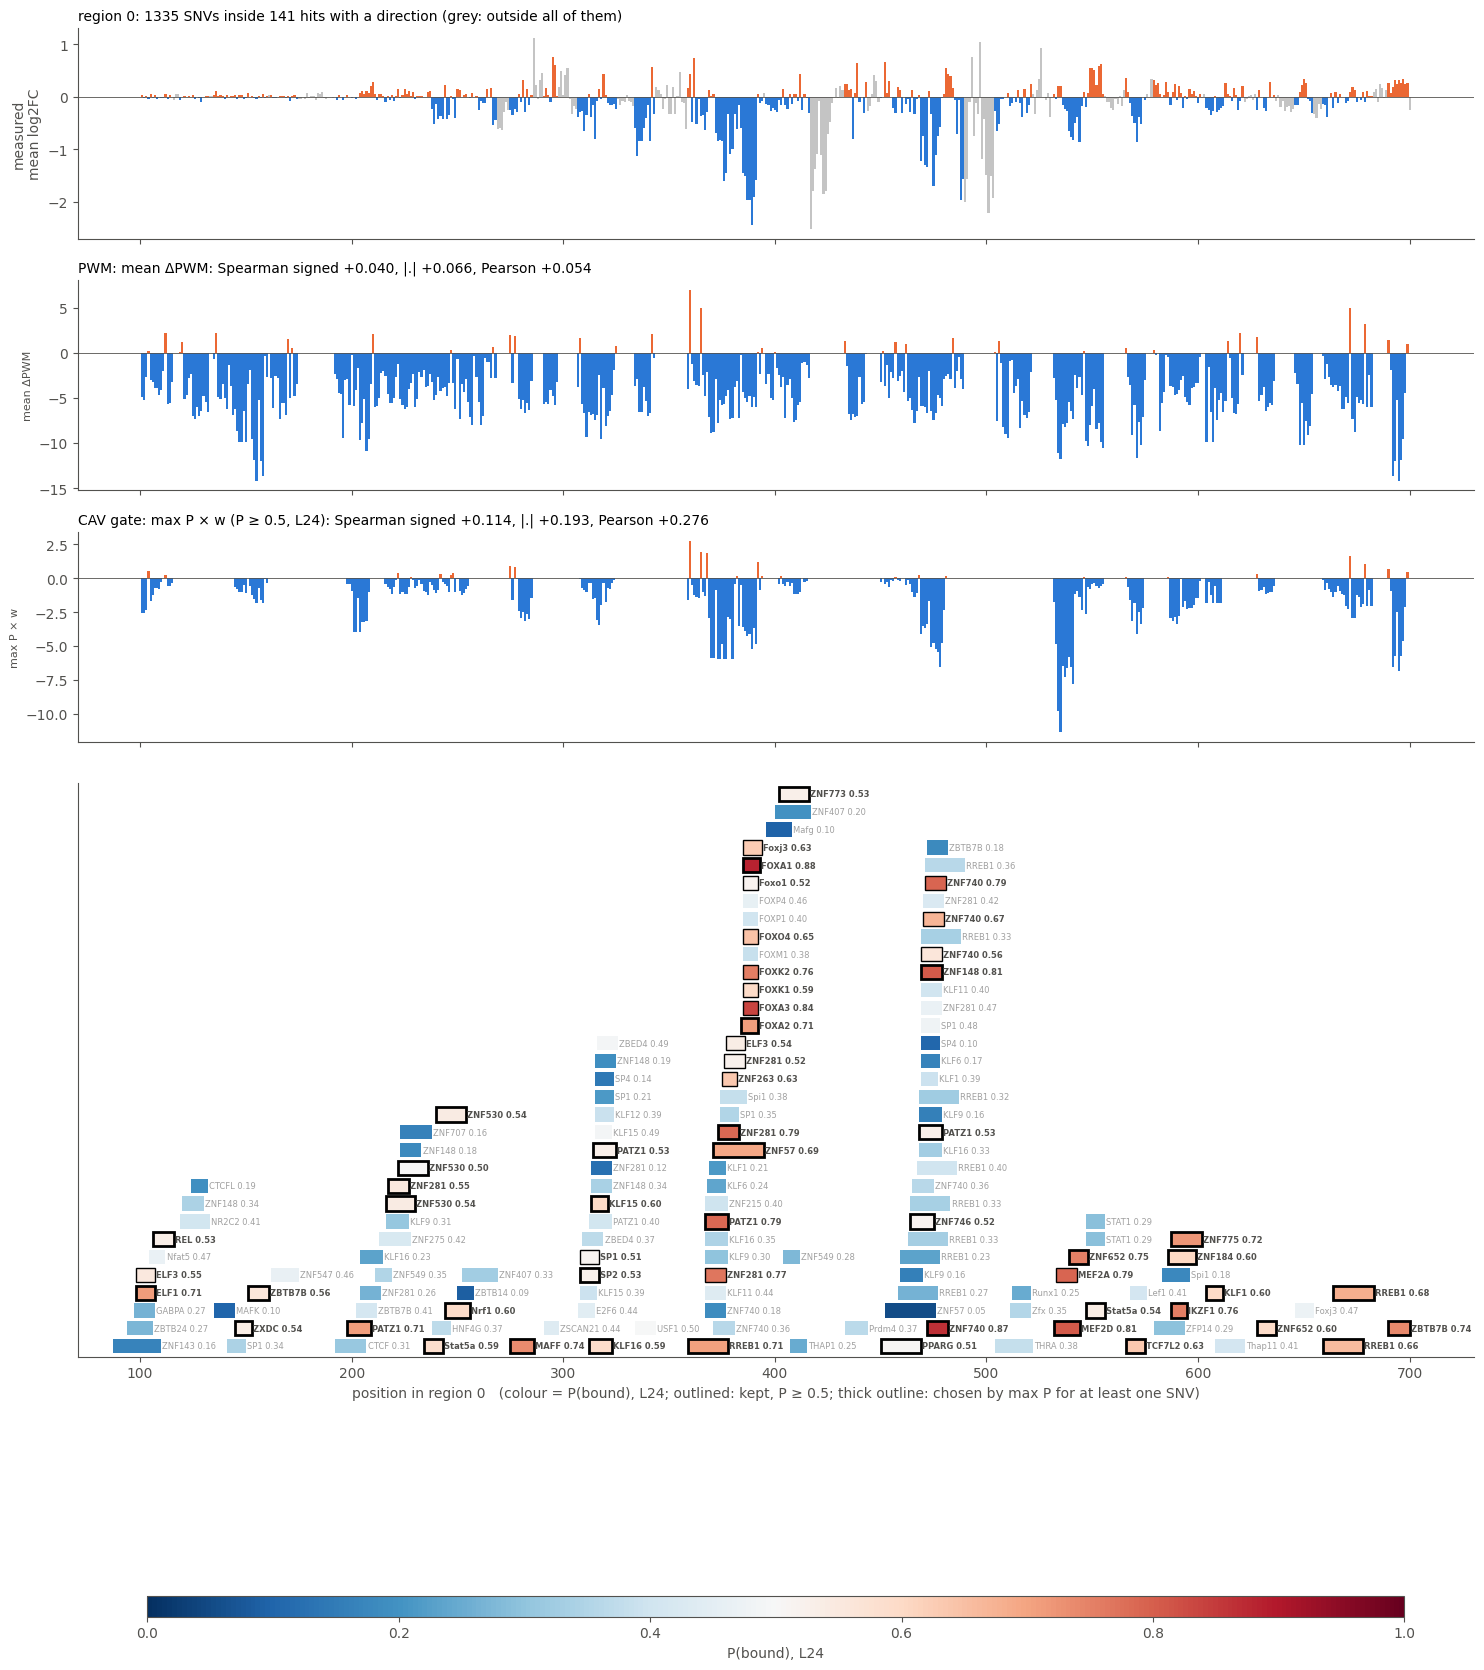

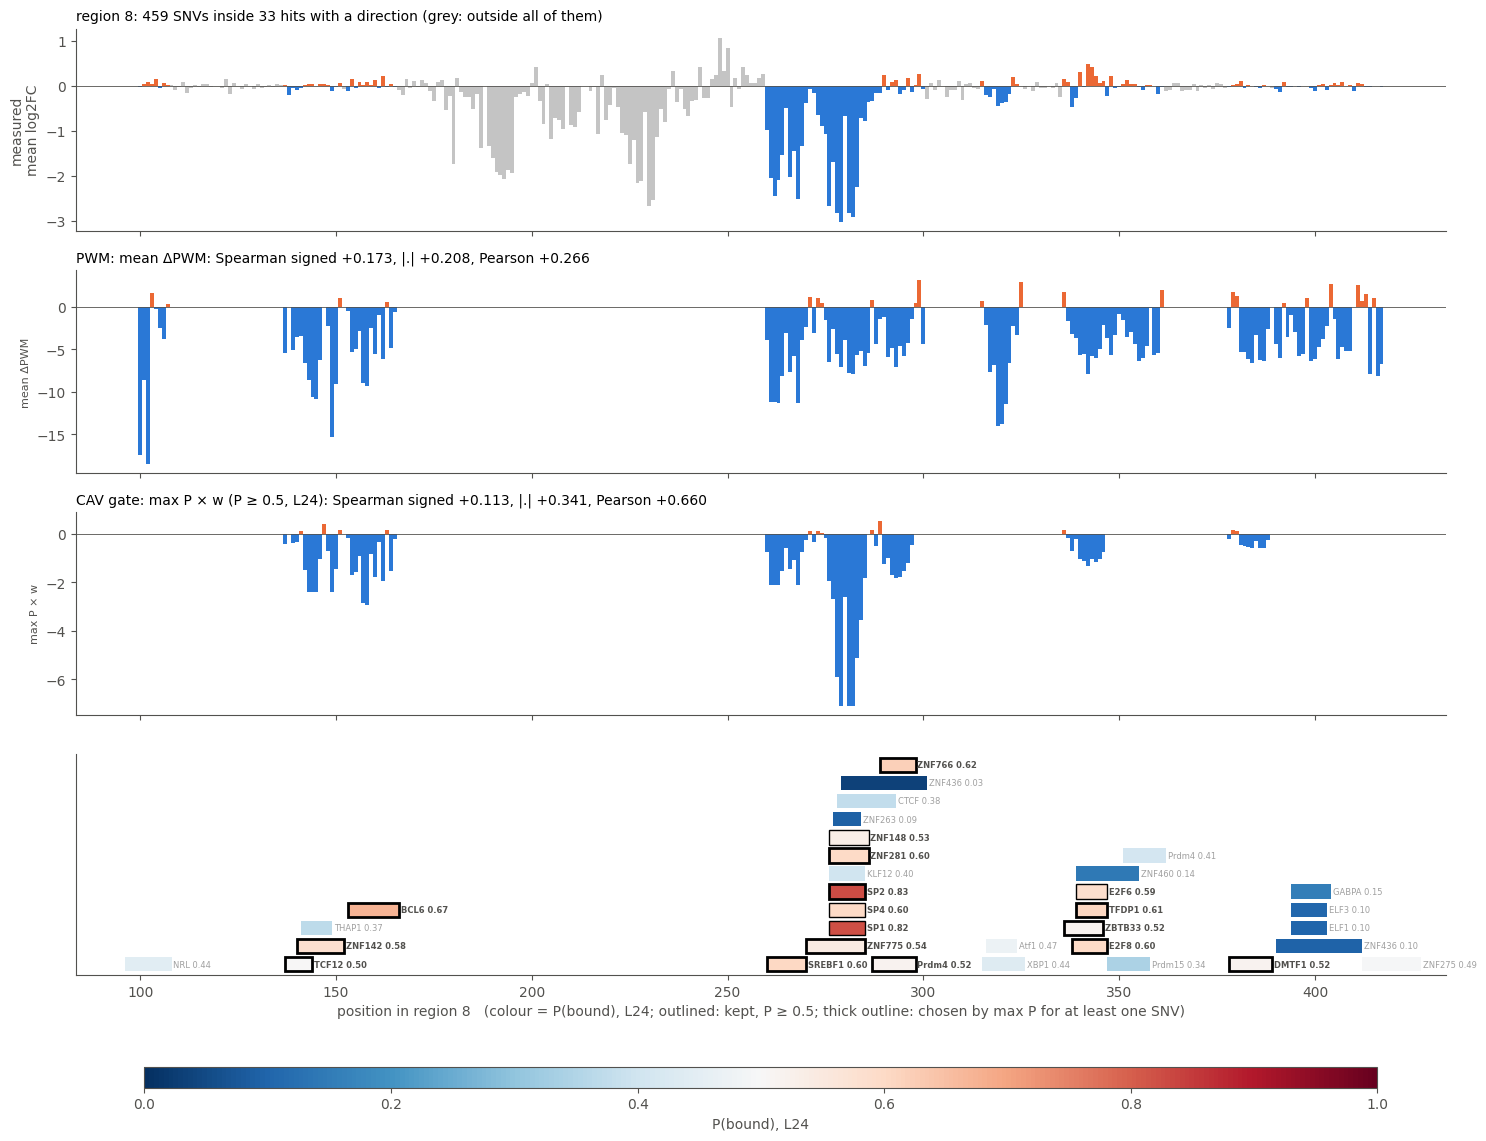

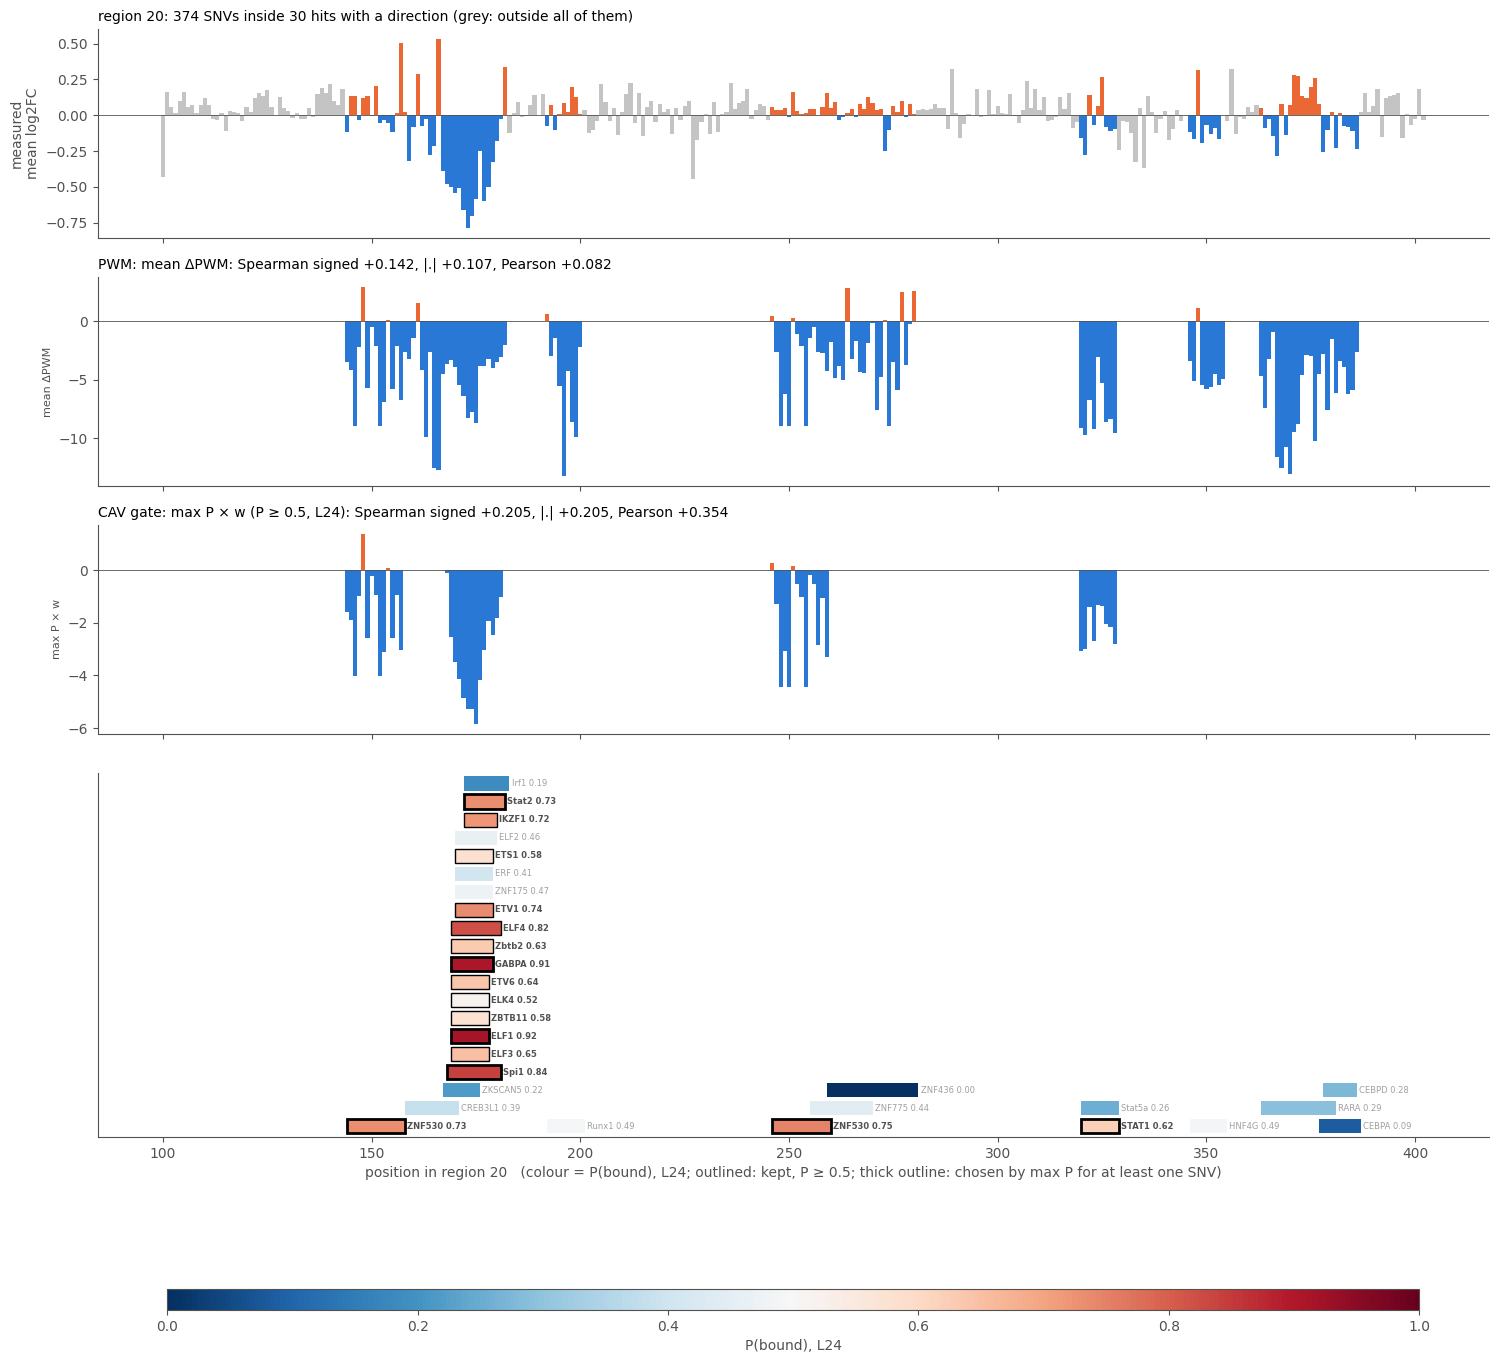

In [24]:
# CAV gate on the MPRA, regions 0 / 8 / 20: one cell (data load cached; change the settings and rerun)
TH = 0.5                      # hits with P(bound) < TH are dropped
LP = 24                       # layer of P(bound)
N_PERM = 1000                 # shuffles for the nulls (N1: across hits; N2: within motif)
MID, K = 0.75, 10             # weight w(P) = sigmoid(K * (P - MID)): ~0 at P = 0.5, ~1 at P = 1
PLOT = ("PWM: mean ΔPWM", "CAV gate: max P × w")        # which two rules the track figures show
WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"

import os, json
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

pd.set_option("display.width", 250)
INK, C1, C2, GREY = "#52514e", "#2a78d6", "#eb6834", "#c4c4c4"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK})
OUT = f"{WORK_DIR}/hit_selection"
os.makedirs(OUT, exist_ok=True)

# ---------- data (loaded once per session) ----------
if "D_GATE" not in globals():
    try:
        from pymemesuite.common import MotifFile
    except ImportError:
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymemesuite"], check=True)
        from pymemesuite.common import MotifFile
    C = json.load(open(f"{WORK_DIR}/config.json"))
    with MotifFile(C["meme_path"]) as _mf:
        _all = list(_mf)
    _MOTIF = {}
    for m in _all:
        _MOTIF.setdefault(m.name.decode(), m)

    def _max_score(name):
        f = np.asarray(_MOTIF[name].frequencies, float)
        f = f / f.sum(1, keepdims=True)
        return float(np.log2(np.clip(f, 1e-9, 1.0) / 0.25).max(1).sum())

    REG = {0: ("fcav_pgc_hk_r0", "fcav_pgc_hk_lr_r0"), 8: ("fcav_pgc_hk", "fcav_pgc_hk_lr"),
           20: ("fcav_pgc_hk_r20", "fcav_pgc_hk_lr_r20")}
    D_GATE = {}
    for r, (src, fit) in REG.items():
        S_, F_ = f"{WORK_DIR}/{src}", f"{WORK_DIR}/{fit}"
        mwj = json.load(open(f"{S_}/mpra_windows.json"))
        tfs = sorted(m for m, s in mwj["status"].items() if s == "built" and os.path.exists(f"{F_}/fits/{m}.npz"))
        fits = {m: np.load(f"{F_}/fits/{m}.npz") for m in tfs}
        layers = list(fits[tfs[0]]["layers"])
        dec = pd.concat([pd.DataFrame(fits[m]["dec_hit"], index=fits[m]["hit_id"], columns=layers) for m in tfs])
        hits = pd.read_csv(f"{S_}/hits.csv").set_index("hit_id")
        hits["rel"] = hits["pwm"] / hits["motif"].map({m: _max_score(m) for m in hits["motif"].unique()})
        snv = pd.read_csv(f"{S_}/snvs.csv")
        q = pd.read_csv(f"{S_}/snv_hit_dpwm.csv")
        q = q[q["hit_id"].isin(dec.index)].sort_values(["snv", "hit_id"]).reset_index(drop=True)
        hs = np.array(sorted(q["hit_id"].unique()))
        sn = q["snv"].values
        st = np.r_[0, np.flatnonzero(sn[1:] != sn[:-1]) + 1]
        D_GATE[r] = dict(P=1 / (1 + np.exp(-dec.loc[hs])), hs=hs, motif=hits.loc[hs, "motif"].values, hits=hits, snv=snv,
                         hi=np.searchsorted(hs, q["hit_id"].values), hid=q["hit_id"].values, dp=q["dpwm"].values,
                         rel=hits.loc[q["hit_id"], "rel"].values, sn=sn, st=st,
                         y=snv.loc[sn[st], "log2FC"].values, local=snv.loc[sn[st], "local"].values)
        print(f"region {r:2d}: {len(tfs)} TFs, {len(hs)} hits with a direction, {len(st)} SNVs inside them")
D = D_GATE


# ---------- rules ----------
def _first_by(d, key):
    # per SNV, the row with the largest key (ties: smallest hit_id = smallest FIMO p)
    return np.lexsort((d["hid"], -key, d["sn"]))[d["st"]]


def predict(d, p_hit, th=TH):
    g = p_hit[d["hi"]]
    keep = (g >= th).astype(float)
    n_keep = np.add.reduceat(keep, d["st"])
    any_keep = n_keep > 0
    iP = _first_by(d, np.where(keep > 0, g, -1.0))          # highest P among the kept hits
    iR = _first_by(d, d["rel"])
    return {
        "PWM: mean ΔPWM": np.add.reduceat(d["dp"], d["st"]) / np.add.reduceat(np.ones_like(d["dp"]), d["st"]),
        "PWM: max relative score": d["dp"][iR],
        "CAV gate: mean ΔPWM": np.where(any_keep, np.add.reduceat(d["dp"] * keep, d["st"]) / np.maximum(n_keep, 1), 0.0),
        "CAV gate: max P": np.where(any_keep, d["dp"][iP], 0.0),
        "CAV gate: max P × P": np.where(any_keep, d["dp"][iP] * g[iP], 0.0),
        "CAV gate: max P × w": np.where(any_keep, d["dp"][iP] / (1 + np.exp(-K * (g[iP] - MID))), 0.0),
        "CAV gate: mean ΔPWM × w": np.where(any_keep, np.add.reduceat(d["dp"] * keep / (1 + np.exp(-K * (g - MID))), d["st"])
                                           / np.maximum(n_keep, 1), 0.0),
    }


RULES = list(predict(D[8], D[8]["P"][LP].values))
CAV = [k for k in RULES if k.startswith("CAV")]
METRICS = ["Spearman signed", "Spearman |.|", "Pearson signed"]


def scores(pred, y):
    if np.std(pred) == 0:
        return np.array([np.nan] * 3)
    return np.array([stats.spearmanr(pred, y)[0], stats.spearmanr(np.abs(pred), np.abs(y))[0], stats.pearsonr(pred, y)[0]])


def evaluate(pmap, rules):
    out = {k: [] for k in rules}
    for r, d in D.items():
        pr = predict(d, pmap[r])
        for k in rules:
            out[k].append(scores(pr[k], d["y"]))
    return {k: np.array(v) for k, v in out.items()}       # rule -> (regions, metrics)


GROUPS = {}
for r, d in D.items():
    for i, m in enumerate(d["motif"]):
        GROUPS.setdefault(m, []).append((r, i))


def perm_global(rng):
    return {r: rng.permutation(d["P"][LP].values) for r, d in D.items()}


def perm_motif(rng):
    out = {r: d["P"][LP].values.copy() for r, d in D.items()}
    for mem in GROUPS.values():
        if len(mem) > 1:
            vals = np.array([D[r]["P"][LP].values[i] for r, i in mem])[rng.permutation(len(mem))]
            for (r, i), v in zip(mem, vals):
                out[r][i] = v
    return out


# ---------- evaluation ----------
rng = np.random.default_rng(0)
obs = evaluate({r: d["P"][LP].values for r, d in D.items()}, RULES)
n1 = np.array([[v.mean(0) for v in evaluate(perm_global(rng), CAV).values()] for _ in range(N_PERM)])   # (perm, rule, metric)
n2 = np.array([[v.mean(0) for v in evaluate(perm_motif(rng), CAV).values()] for _ in range(N_PERM)])
rows = []
for k in RULES:
    row = {"rule": k}
    for j, mt in enumerate(METRICS):
        row[mt] = obs[k].mean(0)[j]
        if k in CAV:
            ki = CAV.index(k)
            row[f"{mt}: null N1"], row[f"{mt}: p N1"] = np.nanmean(n1[:, ki, j]), np.mean(n1[:, ki, j] >= row[mt])
            row[f"{mt}: null N2"], row[f"{mt}: p N2"] = np.nanmean(n2[:, ki, j]), np.mean(n2[:, ki, j] >= row[mt])
    rows.append(row)
T = pd.DataFrame(rows).set_index("rule")
T.to_csv(f"{OUT}/gate{TH}_L{LP}_w{MID}-{K}.csv")
print(f"\nP ≥ {TH}, layer {LP}, w = sigmoid({K} (P - {MID})); mean over regions 0 / 8 / 20; nulls: {N_PERM} shuffles\n")
for mt in METRICS:
    cols = [mt] + [c for c in T.columns if c.startswith(mt + ":")]
    print(f"--- {mt}")
    print(T[cols].rename(columns=lambda c: c.replace(mt + ": ", "")).to_string(float_format=lambda x: f"{x:+.3f}", na_rep=""))
    print()
print("--- per region")
print(pd.DataFrame({(k, f"r{r}"): obs[k][i] for k in RULES for i, r in enumerate(D)}, index=METRICS).T
      .unstack(1).to_string(float_format=lambda x: f"{x:+.3f}"))
for r, d in D.items():
    p = d["P"][LP].values
    nk = np.add.reduceat((p >= TH)[d["hi"]].astype(int), d["st"])
    print(f"region {r}: {int((p >= TH).sum())} of {len(p)} hits kept; {int((nk == 0).sum())} of {len(nk)} SNVs predicted 0")

# ---------- track figures ----------
cm, nm = plt.get_cmap("RdBu_r"), mcolors.TwoSlopeNorm(vmin=0, vcenter=0.5, vmax=1)
col = lambda v: np.where(v < 0, C1, C2)
for r, d in D.items():
    p = d["P"][LP].values
    pr = predict(d, p)
    S = pd.DataFrame({"local": d["local"], "y": d["y"], "a": pr[PLOT[0]], "b": pr[PLOT[1]]})
    pos_all = d["snv"].groupby("local")["log2FC"].mean()
    pos = S.groupby("local")[["a", "b"]].mean()
    sc = {k: scores(S[k].values, S["y"].values) for k in ("a", "b")}
    g = p[d["hi"]]
    used_max = set(d["hid"][_first_by(d, np.where(g >= TH, g, -1.0))][np.add.reduceat((g >= TH).astype(int), d["st"]) > 0])

    hh = d["hits"].loc[d["hs"], ["motif", "start", "end"]].copy()
    hh["hit_id"], hh["P"] = d["hs"], p
    hh = hh.sort_values(["start", "end"]).reset_index(drop=True)
    hh["label"] = [f"{m} {q:.2f}" for m, q in zip(hh["motif"], hh["P"])]
    span = pos_all.index.max() - pos_all.index.min() + 1
    ends, lane = [], []
    for a, b, lab in zip(hh["start"], hh["end"], hh["label"]):
        b = b + 1 + 0.0045 * span * len(lab)
        k = next((i for i, e in enumerate(ends) if e <= a), len(ends))
        if k == len(ends):
            ends.append(b)
        else:
            ends[k] = b
        lane.append(k)
    nrow = max(lane) + 1 if lane else 1

    fig, ax = plt.subplots(4, 1, figsize=(15, 8 + 0.3 * nrow), sharex=True,
                           gridspec_kw={"height_ratios": [2.2, 2.2, 2.2, 0.3 * nrow + 0.4]})
    ax[0].bar(pos_all.index, pos_all.values, width=1, color=np.where(~pos_all.index.isin(pos.index), GREY, col(pos_all.values)))
    ax[0].set_ylabel("measured\nmean log2FC")
    ax[0].set_title(f"region {r}: {len(S)} SNVs inside {len(d['hs'])} hits with a direction (grey: outside all of them)",
                    loc="left", fontsize=10)
    for a, k, name in ((ax[1], "a", PLOT[0]), (ax[2], "b", PLOT[1])):
        a.bar(pos.index, pos[k].values, width=1, color=col(pos[k].values))
        a.set_ylabel(name.split(": ")[1], fontsize=8)
        a.set_title(f"{name}{f' (P ≥ {TH}, L{LP})' if name.startswith('CAV') else ''}: Spearman signed {sc[k][0]:+.3f}, "
                    f"|.| {sc[k][1]:+.3f}, Pearson {sc[k][2]:+.3f}", loc="left", fontsize=10)
    for a in ax[:3]:
        a.axhline(0, color=INK, lw=.6)
    for (_, h), k in zip(hh.iterrows(), lane):
        kept = h["P"] >= TH
        lw = 2.0 if (kept and "max" in PLOT[1] and h["hit_id"] in used_max) else (1.0 if kept else 0)
        ax[3].add_patch(plt.Rectangle((h["start"], k), h["end"] - h["start"], 0.8, facecolor=cm(nm(h["P"])),
                                      edgecolor="black" if kept else "none", linewidth=lw))
        ax[3].text(h["end"] + 0.5, k + 0.4, h["label"], va="center", fontsize=6, color=INK if kept else "#a0a0a0",
                   fontweight="bold" if kept else "normal")
    ax[3].set_ylim(-0.2, nrow); ax[3].set_yticks([])
    ax[3].set_xlabel(f"position in region {r}   (colour = P(bound), L{LP}; outlined: kept, P ≥ {TH}; "
                     f"thick outline: chosen by max P for at least one SNV)")
    fig.colorbar(plt.cm.ScalarMappable(norm=nm, cmap=cm), ax=ax[3], shrink=.9, label=f"P(bound), L{LP}",
                 orientation="horizontal", pad=0.25, aspect=60)
    plt.tight_layout()
    plt.savefig(f"{OUT}/track_r{r}_gate{TH}_L{LP}.png", dpi=150, bbox_inches="tight"); plt.show()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
region  0: 78 TFs, 141 hits with a direction, 1335 SNVs inside them; 303 JASPAR hits of any motif cover these SNVs
region  8: 31 TFs, 33 hits with a direction, 459 SNVs inside them; 66 JASPAR hits of any motif cover these SNVs
region 20: 29 TFs, 30 hits with a direction, 374 SNVs inside them; 63 JASPAR hits of any motif cover these SNVs

=== fixed settings: P ≥ 0.5, w = sigmoid(20 (P - 0.75)), occ = sigmoid(10 (s - 0.8)), layer 24; mean over regions 0 / 8 / 20; nulls 1000 shuffles

--- Spearman signed
                                        Spearman signed  null N1   p N1  null N2   p N2
rule                                                                                   
PWM: best p                                      +0.068                                
PWM: max relative score                          +0.104                                
PWM: max rel

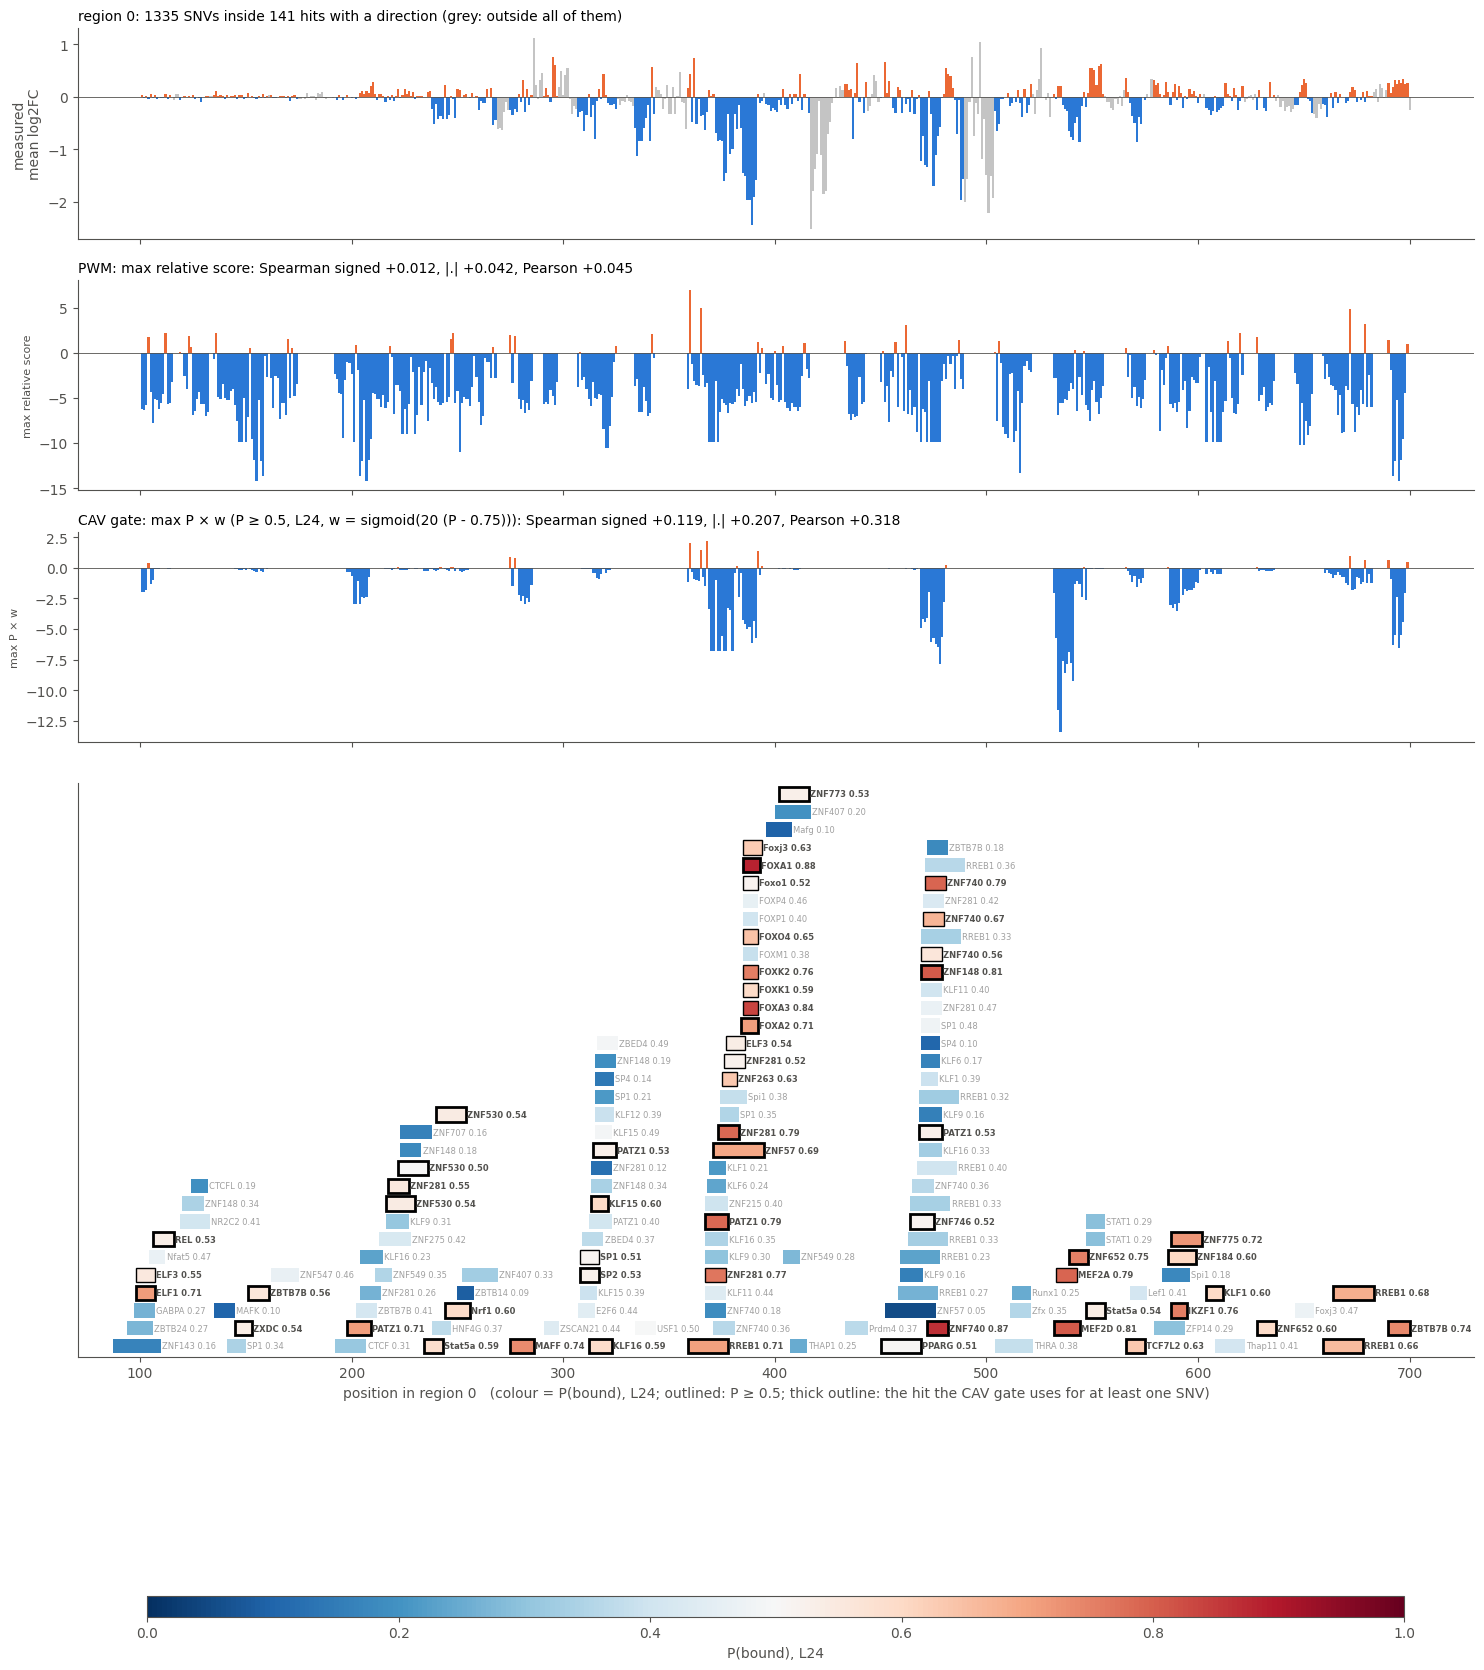

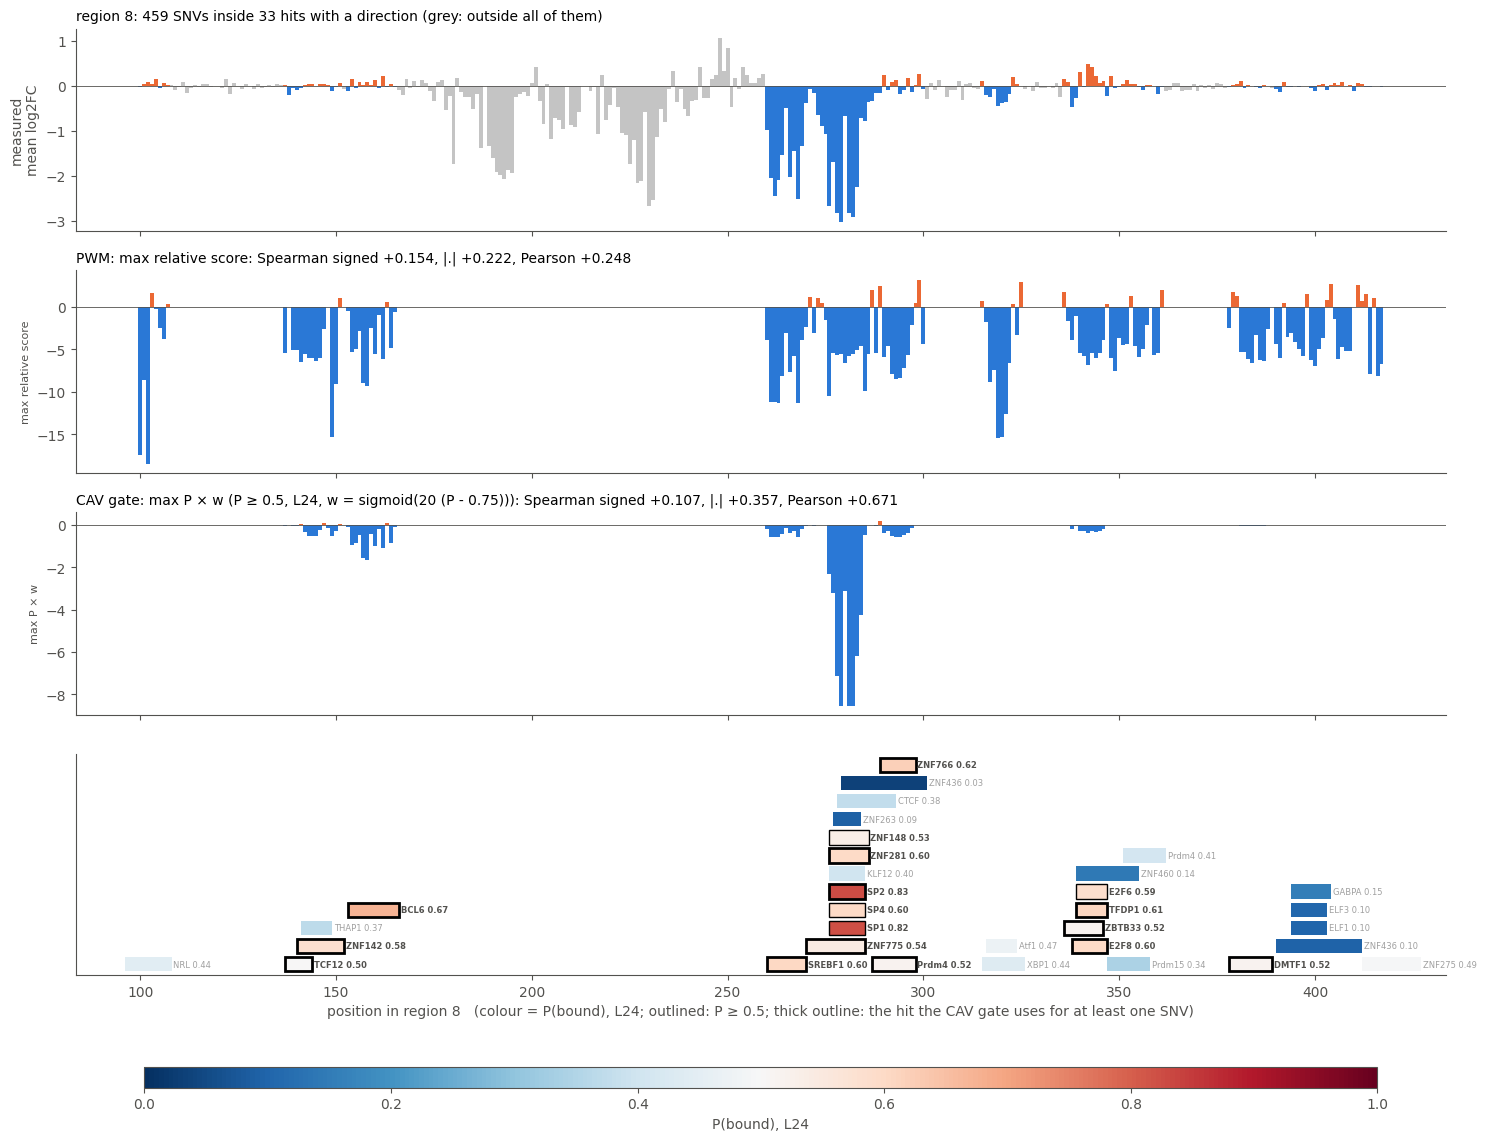

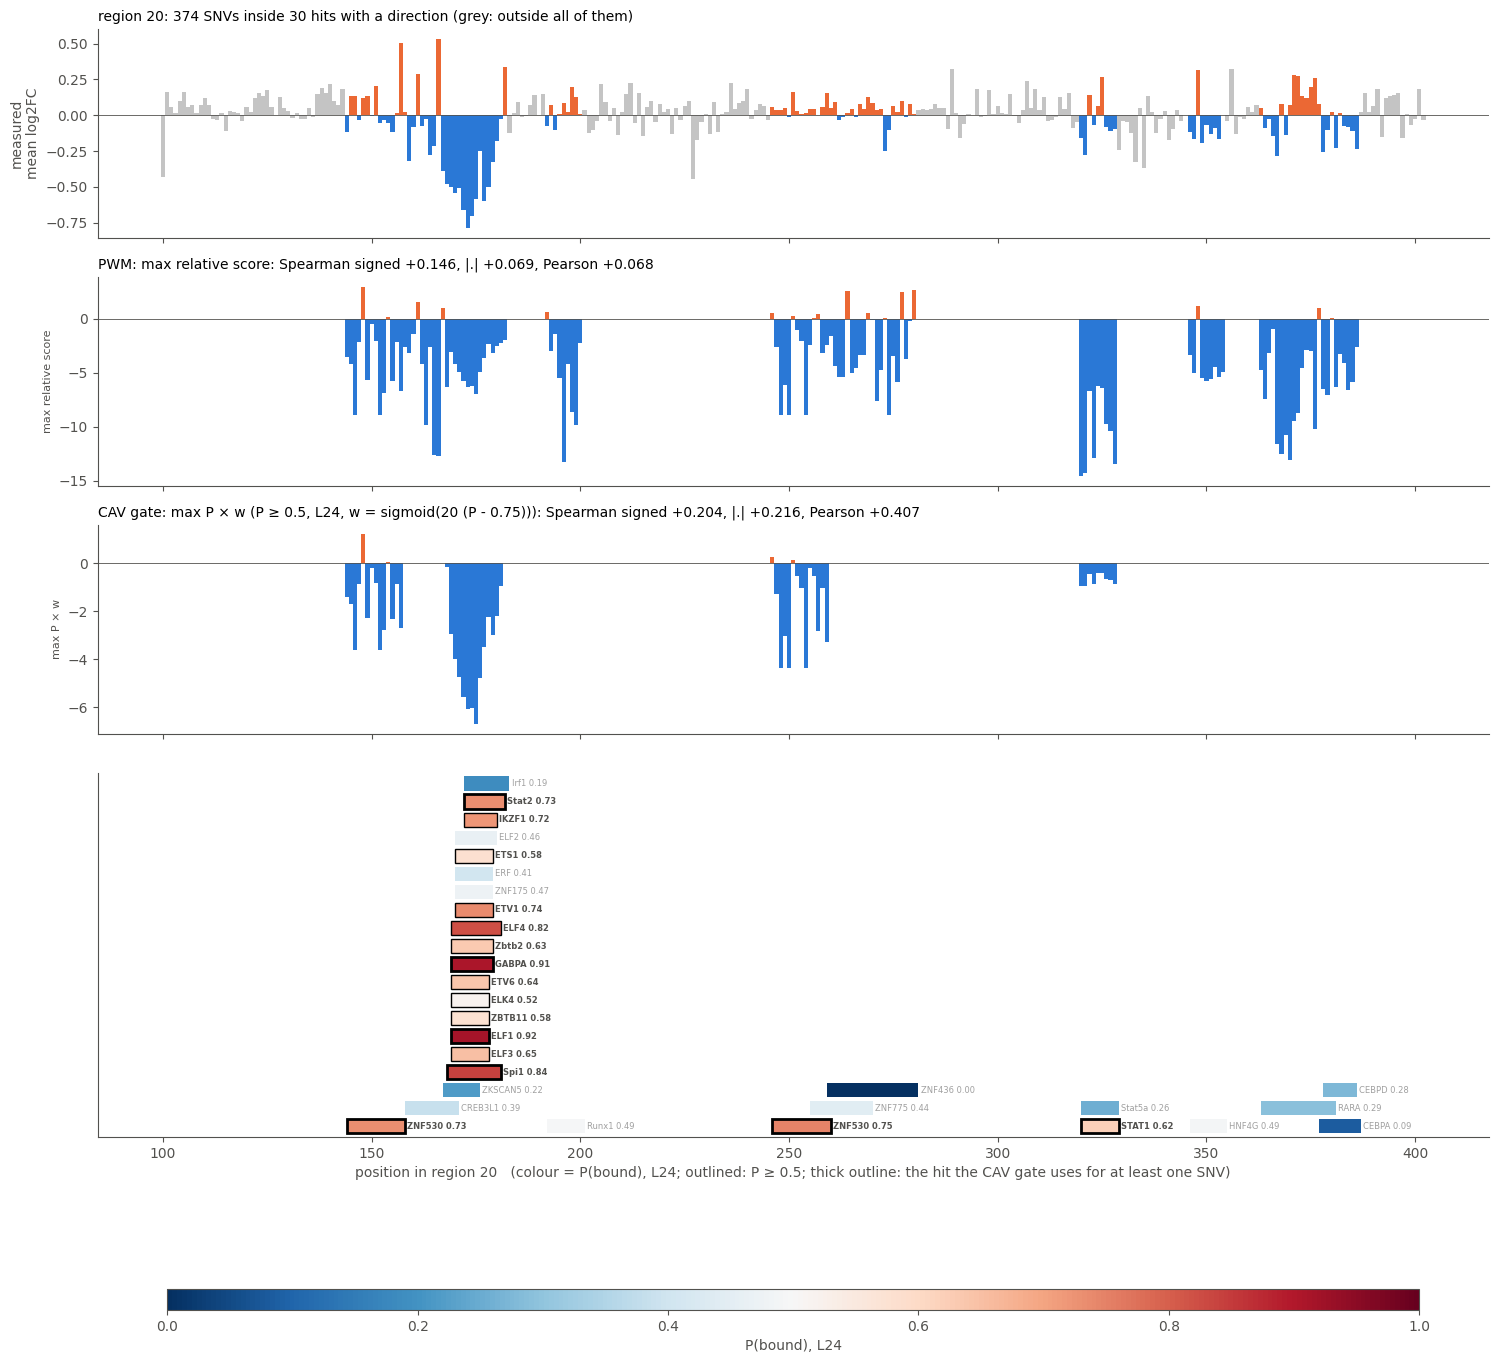

In [27]:
# CAV gate vs the strongest PWM-only rules on the MPRA, regions 0 / 8 / 20. One cell; data load cached, change settings and rerun.
# Principle: every rule uses at most ONE motif hit per SNV (and the choice never depends on the alt base).
TH = 0.5                      # CAV gate: hits with P(bound) < TH are dropped
MID, K = 0.75, 20             # weight w(P) = sigmoid(K * (P - MID))
LP = 24                       # layer of P(bound)
OCC_A, OCC_C = 10, 0.8        # occupancy occ(s) = sigmoid(OCC_A * (s - OCC_C)), s = PWM score / the motif's max score
N_PERM = 1000                 # shuffles for the CAV nulls (N1: across hits; N2: within motif)
PLOT = ("PWM: max relative score", "CAV gate: max P × w")   # the two rules drawn in the track figures
GRID_GATE = dict(TH=[0.5, 0.55, 0.6, 0.65, 0.7], MID=[0.6, 0.65, 0.7, 0.75, 0.8], K=[5, 10, 20, 40])
GRID_OCC = dict(A=[2, 5, 10, 20, 40], C=[0.5, 0.6, 0.7, 0.8, 0.9])
WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"

import os, json, itertools
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

pd.set_option("display.width", 250)
INK, C1, C2, GREY = "#52514e", "#2a78d6", "#eb6834", "#c4c4c4"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK})
OUT = f"{WORK_DIR}/hit_selection"
os.makedirs(OUT, exist_ok=True)
REG = {0: ("fcav_pgc_hk_r0", "fcav_pgc_hk_lr_r0"), 8: ("fcav_pgc_hk", "fcav_pgc_hk_lr"),
       20: ("fcav_pgc_hk_r20", "fcav_pgc_hk_lr_r20")}


# ---------- data (loaded once per session) ----------
def _rows(q, hits, mx):
    # SNV x hit rows sorted by SNV then hit_id (= FIMO p order), with group starts
    q = q.sort_values(["snv", "hit_id"]).reset_index(drop=True)
    sn = q["snv"].values
    m = hits.loc[q["hit_id"], "motif"].values
    return dict(sn=sn, st=np.r_[0, np.flatnonzero(sn[1:] != sn[:-1]) + 1], hid=q["hit_id"].values, dp=q["dpwm"].values,
                rel=hits.loc[q["hit_id"], "rel"].values, mx=np.array([mx[x] for x in m]))


if "D_GATE2" not in globals() or set(D_GATE2) != set(REG):     # (re)load if missing or incomplete
    try:
        from pymemesuite.common import MotifFile
    except ImportError:
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymemesuite"], check=True)
        from pymemesuite.common import MotifFile
    C = json.load(open(f"{WORK_DIR}/config.json"))
    with MotifFile(C["meme_path"]) as _mf:
        _all = list(_mf)
    _MOTIF = {}
    for m in _all:
        _MOTIF.setdefault(m.name.decode(), m)

    def _max_score(name):
        f = np.asarray(_MOTIF[name].frequencies, float)
        f = f / f.sum(1, keepdims=True)
        return float(np.log2(np.clip(f, 1e-9, 1.0) / 0.25).max(1).sum())

    _D = {}
    for r, (src, fit) in REG.items():
        S_, F_ = f"{WORK_DIR}/{src}", f"{WORK_DIR}/{fit}"
        mwj = json.load(open(f"{S_}/mpra_windows.json"))
        tfs = sorted(m for m, s in mwj["status"].items() if s == "built" and os.path.exists(f"{F_}/fits/{m}.npz"))
        fits = {m: np.load(f"{F_}/fits/{m}.npz") for m in tfs}
        layers = list(fits[tfs[0]]["layers"])
        dec = pd.concat([pd.DataFrame(fits[m]["dec_hit"], index=fits[m]["hit_id"], columns=layers) for m in tfs])
        hits = pd.read_csv(f"{S_}/hits.csv").set_index("hit_id")
        mx = {m: _max_score(m) for m in hits["motif"].unique()}
        hits["rel"] = hits["pwm"] / hits["motif"].map(mx)
        snv = pd.read_csv(f"{S_}/snvs.csv")
        pair = pd.read_csv(f"{S_}/snv_hit_dpwm.csv")
        q = pair[pair["hit_id"].isin(dec.index)]
        d = _rows(q, hits, mx)                                      # hits with a direction
        hs = np.array(sorted(q["hit_id"].unique()))
        d.update(P=1 / (1 + np.exp(-dec.loc[hs])), hs=hs, motif=hits.loc[hs, "motif"].values, hits=hits, snv=snv,
                 hi=np.searchsorted(hs, d["hid"]), rel_hit=hits.loc[hs, "rel"].values)
        d["y"] = snv.loc[d["sn"][d["st"]], "log2FC"].values
        d["local"] = snv.loc[d["sn"][d["st"]], "local"].values
        d["all"] = _rows(pair[pair["snv"].isin(d["sn"][d["st"]])], hits, mx)   # every JASPAR hit, same SNVs
        assert (d["all"]["sn"][d["all"]["st"]] == d["sn"][d["st"]]).all()
        _D[r] = d
        print(f"region {r:2d}: {len(tfs)} TFs, {len(hs)} hits with a direction, {len(d['st'])} SNVs inside them; "
              f"{len(np.unique(d['all']['hid']))} JASPAR hits of any motif cover these SNVs")
    D_GATE2 = _D                  # only once every region has loaded
D = D_GATE2
assert set(D) == set(REG), f"regions loaded: {sorted(D)}"


# ---------- rules (one hit per SNV, chosen from per-hit quantities only) ----------
def _first_by(e, key):
    # per SNV, the row with the largest key (ties: smallest hit_id = smallest FIMO p)
    return np.lexsort((e["hid"], -key, e["sn"]))[e["st"]]


def _sig(x):
    return 1 / (1 + np.exp(-x))


def pwm_rules(d, a=OCC_A, c=OCC_C):
    out = {}
    for tag, e in (("PWM", d), ("PWM all hits", d["all"])):
        iR = _first_by(e, e["rel"])
        docc = _sig(a * (e["rel"] + e["dp"] / e["mx"] - c)) - _sig(a * (e["rel"] - c))
        out[f"{tag}: best p"] = e["dp"][e["st"]]
        out[f"{tag}: max relative score"] = e["dp"][iR]
        out[f"{tag}: max relative score, Δocc"] = docc[iR]
    return out


def gate_rules(d, s_hit, prefix, th=TH, mid=MID, k=K):
    # drop hits with s < th; among the rest the hit with the highest s; ΔPWM, × s or × w(s); 0 if none is left
    g = s_hit[d["hi"]]
    kept = g >= th
    iP = _first_by(d, np.where(kept, g, -1.0))
    ok = kept[iP]
    return {f"{prefix}: max P": np.where(ok, d["dp"][iP], 0.0),
            f"{prefix}: max P × P": np.where(ok, d["dp"][iP] * g[iP], 0.0),
            f"{prefix}: max P × w": np.where(ok, d["dp"][iP] * _sig(k * (g[iP] - mid)), 0.0)}


def rank_as_P(p_hit, key_hit):
    # the CAV's own P values handed to the hits in the order of key_hit (largest key gets the largest P)
    out = np.empty_like(p_hit)
    out[np.argsort(key_hit, kind="stable")] = np.sort(p_hit)
    return out


def predict(d, p_hit, **kw):
    out = pwm_rules(d)
    out.update(gate_rules(d, p_hit, "CAV gate", **kw))
    out.update(gate_rules(d, rank_as_P(p_hit, d["rel_hit"]), "PWM-rank gate", **kw))
    out.update(gate_rules(d, rank_as_P(p_hit, -d["hs"].astype(float)), "p-rank gate", **kw))
    return out


RULES = list(predict(D[8], D[8]["P"][LP].values))
CAV = [k for k in RULES if k.startswith("CAV")]
METRICS = ["Spearman signed", "Spearman |.|", "Pearson signed"]


def scores(pred, y):
    if np.std(pred) == 0:
        return np.array([np.nan] * 3)
    return np.array([stats.spearmanr(pred, y)[0], stats.spearmanr(np.abs(pred), np.abs(y))[0], stats.pearsonr(pred, y)[0]])


def mean_scores(fn):
    # fn(d, region) -> {rule: prediction}; returns {rule: 3-region mean of the metrics}
    acc = {}
    for r, d in D.items():
        for k, v in fn(d, r).items():
            acc.setdefault(k, []).append(scores(v, d["y"]))
    return {k: np.mean(v, 0) for k, v in acc.items()}


GROUPS = {}
for r, d in D.items():
    for i, m in enumerate(d["motif"]):
        GROUPS.setdefault(m, []).append((r, i))


def perm_global(rng):
    return {r: rng.permutation(d["P"][LP].values) for r, d in D.items()}


def perm_motif(rng):
    out = {r: d["P"][LP].values.copy() for r, d in D.items()}
    for mem in GROUPS.values():
        if len(mem) > 1:
            vals = np.array([D[r]["P"][LP].values[i] for r, i in mem])[rng.permutation(len(mem))]
            for (r, i), v in zip(mem, vals):
                out[r][i] = v
    return out


# ---------- 1. fixed settings: every rule, CAV nulls ----------
rng = np.random.default_rng(0)
PL = {r: d["P"][LP].values for r, d in D.items()}
obs = mean_scores(lambda d, r: predict(d, PL[r]))
per_region = {r: {k: scores(v, d["y"]) for k, v in predict(d, PL[r]).items()} for r, d in D.items()}
cav_only = lambda pm: mean_scores(lambda d, r: gate_rules(d, pm[r], "CAV gate"))
n1 = np.array([[v for v in cav_only(perm_global(rng)).values()] for _ in range(N_PERM)])     # (perm, rule, metric)
n2 = np.array([[v for v in cav_only(perm_motif(rng)).values()] for _ in range(N_PERM)])
rows = []
for k in RULES:
    row = {"rule": k}
    for j, mt in enumerate(METRICS):
        row[mt] = obs[k][j]
        if k in CAV:
            ki = CAV.index(k)
            row[f"{mt}: null N1"], row[f"{mt}: p N1"] = np.nanmean(n1[:, ki, j]), np.mean(n1[:, ki, j] >= row[mt])
            row[f"{mt}: null N2"], row[f"{mt}: p N2"] = np.nanmean(n2[:, ki, j]), np.mean(n2[:, ki, j] >= row[mt])
    rows.append(row)
T = pd.DataFrame(rows).set_index("rule")
tag = f"th{TH}_w{MID}-{K}_occ{OCC_A}-{OCC_C}_L{LP}"
T.to_csv(f"{OUT}/onehit_{tag}.csv")
print(f"\n=== fixed settings: P ≥ {TH}, w = sigmoid({K} (P - {MID})), occ = sigmoid({OCC_A} (s - {OCC_C})), layer {LP}; "
      f"mean over regions {' / '.join(map(str, D))}; nulls {N_PERM} shuffles\n")
for mt in METRICS:
    cols = [mt] + [c for c in T.columns if c.startswith(mt + ":")]
    print(f"--- {mt}")
    print(T[cols].rename(columns=lambda c: c.replace(mt + ": ", "")).to_string(float_format=lambda x: f"{x:+.3f}", na_rep=""))
    print()
print("--- per region")
print(pd.DataFrame({(k, f"r{r}"): per_region[r][k] for k in RULES for r in D}, index=METRICS).T
      .unstack(1).to_string(float_format=lambda x: f"{x:+.3f}"))
for r, d in D.items():
    nk = np.add.reduceat((PL[r] >= TH)[d["hi"]].astype(int), d["st"])
    print(f"region {r}: {int((PL[r] >= TH).sum())} of {len(PL[r])} hits kept by the CAV gate; {int((nk == 0).sum())} of {len(nk)} SNVs predicted 0")

# ---------- 2. tuned on these three regions: the best each family can reach ----------
best = []
for a, c in itertools.product(GRID_OCC["A"], GRID_OCC["C"]):
    s = mean_scores(lambda d, r: {k: v for k, v in pwm_rules(d, a, c).items() if "Δocc" in k})
    for k, v in s.items():
        best.append({"family": k, "setting": f"A={a}, C={c}", **dict(zip(METRICS, v))})
for th, mid, k_ in itertools.product(GRID_GATE["TH"], GRID_GATE["MID"], GRID_GATE["K"]):
    s = mean_scores(lambda d, r: {**gate_rules(d, PL[r], "CAV gate", th, mid, k_),
                                  **gate_rules(d, rank_as_P(PL[r], d["rel_hit"]), "PWM-rank gate", th, mid, k_),
                                  **gate_rules(d, rank_as_P(PL[r], -d["hs"].astype(float)), "p-rank gate", th, mid, k_)})
    for k, v in s.items():
        best.append({"family": k, "setting": f"TH={th}" + (f", MID={mid}, K={k_}" if k.endswith("× w") else ""), **dict(zip(METRICS, v))})
B = pd.DataFrame(best).drop_duplicates(["family", "setting"])
B.to_csv(f"{OUT}/onehit_grid_L{LP}.csv", index=False)
print("\n=== best setting per rule, tuned on these three regions (generous to every rule; the CAV row at the fixed setting "
      "is in the table above)")
for mt in METRICS:
    t = B.loc[B.groupby("family")[mt].idxmax()].set_index("family")[["setting", mt]].sort_values(mt, ascending=False)
    fixed = pd.Series({k: obs[k][METRICS.index(mt)] for k in t.index}, name="at fixed setting")
    print(f"--- {mt}")
    print(t.join(fixed).to_string(float_format=lambda x: f"{x:+.3f}"))
    print()

# ---------- 3. track figures ----------
cm, nm = plt.get_cmap("RdBu_r"), mcolors.TwoSlopeNorm(vmin=0, vcenter=0.5, vmax=1)
col = lambda v: np.where(v < 0, C1, C2)
for r, d in D.items():
    p = PL[r]
    pr = predict(d, p)
    S = pd.DataFrame({"local": d["local"], "y": d["y"], "a": pr[PLOT[0]], "b": pr[PLOT[1]]})
    pos_all = d["snv"].groupby("local")["log2FC"].mean()
    pos = S.groupby("local")[["a", "b"]].mean()
    sc = {k: scores(S[k].values, S["y"].values) for k in ("a", "b")}
    g = p[d["hi"]]
    iP = _first_by(d, np.where(g >= TH, g, -1.0))
    used = set(d["hid"][iP][(g >= TH)[iP]])

    hh = d["hits"].loc[d["hs"], ["motif", "start", "end"]].copy()
    hh["hit_id"], hh["P"] = d["hs"], p
    hh = hh.sort_values(["start", "end"]).reset_index(drop=True)
    hh["label"] = [f"{m} {q:.2f}" for m, q in zip(hh["motif"], hh["P"])]
    span = pos_all.index.max() - pos_all.index.min() + 1
    ends, lane = [], []
    for a_, b_, lab in zip(hh["start"], hh["end"], hh["label"]):
        b_ = b_ + 1 + 0.0045 * span * len(lab)
        kk = next((i for i, e in enumerate(ends) if e <= a_), len(ends))
        if kk == len(ends):
            ends.append(b_)
        else:
            ends[kk] = b_
        lane.append(kk)
    nrow = max(lane) + 1 if lane else 1

    fig, ax = plt.subplots(4, 1, figsize=(15, 8 + 0.3 * nrow), sharex=True,
                           gridspec_kw={"height_ratios": [2.2, 2.2, 2.2, 0.3 * nrow + 0.4]})
    ax[0].bar(pos_all.index, pos_all.values, width=1, color=np.where(~pos_all.index.isin(pos.index), GREY, col(pos_all.values)))
    ax[0].set_ylabel("measured\nmean log2FC")
    ax[0].set_title(f"region {r}: {len(S)} SNVs inside {len(d['hs'])} hits with a direction (grey: outside all of them)",
                    loc="left", fontsize=10)
    for a, k, name in ((ax[1], "a", PLOT[0]), (ax[2], "b", PLOT[1])):
        a.bar(pos.index, pos[k].values, width=1, color=col(pos[k].values))
        a.set_ylabel(name.split(": ")[1], fontsize=8)
        extra = f" (P ≥ {TH}, L{LP}" + (f", w = sigmoid({K} (P - {MID}))" if name.endswith("w") else "") + ")" if "gate" in name else ""
        a.set_title(f"{name}{extra}: Spearman signed {sc[k][0]:+.3f}, |.| {sc[k][1]:+.3f}, Pearson {sc[k][2]:+.3f}",
                    loc="left", fontsize=10)
    for a in ax[:3]:
        a.axhline(0, color=INK, lw=.6)
    for (_, h), kk in zip(hh.iterrows(), lane):
        kept = h["P"] >= TH
        lw = 2.0 if h["hit_id"] in used else (1.0 if kept else 0)
        ax[3].add_patch(plt.Rectangle((h["start"], kk), h["end"] - h["start"], 0.8, facecolor=cm(nm(h["P"])),
                                      edgecolor="black" if kept else "none", linewidth=lw))
        ax[3].text(h["end"] + 0.5, kk + 0.4, h["label"], va="center", fontsize=6, color=INK if kept else "#a0a0a0",
                   fontweight="bold" if kept else "normal")
    ax[3].set_ylim(-0.2, nrow); ax[3].set_yticks([])
    ax[3].set_xlabel(f"position in region {r}   (colour = P(bound), L{LP}; outlined: P ≥ {TH}; "
                     f"thick outline: the hit the CAV gate uses for at least one SNV)")
    fig.colorbar(plt.cm.ScalarMappable(norm=nm, cmap=cm), ax=ax[3], shrink=.9, label=f"P(bound), L{LP}",
                 orientation="horizontal", pad=0.25, aspect=60)
    plt.tight_layout()
    plt.savefig(f"{OUT}/track_r{r}_onehit_{tag}.png", dpi=150, bbox_inches="tight"); plt.show()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

=== fixed settings: P ≥ 0.6, w = sigmoid(20 (P - 0.75)), occ = sigmoid(10 (s - 0.8)), layer 24; mean over regions 0 / 8 / 20; nulls 1000 shuffles

--- Spearman signed
                                        Spearman signed  null N1   p N1  null N2   p N2
rule                                                                                   
PWM: best p                                      +0.068                                
PWM: max relative score                          +0.104                                
PWM: max relative score, Δocc                    +0.262                                
PWM all hits: best p                             +0.122                                
PWM all hits: max relative score                 +0.121                                
PWM all hits: max relative score, Δocc           +0.238                                

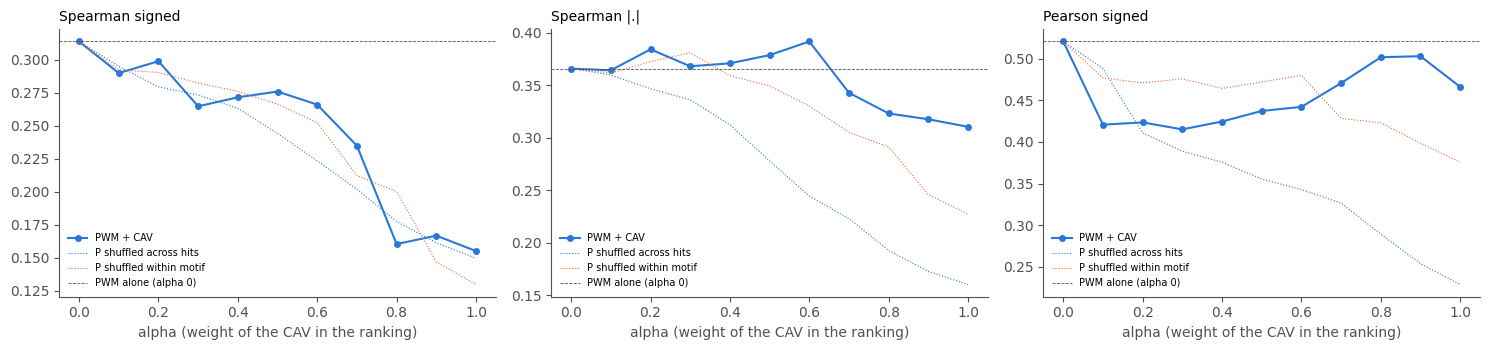


=== best setting per rule, tuned on these three regions (generous to every rule; the CAV row at the fixed setting is in the table above)
--- Spearman signed
                                                      setting  Spearman signed  at fixed setting
family                                                                                          
PWM-rank gate: max P × w                TH=0.7, MID=0.8, K=20           +0.358            +0.314
PWM-rank gate: max P × P                               TH=0.7           +0.352            +0.309
PWM-rank gate: max P                                   TH=0.7           +0.351            +0.302
PWM+CAV-rank gate: max P × w            TH=0.65, MID=0.8, K=5           +0.297            +0.276
PWM+CAV-rank gate: max P × P                          TH=0.65           +0.296            +0.275
PWM+CAV-rank gate: max P                              TH=0.65           +0.294            +0.273
PWM: max relative score, Δocc                     A=40, C=0.9     

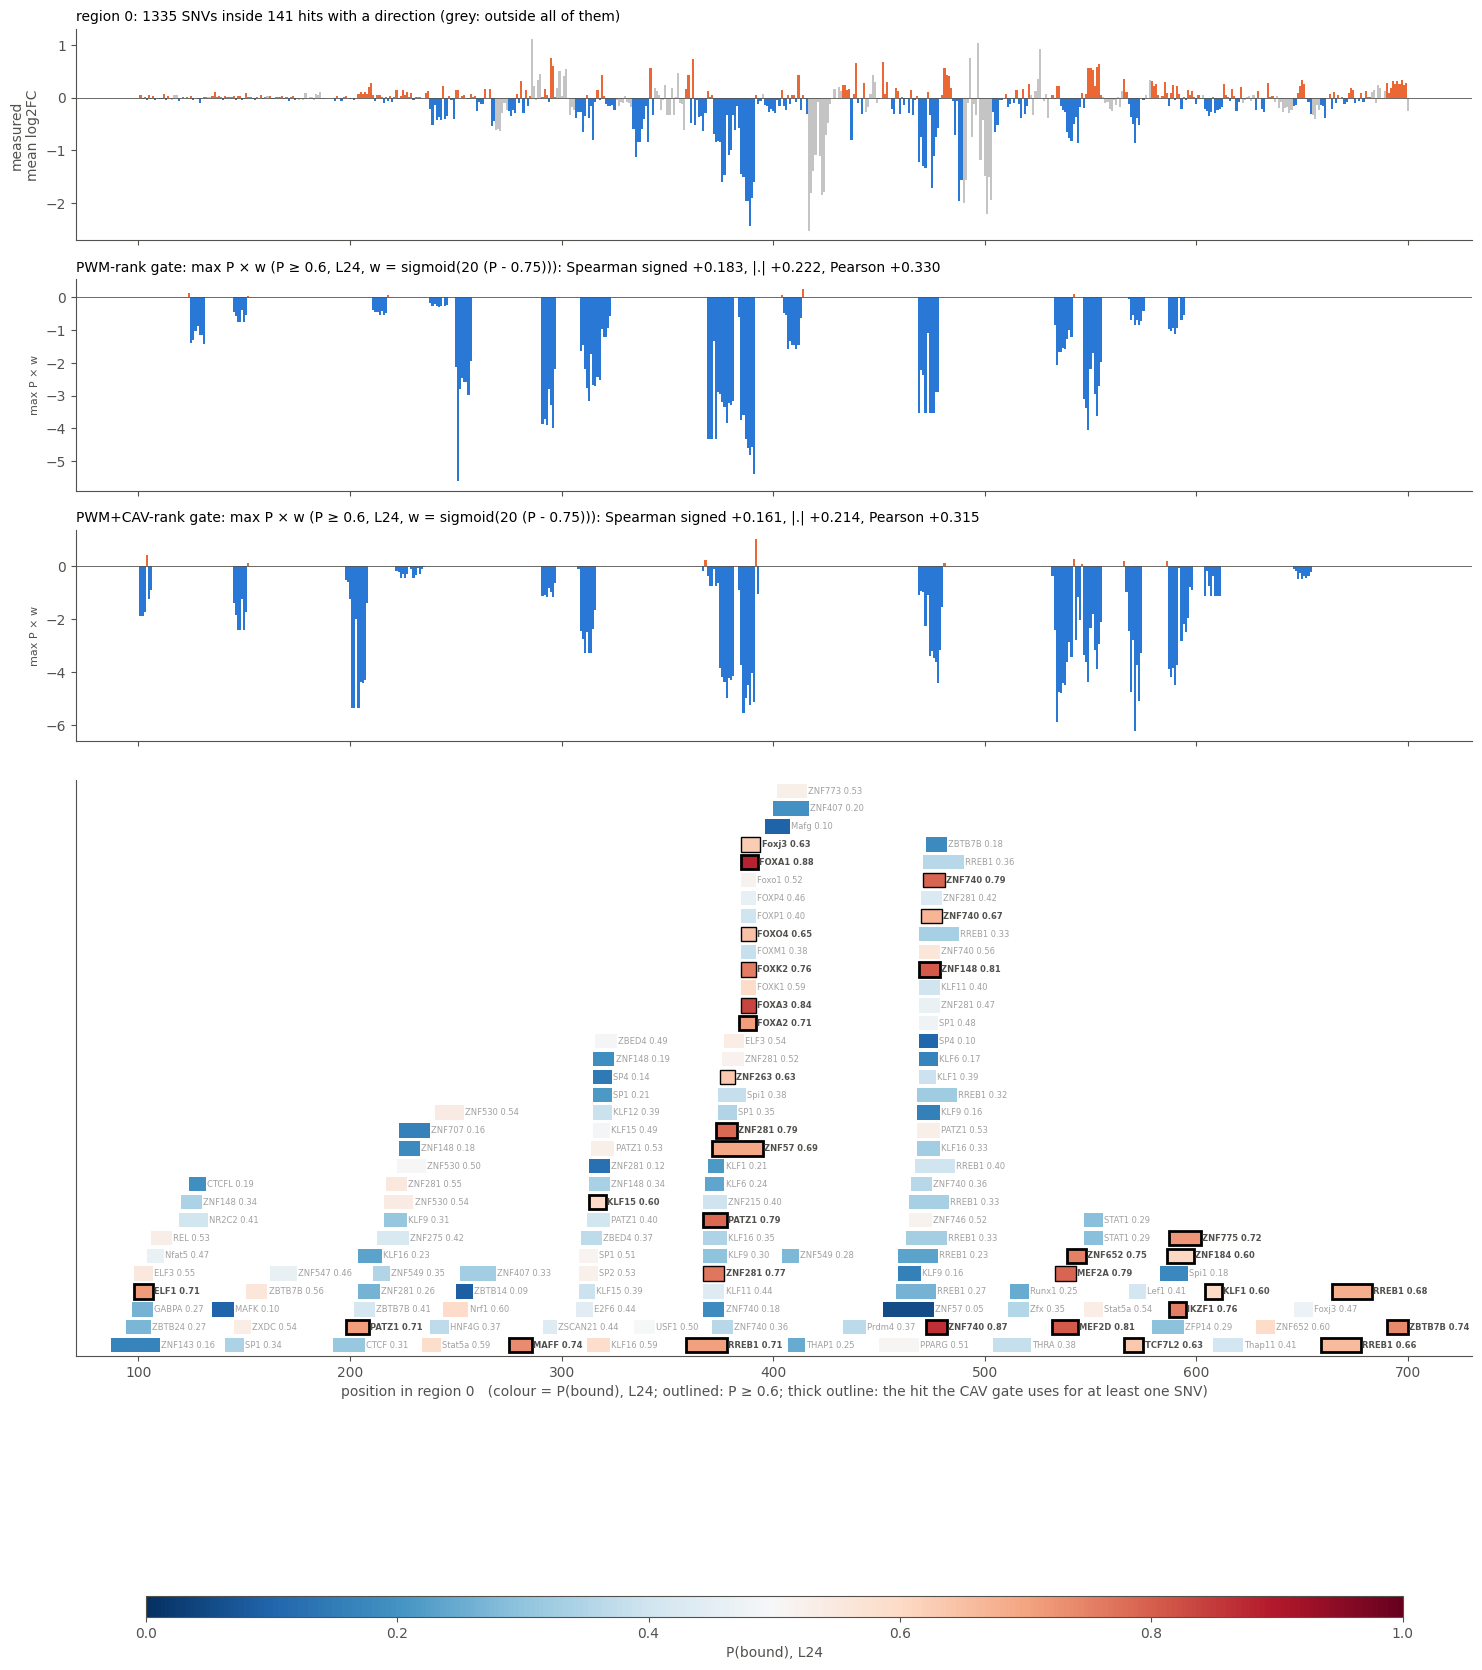

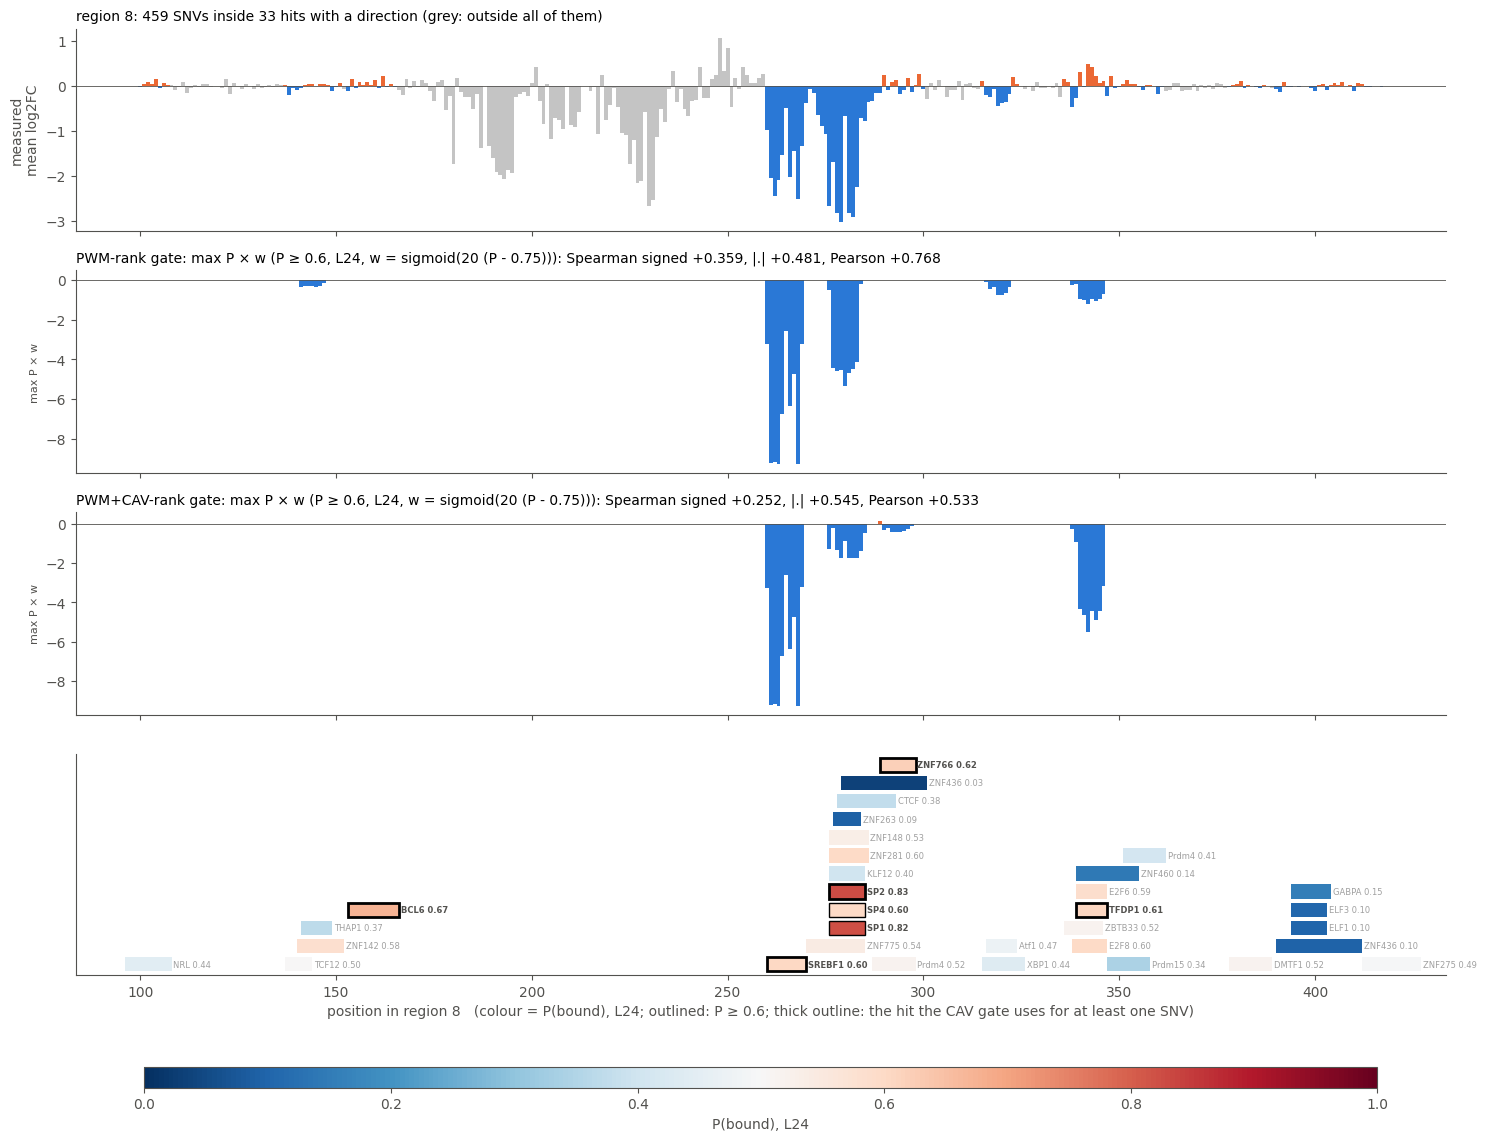

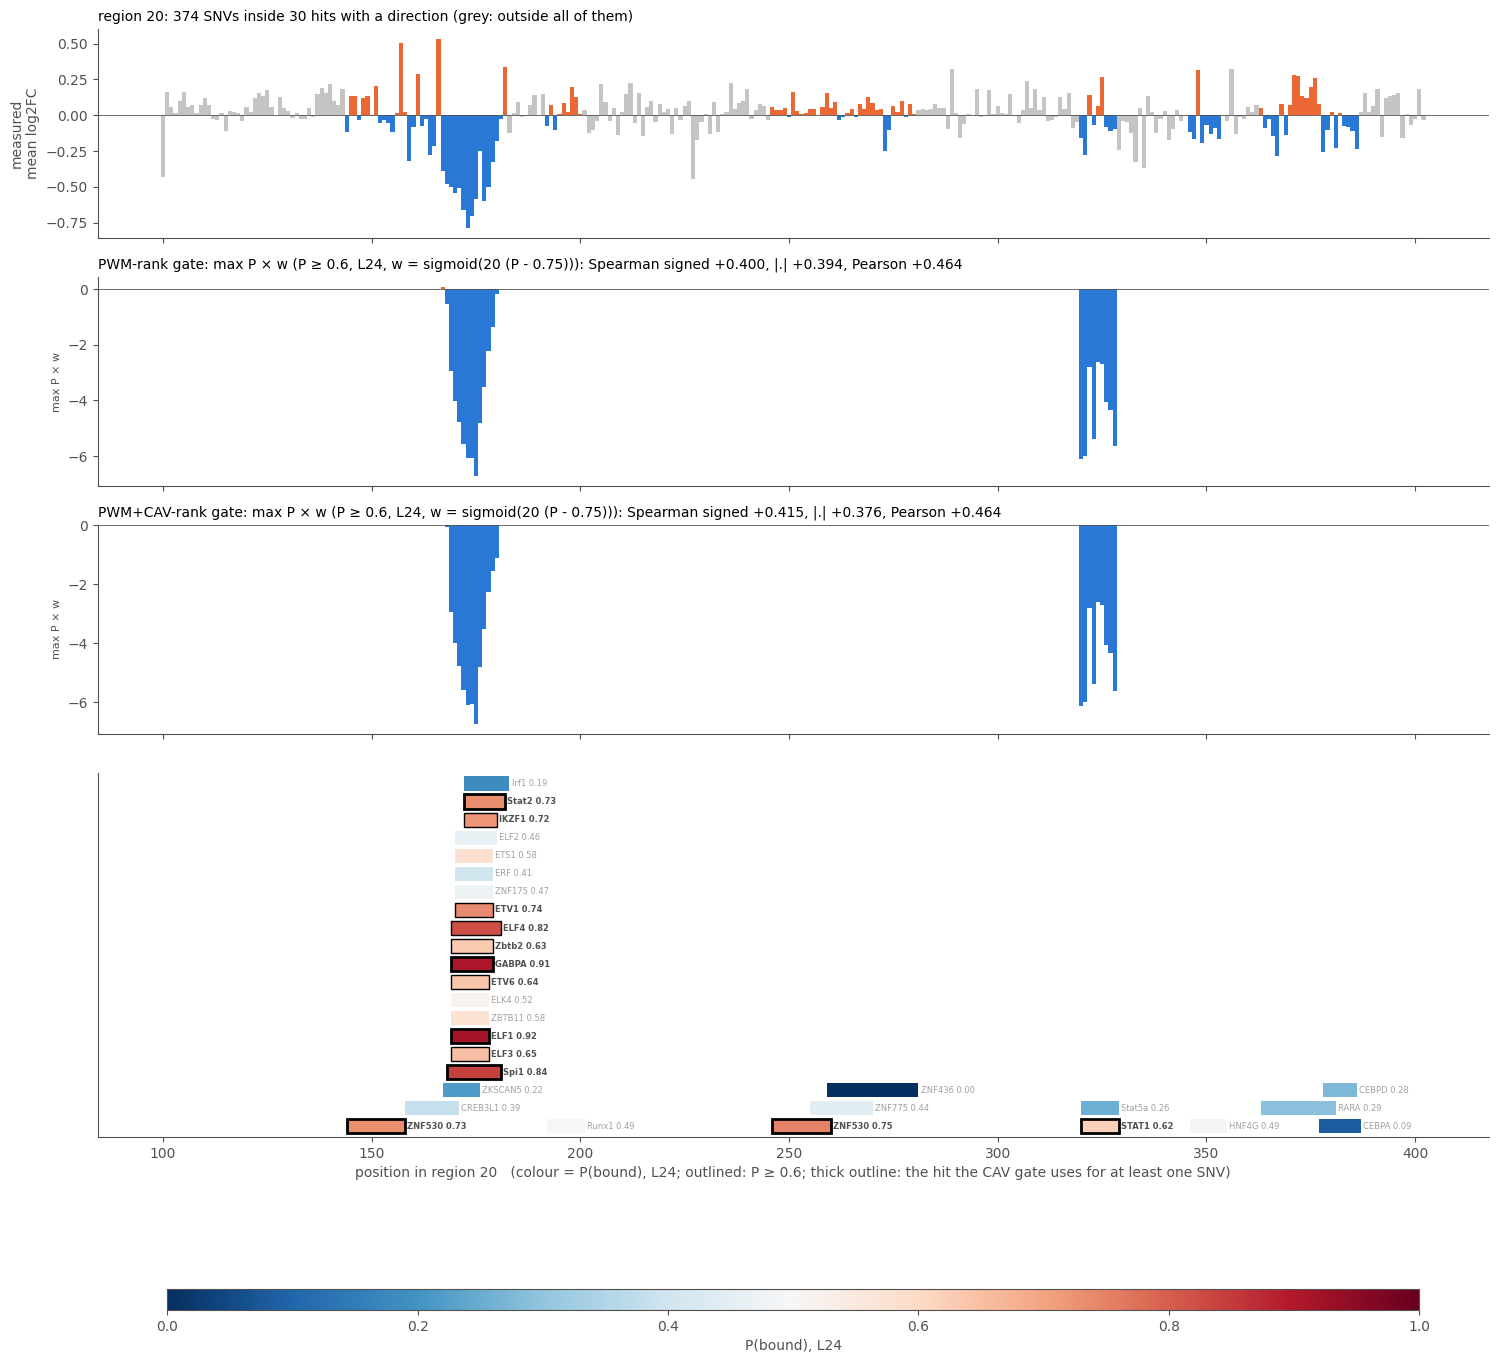

In [30]:
# CAV gate vs the strongest PWM-only rules on the MPRA, regions 0 / 8 / 20. One cell; data load cached, change settings and rerun.
# Principle: every rule uses at most ONE motif hit per SNV (and the choice never depends on the alt base).
TH = 0.6                      # CAV gate: hits with P(bound) < TH are dropped
MID, K = 0.75, 20             # weight w(P) = sigmoid(K * (P - MID))
LP = 24                       # layer of P(bound)
ALPHA = 0.5                   # PWM+CAV ranking: (1 - ALPHA) * rank(relative PWM score) + ALPHA * rank(P); 0 = PWM only, 1 = CAV only
ALPHAS = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]   # the curve in part 2b
N_PERM_CURVE = 200            # shuffles per alpha in part 2b
OCC_A, OCC_C = 10, 0.8        # occupancy occ(s) = sigmoid(OCC_A * (s - OCC_C)), s = PWM score / the motif's max score
N_PERM = 1000                 # shuffles for the CAV nulls (N1: across hits; N2: within motif)
PLOT = ("PWM-rank gate: max P × w", "PWM+CAV-rank gate: max P × w")   # the two rules drawn in the track figures
GRID_GATE = dict(TH=[0.5, 0.55, 0.6, 0.65, 0.7], MID=[0.6, 0.65, 0.7, 0.75, 0.8], K=[5, 10, 20, 40])
GRID_OCC = dict(A=[2, 5, 10, 20, 40], C=[0.5, 0.6, 0.7, 0.8, 0.9])
WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"

import os, json, itertools
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

pd.set_option("display.width", 250)
INK, C1, C2, GREY = "#52514e", "#2a78d6", "#eb6834", "#c4c4c4"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK})
OUT = f"{WORK_DIR}/hit_selection"
os.makedirs(OUT, exist_ok=True)
REG = {0: ("fcav_pgc_hk_r0", "fcav_pgc_hk_lr_r0"), 8: ("fcav_pgc_hk", "fcav_pgc_hk_lr"),
       20: ("fcav_pgc_hk_r20", "fcav_pgc_hk_lr_r20")}


# ---------- data (loaded once per session) ----------
def _rows(q, hits, mx):
    # SNV x hit rows sorted by SNV then hit_id (= FIMO p order), with group starts
    q = q.sort_values(["snv", "hit_id"]).reset_index(drop=True)
    sn = q["snv"].values
    m = hits.loc[q["hit_id"], "motif"].values
    return dict(sn=sn, st=np.r_[0, np.flatnonzero(sn[1:] != sn[:-1]) + 1], hid=q["hit_id"].values, dp=q["dpwm"].values,
                rel=hits.loc[q["hit_id"], "rel"].values, mx=np.array([mx[x] for x in m]))


if "D_GATE2" not in globals() or set(D_GATE2) != set(REG):     # (re)load if missing or incomplete
    try:
        from pymemesuite.common import MotifFile
    except ImportError:
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymemesuite"], check=True)
        from pymemesuite.common import MotifFile
    C = json.load(open(f"{WORK_DIR}/config.json"))
    with MotifFile(C["meme_path"]) as _mf:
        _all = list(_mf)
    _MOTIF = {}
    for m in _all:
        _MOTIF.setdefault(m.name.decode(), m)

    def _max_score(name):
        f = np.asarray(_MOTIF[name].frequencies, float)
        f = f / f.sum(1, keepdims=True)
        return float(np.log2(np.clip(f, 1e-9, 1.0) / 0.25).max(1).sum())

    _D = {}
    for r, (src, fit) in REG.items():
        S_, F_ = f"{WORK_DIR}/{src}", f"{WORK_DIR}/{fit}"
        mwj = json.load(open(f"{S_}/mpra_windows.json"))
        tfs = sorted(m for m, s in mwj["status"].items() if s == "built" and os.path.exists(f"{F_}/fits/{m}.npz"))
        fits = {m: np.load(f"{F_}/fits/{m}.npz") for m in tfs}
        layers = list(fits[tfs[0]]["layers"])
        dec = pd.concat([pd.DataFrame(fits[m]["dec_hit"], index=fits[m]["hit_id"], columns=layers) for m in tfs])
        hits = pd.read_csv(f"{S_}/hits.csv").set_index("hit_id")
        mx = {m: _max_score(m) for m in hits["motif"].unique()}
        hits["rel"] = hits["pwm"] / hits["motif"].map(mx)
        snv = pd.read_csv(f"{S_}/snvs.csv")
        pair = pd.read_csv(f"{S_}/snv_hit_dpwm.csv")
        q = pair[pair["hit_id"].isin(dec.index)]
        d = _rows(q, hits, mx)                                      # hits with a direction
        hs = np.array(sorted(q["hit_id"].unique()))
        d.update(P=1 / (1 + np.exp(-dec.loc[hs])), hs=hs, motif=hits.loc[hs, "motif"].values, hits=hits, snv=snv,
                 hi=np.searchsorted(hs, d["hid"]), rel_hit=hits.loc[hs, "rel"].values)
        d["y"] = snv.loc[d["sn"][d["st"]], "log2FC"].values
        d["local"] = snv.loc[d["sn"][d["st"]], "local"].values
        d["all"] = _rows(pair[pair["snv"].isin(d["sn"][d["st"]])], hits, mx)   # every JASPAR hit, same SNVs
        assert (d["all"]["sn"][d["all"]["st"]] == d["sn"][d["st"]]).all()
        _D[r] = d
        print(f"region {r:2d}: {len(tfs)} TFs, {len(hs)} hits with a direction, {len(d['st'])} SNVs inside them; "
              f"{len(np.unique(d['all']['hid']))} JASPAR hits of any motif cover these SNVs")
    D_GATE2 = _D                  # only once every region has loaded
D = D_GATE2
assert set(D) == set(REG), f"regions loaded: {sorted(D)}"


# ---------- rules (one hit per SNV, chosen from per-hit quantities only) ----------
def _first_by(e, key):
    # per SNV, the row with the largest key (ties: smallest hit_id = smallest FIMO p)
    return np.lexsort((e["hid"], -key, e["sn"]))[e["st"]]


def _sig(x):
    return 1 / (1 + np.exp(-x))


def pwm_rules(d, a=OCC_A, c=OCC_C):
    out = {}
    for tag, e in (("PWM", d), ("PWM all hits", d["all"])):
        iR = _first_by(e, e["rel"])
        docc = _sig(a * (e["rel"] + e["dp"] / e["mx"] - c)) - _sig(a * (e["rel"] - c))
        out[f"{tag}: best p"] = e["dp"][e["st"]]
        out[f"{tag}: max relative score"] = e["dp"][iR]
        out[f"{tag}: max relative score, Δocc"] = docc[iR]
    return out


def gate_rules(d, s_hit, prefix, th=TH, mid=MID, k=K):
    # drop hits with s < th; among the rest the hit with the highest s; ΔPWM, × s or × w(s); 0 if none is left
    g = s_hit[d["hi"]]
    kept = g >= th
    iP = _first_by(d, np.where(kept, g, -1.0))
    ok = kept[iP]
    return {f"{prefix}: max P": np.where(ok, d["dp"][iP], 0.0),
            f"{prefix}: max P × P": np.where(ok, d["dp"][iP] * g[iP], 0.0),
            f"{prefix}: max P × w": np.where(ok, d["dp"][iP] * _sig(k * (g[iP] - mid)), 0.0)}


def rank_as_P(p_hit, key_hit):
    # the CAV's own P values handed to the hits in the order of key_hit (largest key gets the largest P)
    out = np.empty_like(p_hit)
    out[np.argsort(key_hit, kind="stable")] = np.sort(p_hit)
    return out


def combo_key(d, p_hit, alpha=ALPHA):
    # per-hit ranking key mixing the relative PWM score and the CAV's P, both as within-region ranks in (0, 1]
    n = len(p_hit)
    return (1 - alpha) * stats.rankdata(d["rel_hit"]) / n + alpha * stats.rankdata(p_hit) / n


def combo_rules(d, p_hit, alpha=ALPHA, p_vals=None, **kw):
    # the gate with the hits ranked by PWM + CAV (p_hit only sets the ranking); the values handed out in that order are
    # the region's real P values (p_vals), so a shuffled P changes the ranking only, never how many hits are kept
    vals = p_hit if p_vals is None else p_vals
    return gate_rules(d, rank_as_P(vals, combo_key(d, p_hit, alpha)), "PWM+CAV-rank gate", **kw)


def predict(d, p_hit, **kw):
    out = pwm_rules(d)
    out.update(gate_rules(d, p_hit, "CAV gate", **kw))
    out.update(gate_rules(d, p_hit, "CAV no gate", **{**kw, "th": 0.0}))     # every hit kept; only w(P) shrinks
    out.update(combo_rules(d, p_hit, **kw))
    out.update(gate_rules(d, rank_as_P(p_hit, d["rel_hit"]), "PWM-rank gate", **kw))
    out.update(gate_rules(d, rank_as_P(p_hit, -d["hs"].astype(float)), "p-rank gate", **kw))
    return out


RULES = list(predict(D[8], D[8]["P"][LP].values))
CAV = [k for k in RULES if k.startswith(("CAV", "PWM+CAV"))]     # rules that use the CAV: nulls shuffle P
METRICS = ["Spearman signed", "Spearman |.|", "Pearson signed"]


def scores(pred, y):
    if np.std(pred) == 0:
        return np.array([np.nan] * 3)
    return np.array([stats.spearmanr(pred, y)[0], stats.spearmanr(np.abs(pred), np.abs(y))[0], stats.pearsonr(pred, y)[0]])


def mean_scores(fn):
    # fn(d, region) -> {rule: prediction}; returns {rule: 3-region mean of the metrics}
    acc = {}
    for r, d in D.items():
        for k, v in fn(d, r).items():
            acc.setdefault(k, []).append(scores(v, d["y"]))
    return {k: np.mean(v, 0) for k, v in acc.items()}


GROUPS = {}
for r, d in D.items():
    for i, m in enumerate(d["motif"]):
        GROUPS.setdefault(m, []).append((r, i))


def perm_global(rng):
    return {r: rng.permutation(d["P"][LP].values) for r, d in D.items()}


def perm_motif(rng):
    out = {r: d["P"][LP].values.copy() for r, d in D.items()}
    for mem in GROUPS.values():
        if len(mem) > 1:
            vals = np.array([D[r]["P"][LP].values[i] for r, i in mem])[rng.permutation(len(mem))]
            for (r, i), v in zip(mem, vals):
                out[r][i] = v
    return out


# ---------- 1. fixed settings: every rule, CAV nulls ----------
rng = np.random.default_rng(0)
PL = {r: d["P"][LP].values for r, d in D.items()}
obs = mean_scores(lambda d, r: predict(d, PL[r]))
per_region = {r: {k: scores(v, d["y"]) for k, v in predict(d, PL[r]).items()} for r, d in D.items()}
cav_only = lambda pm: mean_scores(lambda d, r: {**gate_rules(d, pm[r], "CAV gate"), **gate_rules(d, pm[r], "CAV no gate", th=0.0),
                                                **combo_rules(d, pm[r], p_vals=PL[r])})
n1 = np.array([[v for v in cav_only(perm_global(rng)).values()] for _ in range(N_PERM)])     # (perm, rule, metric)
n2 = np.array([[v for v in cav_only(perm_motif(rng)).values()] for _ in range(N_PERM)])
rows = []
for k in RULES:
    row = {"rule": k}
    for j, mt in enumerate(METRICS):
        row[mt] = obs[k][j]
        if k in CAV:
            ki = CAV.index(k)
            row[f"{mt}: null N1"], row[f"{mt}: p N1"] = np.nanmean(n1[:, ki, j]), np.mean(n1[:, ki, j] >= row[mt])
            row[f"{mt}: null N2"], row[f"{mt}: p N2"] = np.nanmean(n2[:, ki, j]), np.mean(n2[:, ki, j] >= row[mt])
    rows.append(row)
T = pd.DataFrame(rows).set_index("rule")
tag = f"th{TH}_w{MID}-{K}_occ{OCC_A}-{OCC_C}_L{LP}"
T.to_csv(f"{OUT}/onehit_{tag}.csv")
print(f"\n=== fixed settings: P ≥ {TH}, w = sigmoid({K} (P - {MID})), occ = sigmoid({OCC_A} (s - {OCC_C})), layer {LP}; "
      f"mean over regions {' / '.join(map(str, D))}; nulls {N_PERM} shuffles\n")
for mt in METRICS:
    cols = [mt] + [c for c in T.columns if c.startswith(mt + ":")]
    print(f"--- {mt}")
    print(T[cols].rename(columns=lambda c: c.replace(mt + ": ", "")).to_string(float_format=lambda x: f"{x:+.3f}", na_rep=""))
    print()
print("--- per region")
print(pd.DataFrame({(k, f"r{r}"): per_region[r][k] for k in RULES for r in D}, index=METRICS).T
      .unstack(1).to_string(float_format=lambda x: f"{x:+.3f}"))
for r, d in D.items():
    nk = np.add.reduceat((PL[r] >= TH)[d["hi"]].astype(int), d["st"])
    print(f"region {r}: {int((PL[r] >= TH).sum())} of {len(PL[r])} hits kept by the CAV gate; {int((nk == 0).sum())} of {len(nk)} SNVs predicted 0")

# ---------- 2b. does the CAV add to the PWM? mixing weight alpha, gate rule "max P × w" at the fixed settings ----------
# alpha = 0 is the PWM-rank gate, alpha = 1 the CAV gate. Null for every alpha: P shuffled (N1 across hits, N2 within
# motif) while the PWM scores stay: tests whether the CAV's ranking adds to the PWM's.
KEY = "PWM+CAV-rank gate: max P × w"
rows = []
for al in ALPHAS:
    f = lambda pm: mean_scores(lambda d, r: {KEY: combo_rules(d, pm[r], al, p_vals=PL[r])[KEY]})[KEY]
    o = f(PL)
    a1 = np.array([f(perm_global(rng)) for _ in range(N_PERM_CURVE)])
    a2 = np.array([f(perm_motif(rng)) for _ in range(N_PERM_CURVE)])
    for j, mt in enumerate(METRICS):
        rows.append({"alpha": al, "metric": mt, "obs": o[j], "null N1": np.nanmean(a1[:, j]), "p N1": np.mean(a1[:, j] >= o[j]),
                     "null N2": np.nanmean(a2[:, j]), "p N2": np.mean(a2[:, j] >= o[j])})
AC = pd.DataFrame(rows)
AC.to_csv(f"{OUT}/combo_alpha_{tag}.csv", index=False)
print(f"\n=== PWM + CAV ranking, rule max P × w, fixed settings; alpha 0 = PWM-rank gate, 1 = CAV gate; nulls {N_PERM_CURVE} shuffles\n")
for mt in METRICS:
    t = AC[AC.metric == mt].set_index("alpha").drop(columns="metric")
    base = t.loc[0, "obs"]
    print(f"--- {mt} (PWM alone, alpha 0: {base:+.3f})")
    print(t.assign(**{"vs PWM alone": t["obs"] - base}).T.to_string(float_format=lambda x: f"{x:+.3f}"))
    print()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, mt in zip(ax, METRICS):
    t = AC[AC.metric == mt]
    a.plot(t.alpha, t.obs, c="#2a78d6", marker="o", ms=4, label="PWM + CAV")
    a.plot(t.alpha, t["null N1"], c="#2a78d6", lw=.8, ls=":", label="P shuffled across hits")
    a.plot(t.alpha, t["null N2"], c="#eb6834", lw=.8, ls=":", label="P shuffled within motif")
    a.axhline(t.obs.iloc[0], c=INK, lw=.6, ls="--", label="PWM alone (alpha 0)")
    a.set_xlabel("alpha (weight of the CAV in the ranking)"); a.set_title(mt, loc="left", fontsize=10)
    a.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/combo_alpha_{tag}.png", dpi=150, bbox_inches="tight"); plt.show()

# ---------- 2. tuned on these three regions: the best each family can reach ----------
best = []
for a, c in itertools.product(GRID_OCC["A"], GRID_OCC["C"]):
    s = mean_scores(lambda d, r: {k: v for k, v in pwm_rules(d, a, c).items() if "Δocc" in k})
    for k, v in s.items():
        best.append({"family": k, "setting": f"A={a}, C={c}", **dict(zip(METRICS, v))})
for th, mid, k_ in itertools.product(GRID_GATE["TH"], GRID_GATE["MID"], GRID_GATE["K"]):
    s = mean_scores(lambda d, r: {**gate_rules(d, PL[r], "CAV gate", th, mid, k_),
                                  **gate_rules(d, rank_as_P(PL[r], d["rel_hit"]), "PWM-rank gate", th, mid, k_),
                                  **combo_rules(d, PL[r], ALPHA, th=th, mid=mid, k=k_),
                                  **gate_rules(d, rank_as_P(PL[r], -d["hs"].astype(float)), "p-rank gate", th, mid, k_)})
    for k, v in s.items():
        best.append({"family": k, "setting": f"TH={th}" + (f", MID={mid}, K={k_}" if k.endswith("× w") else ""), **dict(zip(METRICS, v))})
B = pd.DataFrame(best).drop_duplicates(["family", "setting"])
B.to_csv(f"{OUT}/onehit_grid_L{LP}.csv", index=False)
print("\n=== best setting per rule, tuned on these three regions (generous to every rule; the CAV row at the fixed setting "
      "is in the table above)")
for mt in METRICS:
    t = B.loc[B.groupby("family")[mt].idxmax()].set_index("family")[["setting", mt]].sort_values(mt, ascending=False)
    fixed = pd.Series({k: obs[k][METRICS.index(mt)] for k in t.index}, name="at fixed setting")
    print(f"--- {mt}")
    print(t.join(fixed).to_string(float_format=lambda x: f"{x:+.3f}"))
    print()

# ---------- 3. track figures ----------
cm, nm = plt.get_cmap("RdBu_r"), mcolors.TwoSlopeNorm(vmin=0, vcenter=0.5, vmax=1)
col = lambda v: np.where(v < 0, C1, C2)
for r, d in D.items():
    p = PL[r]
    pr = predict(d, p)
    S = pd.DataFrame({"local": d["local"], "y": d["y"], "a": pr[PLOT[0]], "b": pr[PLOT[1]]})
    pos_all = d["snv"].groupby("local")["log2FC"].mean()
    pos = S.groupby("local")[["a", "b"]].mean()
    sc = {k: scores(S[k].values, S["y"].values) for k in ("a", "b")}
    g = p[d["hi"]]
    iP = _first_by(d, np.where(g >= TH, g, -1.0))
    used = set(d["hid"][iP][(g >= TH)[iP]])

    hh = d["hits"].loc[d["hs"], ["motif", "start", "end"]].copy()
    hh["hit_id"], hh["P"] = d["hs"], p
    hh = hh.sort_values(["start", "end"]).reset_index(drop=True)
    hh["label"] = [f"{m} {q:.2f}" for m, q in zip(hh["motif"], hh["P"])]
    span = pos_all.index.max() - pos_all.index.min() + 1
    ends, lane = [], []
    for a_, b_, lab in zip(hh["start"], hh["end"], hh["label"]):
        b_ = b_ + 1 + 0.0045 * span * len(lab)
        kk = next((i for i, e in enumerate(ends) if e <= a_), len(ends))
        if kk == len(ends):
            ends.append(b_)
        else:
            ends[kk] = b_
        lane.append(kk)
    nrow = max(lane) + 1 if lane else 1

    fig, ax = plt.subplots(4, 1, figsize=(15, 8 + 0.3 * nrow), sharex=True,
                           gridspec_kw={"height_ratios": [2.2, 2.2, 2.2, 0.3 * nrow + 0.4]})
    ax[0].bar(pos_all.index, pos_all.values, width=1, color=np.where(~pos_all.index.isin(pos.index), GREY, col(pos_all.values)))
    ax[0].set_ylabel("measured\nmean log2FC")
    ax[0].set_title(f"region {r}: {len(S)} SNVs inside {len(d['hs'])} hits with a direction (grey: outside all of them)",
                    loc="left", fontsize=10)
    for a, k, name in ((ax[1], "a", PLOT[0]), (ax[2], "b", PLOT[1])):
        a.bar(pos.index, pos[k].values, width=1, color=col(pos[k].values))
        a.set_ylabel(name.split(": ")[1], fontsize=8)
        extra = f" (P ≥ {TH}, L{LP}" + (f", w = sigmoid({K} (P - {MID}))" if name.endswith("w") else "") + ")" if "gate" in name else ""
        a.set_title(f"{name}{extra}: Spearman signed {sc[k][0]:+.3f}, |.| {sc[k][1]:+.3f}, Pearson {sc[k][2]:+.3f}",
                    loc="left", fontsize=10)
    for a in ax[:3]:
        a.axhline(0, color=INK, lw=.6)
    for (_, h), kk in zip(hh.iterrows(), lane):
        kept = h["P"] >= TH
        lw = 2.0 if h["hit_id"] in used else (1.0 if kept else 0)
        ax[3].add_patch(plt.Rectangle((h["start"], kk), h["end"] - h["start"], 0.8, facecolor=cm(nm(h["P"])),
                                      edgecolor="black" if kept else "none", linewidth=lw))
        ax[3].text(h["end"] + 0.5, kk + 0.4, h["label"], va="center", fontsize=6, color=INK if kept else "#a0a0a0",
                   fontweight="bold" if kept else "normal")
    ax[3].set_ylim(-0.2, nrow); ax[3].set_yticks([])
    ax[3].set_xlabel(f"position in region {r}   (colour = P(bound), L{LP}; outlined: P ≥ {TH}; "
                     f"thick outline: the hit the CAV gate uses for at least one SNV)")
    fig.colorbar(plt.cm.ScalarMappable(norm=nm, cmap=cm), ax=ax[3], shrink=.9, label=f"P(bound), L{LP}",
                 orientation="horizontal", pad=0.25, aspect=60)
    plt.tight_layout()
    plt.savefig(f"{OUT}/track_r{r}_onehit_{tag}.png", dpi=150, bbox_inches="tight"); plt.show()



=== motifbreakR (threshold 0.85, non-neutral) vs CAV (P ≥ 0.6, w = sigmoid(20 (P - 0.75)), L24); same SNVs; mean over regions 0 / 8 / 20

                                                         Spearman signed  Spearman |.|  Pearson signed
rule                                                                                                  
motifbreakR: max |alleleDiff|                                     +0.074        +0.075          +0.098
motifbreakR: max pctRef                                           +0.036        +0.008          +0.099
motifbreakR: max |alleleDiff| (motifs with a direction)           +0.285        +0.223          +0.296
motifbreakR: max pctRef (motifs with a direction)                 +0.235        +0.164          +0.260
PWM: max relative score                                           +0.104        +0.111          +0.120
PWM: max relative score, Δocc                                     +0.262        +0.254          +0.408
CAV gate: max P × w                  

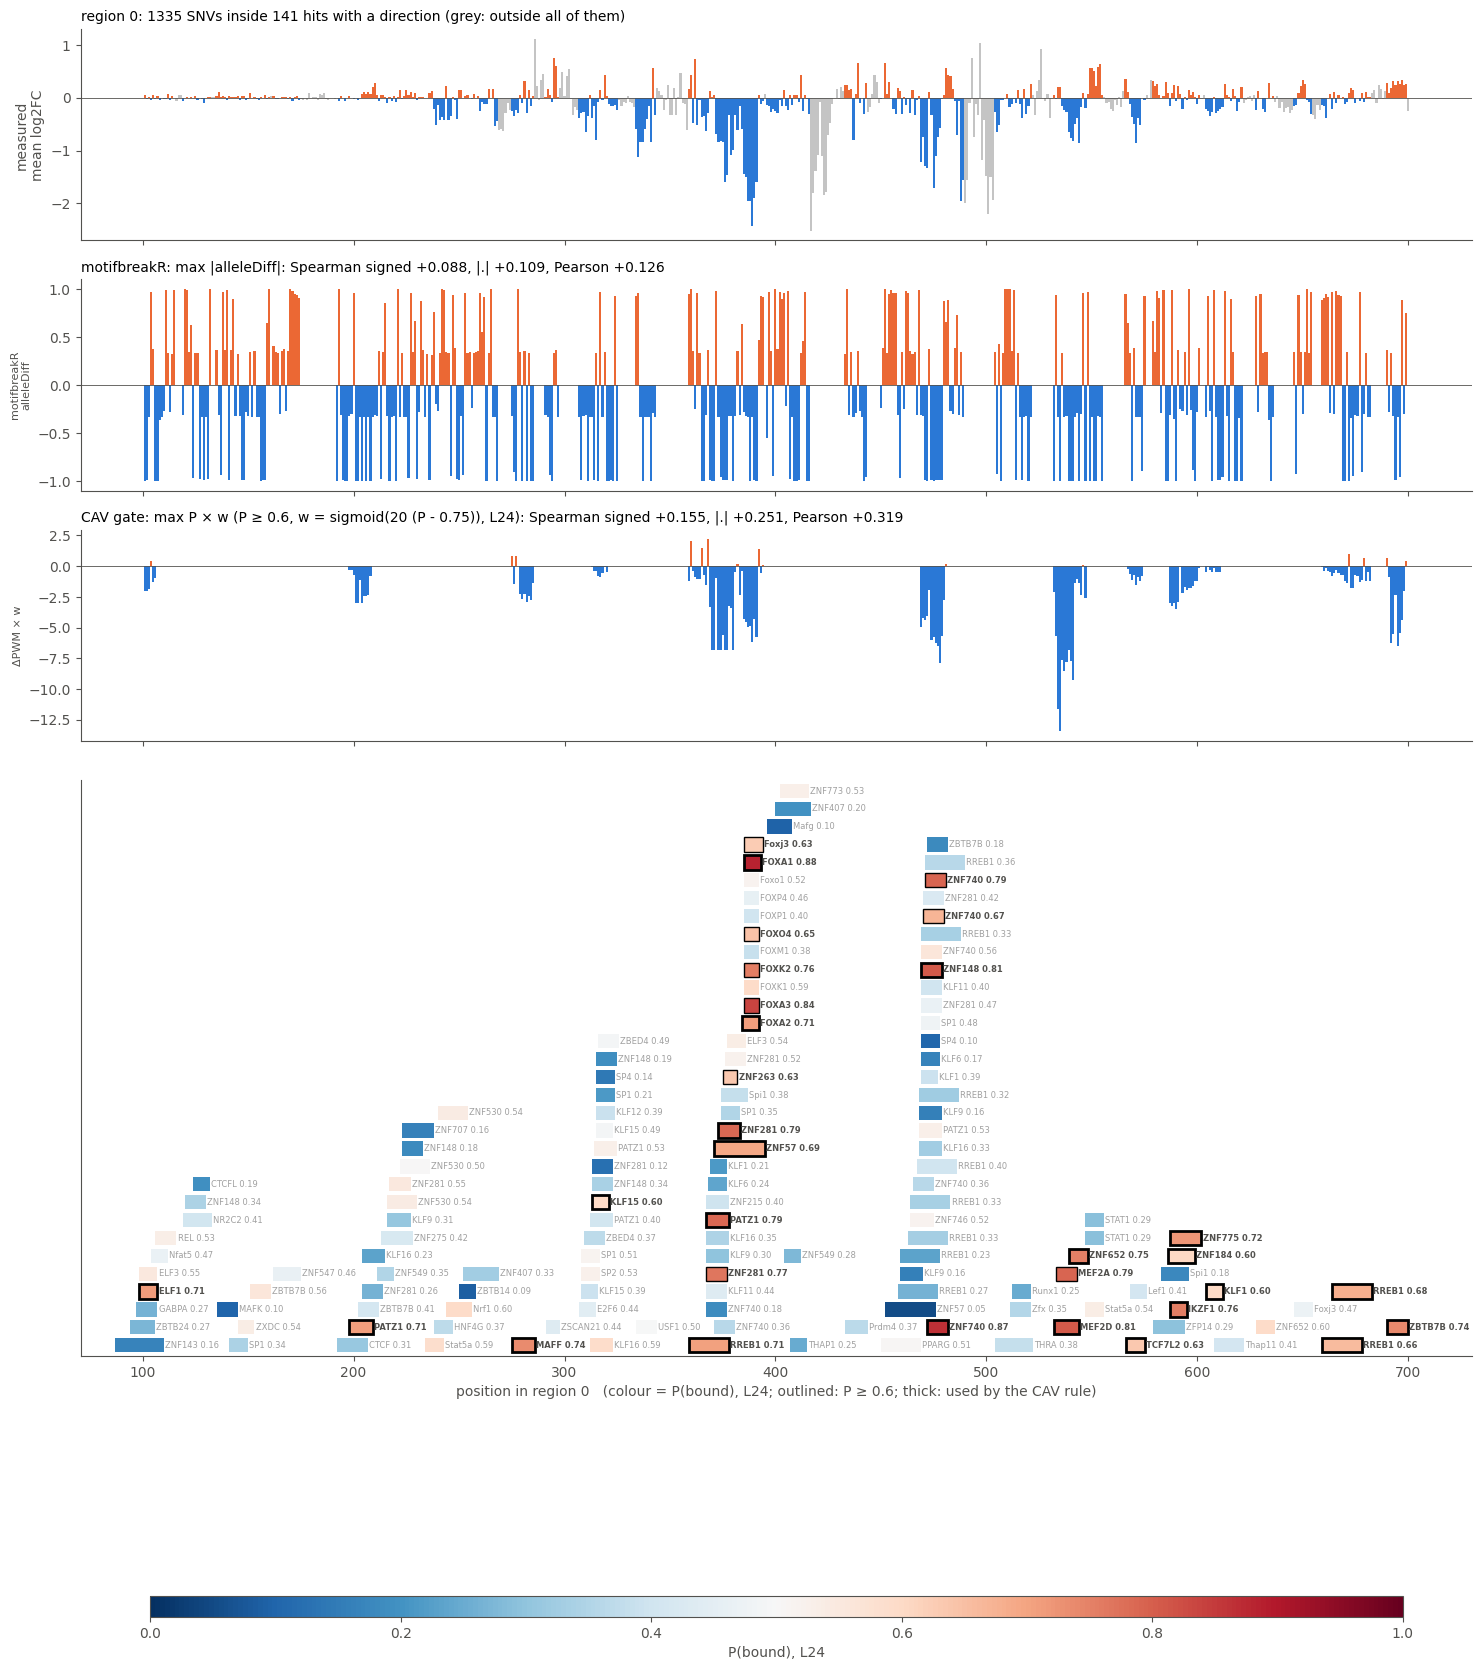

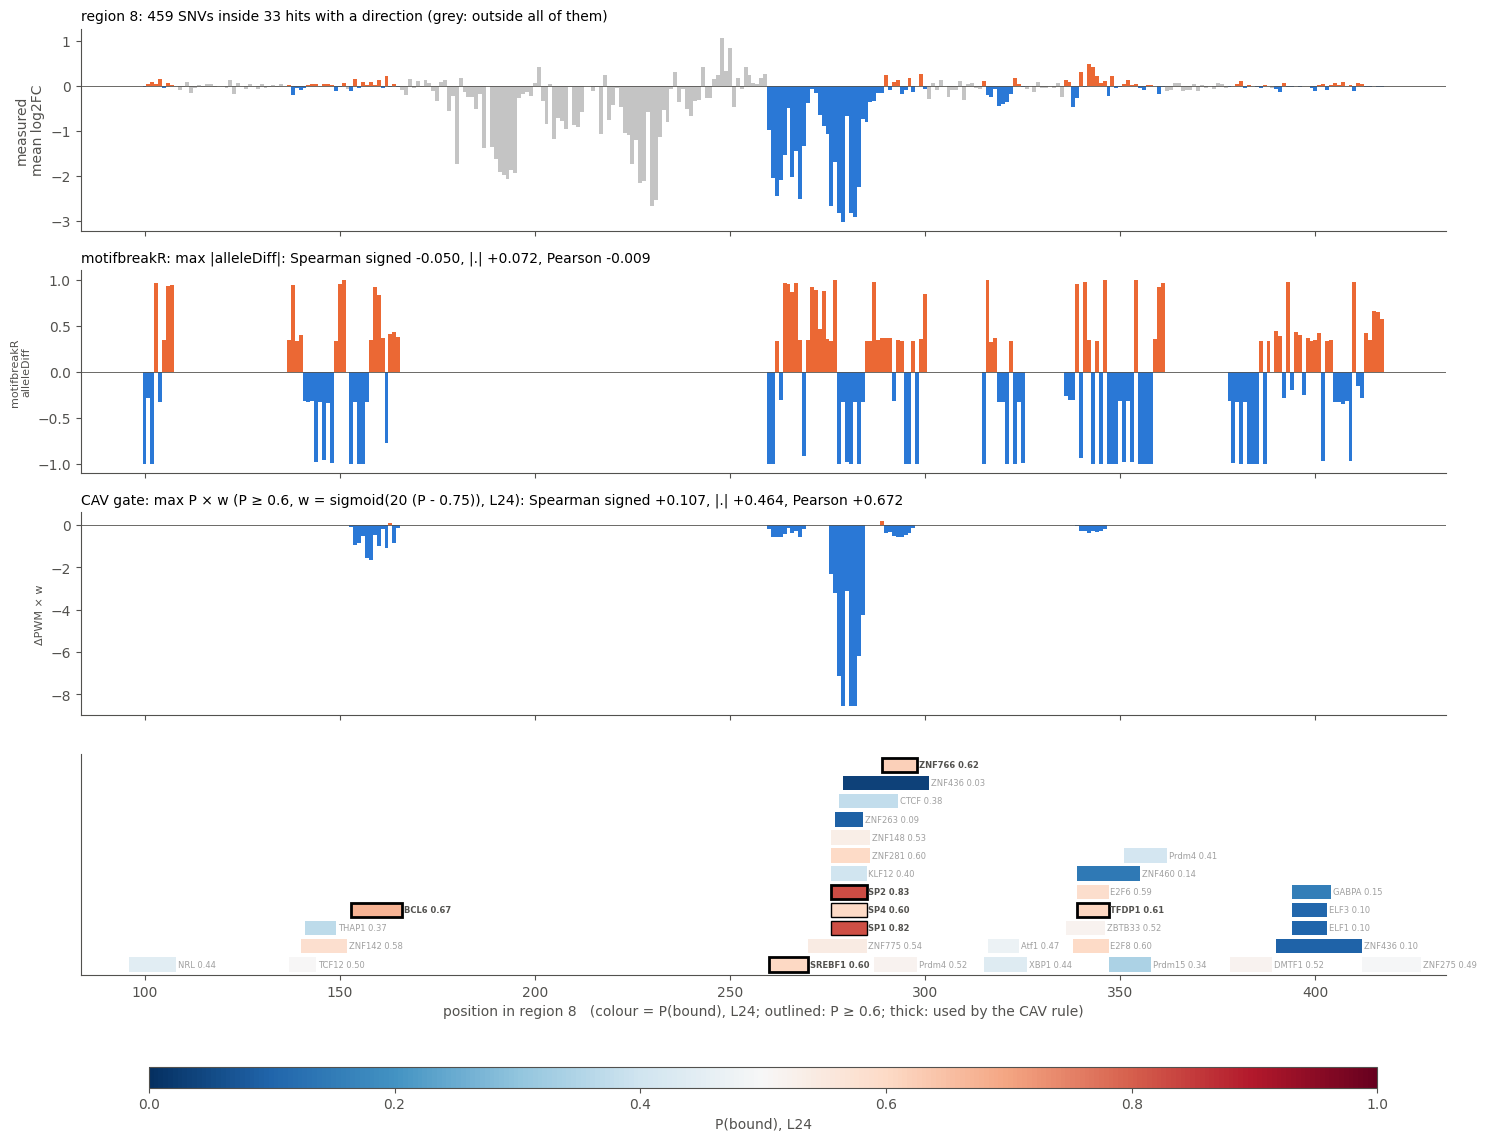

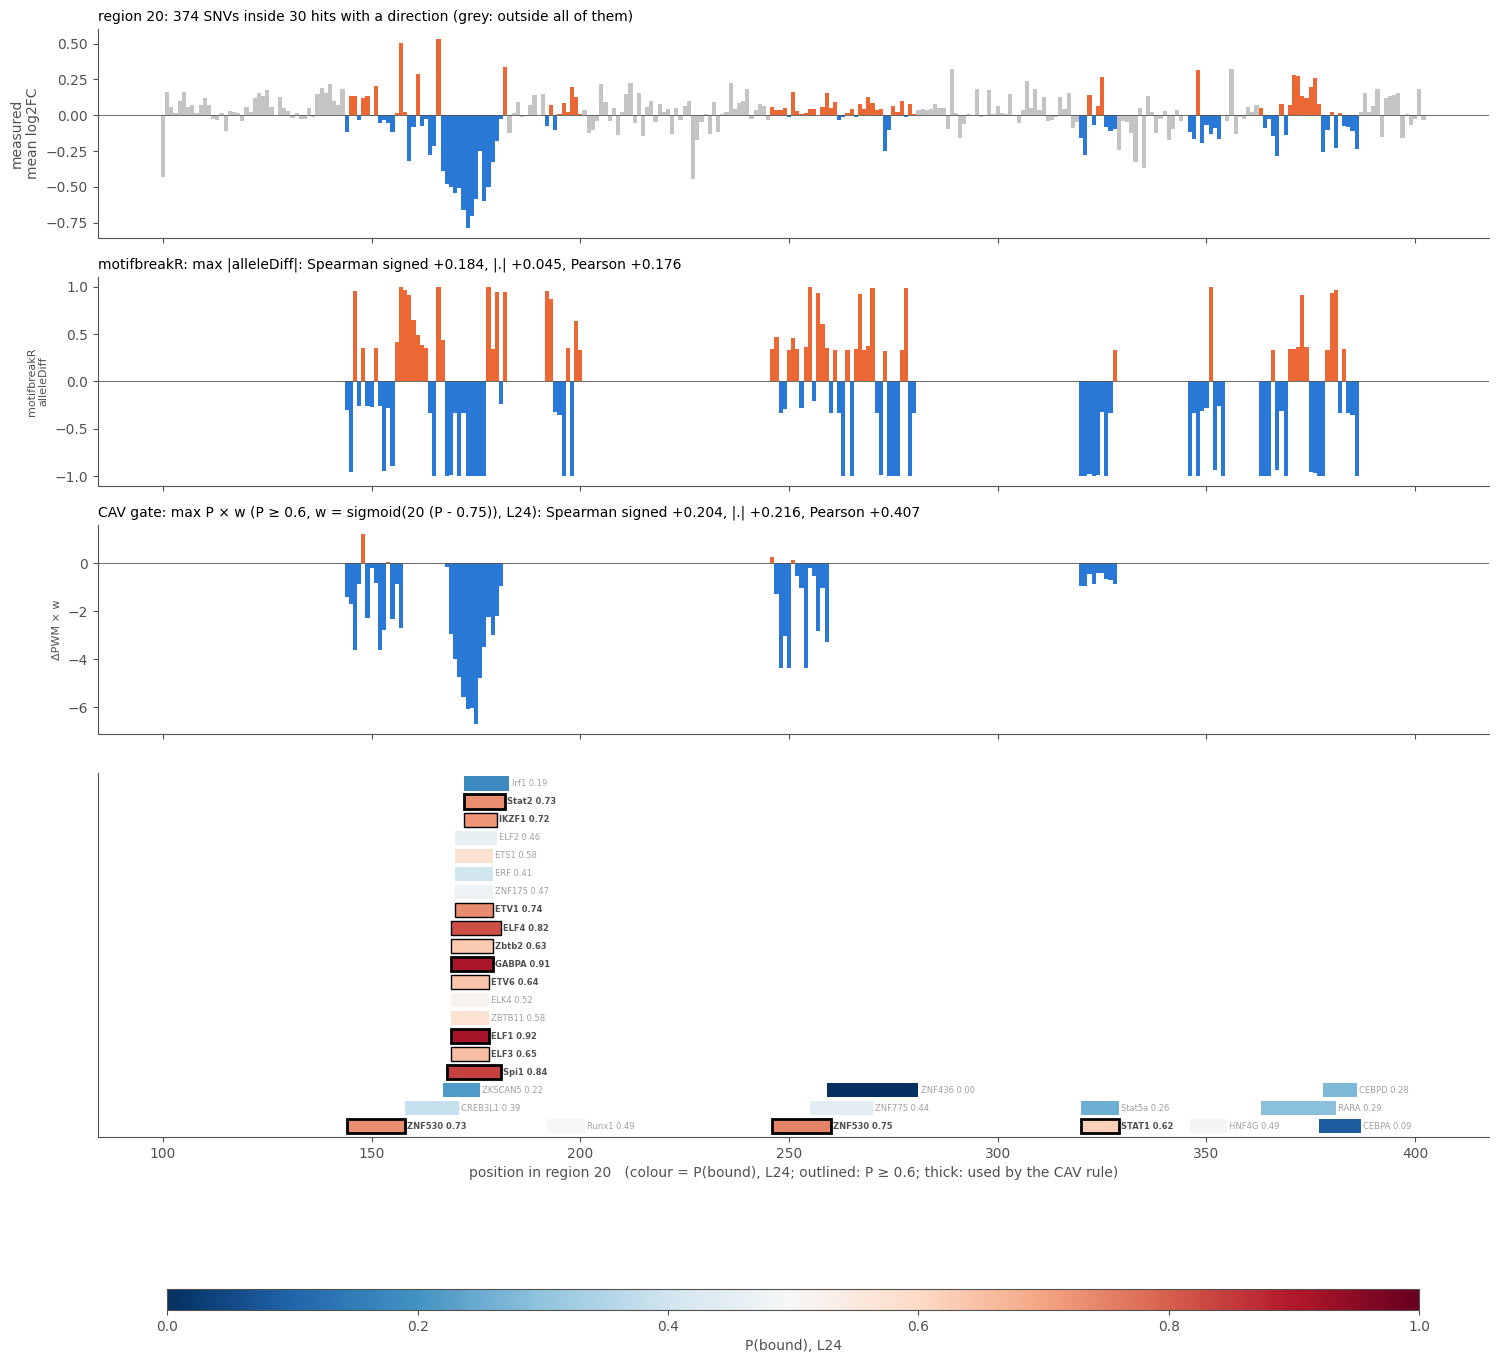

In [31]:
# ===== motifbreakR baseline (run after the main cell; uses D, predict, scores, PL, TH, MID, K, LP, OUT, REG, WORK_DIR) =====
# Re-implementation of motifbreakR's default scoring (Coetzee et al. 2015; R/scoreMotif.R, method = "default"):
#   pseudocounts  M' = (M * nsites + 0.25) / (nsites + 1)            (nsites from the MEME file, 20 if missing)
#   weights       w_i = max_j M'_ji - min_j M'_ji                     ("weighted sum")
#   score         F(s) = sum_i M'_{s_i, i} * w_i,  scaled to 0-1 by the motif's min/max possible score (pct)
#   per SNV and motif: best window (both strands) containing the SNV, separately for ref and alt;
#   reported if pctRef or pctAlt > 0.85; alleleDiff = F(alt) - F(ref); "neut" (|alleleDiff| < 0.4) not reported
# One prediction per SNV (motifbreakR itself gives a table): the reported motif with the largest |alleleDiff|
# (common use), or the reported motif with the highest pctRef (one motif per position); 0 if none is reported.
MBR_THRESH, MBR_NEUT = 0.85, 0.4
MBR_PLOT = "motifbreakR: max |alleleDiff|"          # the motifbreakR rule drawn in the figures

import re
C_ = json.load(open(f"{WORK_DIR}/config.json"))
MOFF_ = C_["motif_offset"]


def _read_meme(path):
    # name -> (frequency matrix w x 4, nsites); first matrix with each name, as in Section 1
    out, name, rows, ns = {}, None, [], 20
    for line in open(path):
        t = line.split()
        if line.startswith("MOTIF"):
            if name is not None and name not in out:
                out[name] = (np.array(rows), ns)
            name, rows, ns = (t[2] if len(t) > 2 else t[1]), [], 20
        elif line.startswith("letter-probability"):
            m = re.search(r"nsites=\s*([0-9.]+)", line)
            ns = float(m.group(1)) if m else 20
        elif name is not None and len(t) == 4 and all(re.fullmatch(r"[0-9.eE+-]+", x) for x in t):
            rows.append([float(x) for x in t])
    if name is not None and name not in out:
        out[name] = (np.array(rows), ns)
    return out


if "MBR_MATS" not in globals():
    MBR_MATS = {}
    for name, (f, ns) in _read_meme(C_["meme_path"]).items():
        f = f / f.sum(1, keepdims=True)
        p = (f * ns + 0.25) / (ns + 1)
        S = p * (p.max(1) - p.min(1))[:, None]                       # w x 4, A C G T
        S = np.vstack([S.T, np.zeros(len(S))]).T                     # 5th column: N scores 0
        MBR_MATS[name] = (S, S[::-1][:, [3, 2, 1, 0, 4]], S[:, :4].min(1).sum(), S[:, :4].max(1).sum())
    print(f"motifbreakR scoring: {len(MBR_MATS)} JASPAR matrices")

ENC = {"A": 0, "C": 1, "G": 2, "T": 3}


def region_seq(r):
    # genome-orientation sequence around the region (local coordinates), rebuilt from the MPRA hit windows of Section 1
    mw = json.load(open(f"{WORK_DIR}/{REG[r][0]}/mpra_windows.json"))
    base = {}
    for h in mw["hits"]:
        for i, b in enumerate(h["window"]):
            base.setdefault(h["start"] - MOFF_ + i, b)
    lo, hi = min(base), max(base) + 1
    seq = np.array([ENC.get(base.get(x, "N"), 4) for x in range(lo, hi)])
    return seq, lo


def motifbreakr(r, d, motifs):
    # rows: (snv index in d, motif) reported by motifbreakR; columns pctRef, pctAlt, alleleDiff
    seq, lo = region_seq(r)
    snv = d["snv"].loc[d["sn"][d["st"]]]
    pos = snv["local"].values - lo
    ref = snv["ref"].map(ENC).values
    alt = snv["alt"].map(ENC).values
    assert (seq[pos] == ref).all(), "rebuilt sequence disagrees with the SNV reference bases"
    out = []
    for m in motifs:
        if m not in MBR_MATS:
            continue
        S, Sr, smin, smax = MBR_MATS[m]
        w = len(S)
        n = len(seq) - w + 1
        idx = np.arange(n)[:, None] + np.arange(w)[None, :]
        f_fwd, f_rev = S[np.arange(w), seq[idx]].sum(1), Sr[np.arange(w), seq[idx]].sum(1)   # every window, both strands
        st = pos[:, None] - np.arange(w)[None, :]                    # windows containing the SNV: start = pos - k
        k = np.broadcast_to(np.arange(w), st.shape)
        ok = (st >= 0) & (st < n)
        stc = np.clip(st, 0, n - 1)
        ref_f = np.where(ok, f_fwd[stc], -np.inf)
        ref_r = np.where(ok, f_rev[stc], -np.inf)
        alt_f = ref_f + np.where(ok, S[k, alt[:, None]] - S[k, ref[:, None]], 0)
        alt_r = ref_r + np.where(ok, Sr[k, alt[:, None]] - Sr[k, ref[:, None]], 0)
        sr, sa = np.maximum(ref_f, ref_r).max(1), np.maximum(alt_f, alt_r).max(1)
        pr, pa = (sr - smin) / (smax - smin), (sa - smin) / (smax - smin)
        diff = sa - sr
        keep = np.isfinite(sr) & ((pr > MBR_THRESH) | (pa > MBR_THRESH)) & (np.abs(diff) >= MBR_NEUT)
        for i in np.flatnonzero(keep):
            out.append((i, m, pr[i], pa[i], diff[i]))
    return pd.DataFrame(out, columns=["i", "motif", "pctRef", "pctAlt", "alleleDiff"])


def mbr_predict(tab, n_snv):
    res = {}
    for name, key in (("max |alleleDiff|", tab["alleleDiff"].abs()), ("max pctRef", tab["pctRef"])):
        pred = np.zeros(n_snv)
        if len(tab):
            t = tab.assign(key=key.values).sort_values(["i", "key"], ascending=[True, False]).drop_duplicates("i")
            pred[t["i"].values] = t["alleleDiff"].values
        res[name] = pred
    return res


if "MBR_TAB" not in globals():
    MBR_TAB = {}
    for r, d in D.items():
        MBR_TAB[(r, "all")] = motifbreakr(r, d, list(MBR_MATS))
        MBR_TAB[(r, "dir")] = MBR_TAB[(r, "all")][MBR_TAB[(r, "all")]["motif"].isin(set(d["motif"]))]
        print(f"region {r}: motifbreakR reports {len(MBR_TAB[(r, 'all')])} SNV-motif pairs "
              f"({MBR_TAB[(r, 'all')]['i'].nunique()} of {len(d['st'])} SNVs), "
              f"{len(MBR_TAB[(r, 'dir')])} with motifs that have a direction")

SHOW_RULES = ["PWM: max relative score", "PWM: max relative score, Δocc", "CAV gate: max P × w", "CAV no gate: max P × w"]
rows, PRED_MBR = [], {}
for r, d in D.items():
    pr = predict(d, PL[r])
    P_ = {k: pr[k] for k in SHOW_RULES}
    for sset, lab in (("all", "all JASPAR"), ("dir", "motifs with a direction")):
        for k, v in mbr_predict(MBR_TAB[(r, sset)], len(d["st"])).items():
            P_[f"motifbreakR: {k}" + ("" if sset == "all" else f" ({lab})")] = v
    PRED_MBR[r] = P_
    for k, v in P_.items():
        rows.append({"rule": k, "region": r, **dict(zip(METRICS, scores(v, d["y"]))),
                     "SNVs predicted 0": int((v == 0).sum())})
MB = pd.DataFrame(rows)
MB.to_csv(f"{OUT}/motifbreakr_vs_cav_L{LP}.csv", index=False)
order = [k for k in PRED_MBR[next(iter(D))] if k.startswith("motifbreakR")] + SHOW_RULES
print(f"\n=== motifbreakR (threshold {MBR_THRESH}, non-neutral) vs CAV (P ≥ {TH}, w = sigmoid({K} (P - {MID})), L{LP}); "
      f"same SNVs; mean over regions {' / '.join(map(str, D))}\n")
print(MB.groupby("rule")[METRICS].mean().loc[order].to_string(float_format=lambda x: f"{x:+.3f}"))
print("\n--- per region")
print(MB.pivot(index="rule", columns="region", values=METRICS).loc[order].to_string(float_format=lambda x: f"{x:+.3f}"))
print("\n--- SNVs predicted 0 (no motif reported / kept)")
print(MB.pivot(index="rule", columns="region", values="SNVs predicted 0").loc[order].to_string())

# ---------- figures: log2FC / motifbreakR / CAV max P × w / motifs ----------
cm, nm = plt.get_cmap("RdBu_r"), mcolors.TwoSlopeNorm(vmin=0, vcenter=0.5, vmax=1)
col = lambda v: np.where(v < 0, C1, C2)
for r, d in D.items():
    p = PL[r]
    S_ = pd.DataFrame({"local": d["local"], "y": d["y"], "a": PRED_MBR[r][MBR_PLOT], "b": PRED_MBR[r]["CAV gate: max P × w"]})
    pos_all = d["snv"].groupby("local")["log2FC"].mean()
    pos = S_.groupby("local")[["a", "b"]].mean()
    sc = {k: scores(S_[k].values, S_["y"].values) for k in ("a", "b")}
    g = p[d["hi"]]
    iP = _first_by(d, np.where(g >= TH, g, -1.0))
    used = set(d["hid"][iP][(g >= TH)[iP]])
    hh = d["hits"].loc[d["hs"], ["motif", "start", "end"]].copy()
    hh["hit_id"], hh["P"] = d["hs"], p
    hh = hh.sort_values(["start", "end"]).reset_index(drop=True)
    hh["label"] = [f"{m} {q:.2f}" for m, q in zip(hh["motif"], hh["P"])]
    span = pos_all.index.max() - pos_all.index.min() + 1
    ends, lane = [], []
    for a_, b_, lab in zip(hh["start"], hh["end"], hh["label"]):
        b_ = b_ + 1 + 0.0045 * span * len(lab)
        kk = next((i for i, e in enumerate(ends) if e <= a_), len(ends))
        if kk == len(ends):
            ends.append(b_)
        else:
            ends[kk] = b_
        lane.append(kk)
    nrow = max(lane) + 1 if lane else 1
    fig, ax = plt.subplots(4, 1, figsize=(15, 8 + 0.3 * nrow), sharex=True,
                           gridspec_kw={"height_ratios": [2.2, 2.2, 2.2, 0.3 * nrow + 0.4]})
    ax[0].bar(pos_all.index, pos_all.values, width=1, color=np.where(~pos_all.index.isin(pos.index), GREY, col(pos_all.values)))
    ax[0].set_ylabel("measured\nmean log2FC")
    ax[0].set_title(f"region {r}: {len(S_)} SNVs inside {len(d['hs'])} hits with a direction (grey: outside all of them)",
                    loc="left", fontsize=10)
    for a, k, name, ylab in ((ax[1], "a", MBR_PLOT, "motifbreakR\nalleleDiff"),
                             (ax[2], "b", f"CAV gate: max P × w (P ≥ {TH}, w = sigmoid({K} (P - {MID})), L{LP})", "ΔPWM × w")):
        a.bar(pos.index, pos[k].values, width=1, color=col(pos[k].values))
        a.set_ylabel(ylab, fontsize=8)
        a.set_title(f"{name}: Spearman signed {sc[k][0]:+.3f}, |.| {sc[k][1]:+.3f}, Pearson {sc[k][2]:+.3f}", loc="left", fontsize=10)
    for a in ax[:3]:
        a.axhline(0, color=INK, lw=.6)
    for (_, h), kk in zip(hh.iterrows(), lane):
        kept = h["P"] >= TH
        ax[3].add_patch(plt.Rectangle((h["start"], kk), h["end"] - h["start"], 0.8, facecolor=cm(nm(h["P"])),
                                      edgecolor="black" if kept else "none", linewidth=2.0 if h["hit_id"] in used else (1.0 if kept else 0)))
        ax[3].text(h["end"] + 0.5, kk + 0.4, h["label"], va="center", fontsize=6, color=INK if kept else "#a0a0a0",
                   fontweight="bold" if kept else "normal")
    ax[3].set_ylim(-0.2, nrow); ax[3].set_yticks([])
    ax[3].set_xlabel(f"position in region {r}   (colour = P(bound), L{LP}; outlined: P ≥ {TH}; thick: used by the CAV rule)")
    fig.colorbar(plt.cm.ScalarMappable(norm=nm, cmap=cm), ax=ax[3], shrink=.9, label=f"P(bound), L{LP}",
                 orientation="horizontal", pad=0.25, aspect=60)
    plt.tight_layout()
    plt.savefig(f"{OUT}/track_r{r}_motifbreakr_vs_cav_L{LP}.png", dpi=150, bbox_inches="tight"); plt.show()


### hhh

In [ ]:
# CAV gate vs the strongest PWM-only rules on the MPRA, regions 0 / 8 / 20. One cell; data load cached, change settings and rerun.
# Principle: every rule uses at most ONE motif hit per SNV (and the choice never depends on the alt base).
TH = 0.6                      # CAV gate: hits with P(bound) < TH are dropped
MID, K = 0.75, 20             # weight w(P) = sigmoid(K * (P - MID))
LP = 24                       # layer of P(bound)
ALPHA = 0.5                   # PWM+CAV ranking: (1 - ALPHA) * rank(relative PWM score) + ALPHA * rank(P); 0 = PWM only, 1 = CAV only
ALPHAS = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]   # the curve in part 2b
N_PERM_CURVE = 200            # shuffles per alpha in part 2b
OCC_A, OCC_C = 10, 0.8        # occupancy occ(s) = sigmoid(OCC_A * (s - OCC_C)), s = PWM score / the motif's max score
N_PERM = 1000                 # shuffles for the CAV nulls (N1: across hits; N2: within motif)
PLOT = ("PWM-rank gate: max P × w", "PWM+CAV-rank gate: max P × w")   # the two rules drawn in the track figures
GRID_GATE = dict(TH=[0.5, 0.55, 0.6, 0.65, 0.7], MID=[0.6, 0.65, 0.7, 0.75, 0.8], K=[5, 10, 20, 40])
GRID_OCC = dict(A=[2, 5, 10, 20, 40], C=[0.5, 0.6, 0.7, 0.8, 0.9])
WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"

import os, json, itertools
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

pd.set_option("display.width", 250)
INK, C1, C2, GREY = "#52514e", "#2a78d6", "#eb6834", "#c4c4c4"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK})
OUT = f"{WORK_DIR}/hit_selection"
os.makedirs(OUT, exist_ok=True)
REG = {0: ("fcav_pgc_hk_r0", "fcav_pgc_hk_lr_r0"), 8: ("fcav_pgc_hk", "fcav_pgc_hk_lr"),
       20: ("fcav_pgc_hk_r20", "fcav_pgc_hk_lr_r20")}


# ---------- data (loaded once per session) ----------
def _rows(q, hits, mx):
    # SNV x hit rows sorted by SNV then hit_id (= FIMO p order), with group starts
    q = q.sort_values(["snv", "hit_id"]).reset_index(drop=True)
    sn = q["snv"].values
    m = hits.loc[q["hit_id"], "motif"].values
    return dict(sn=sn, st=np.r_[0, np.flatnonzero(sn[1:] != sn[:-1]) + 1], hid=q["hit_id"].values, dp=q["dpwm"].values,
                rel=hits.loc[q["hit_id"], "rel"].values, mx=np.array([mx[x] for x in m]))


if "D_GATE2" not in globals() or set(D_GATE2) != set(REG):     # (re)load if missing or incomplete
    try:
        from pymemesuite.common import MotifFile
    except ImportError:
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymemesuite"], check=True)
        from pymemesuite.common import MotifFile
    C = json.load(open(f"{WORK_DIR}/config.json"))
    with MotifFile(C["meme_path"]) as _mf:
        _all = list(_mf)
    _MOTIF = {}
    for m in _all:
        _MOTIF.setdefault(m.name.decode(), m)

    def _max_score(name):
        f = np.asarray(_MOTIF[name].frequencies, float)
        f = f / f.sum(1, keepdims=True)
        return float(np.log2(np.clip(f, 1e-9, 1.0) / 0.25).max(1).sum())

    _D = {}
    for r, (src, fit) in REG.items():
        S_, F_ = f"{WORK_DIR}/{src}", f"{WORK_DIR}/{fit}"
        mwj = json.load(open(f"{S_}/mpra_windows.json"))
        tfs = sorted(m for m, s in mwj["status"].items() if s == "built" and os.path.exists(f"{F_}/fits/{m}.npz"))
        fits = {m: np.load(f"{F_}/fits/{m}.npz") for m in tfs}
        layers = list(fits[tfs[0]]["layers"])
        dec = pd.concat([pd.DataFrame(fits[m]["dec_hit"], index=fits[m]["hit_id"], columns=layers) for m in tfs])
        hits = pd.read_csv(f"{S_}/hits.csv").set_index("hit_id")
        mx = {m: _max_score(m) for m in hits["motif"].unique()}
        hits["rel"] = hits["pwm"] / hits["motif"].map(mx)
        snv = pd.read_csv(f"{S_}/snvs.csv")
        pair = pd.read_csv(f"{S_}/snv_hit_dpwm.csv")
        q = pair[pair["hit_id"].isin(dec.index)]
        d = _rows(q, hits, mx)                                      # hits with a direction
        hs = np.array(sorted(q["hit_id"].unique()))
        d.update(P=1 / (1 + np.exp(-dec.loc[hs])), hs=hs, motif=hits.loc[hs, "motif"].values, hits=hits, snv=snv,
                 hi=np.searchsorted(hs, d["hid"]), rel_hit=hits.loc[hs, "rel"].values)
        d["y"] = snv.loc[d["sn"][d["st"]], "log2FC"].values
        d["local"] = snv.loc[d["sn"][d["st"]], "local"].values
        d["all"] = _rows(pair[pair["snv"].isin(d["sn"][d["st"]])], hits, mx)   # every JASPAR hit, same SNVs
        assert (d["all"]["sn"][d["all"]["st"]] == d["sn"][d["st"]]).all()
        _D[r] = d
        print(f"region {r:2d}: {len(tfs)} TFs, {len(hs)} hits with a direction, {len(d['st'])} SNVs inside them; "
              f"{len(np.unique(d['all']['hid']))} JASPAR hits of any motif cover these SNVs")
    D_GATE2 = _D                  # only once every region has loaded
D = D_GATE2
assert set(D) == set(REG), f"regions loaded: {sorted(D)}"


# ---------- rules (one hit per SNV, chosen from per-hit quantities only) ----------
def _first_by(e, key):
    # per SNV, the row with the largest key (ties: smallest hit_id = smallest FIMO p)
    return np.lexsort((e["hid"], -key, e["sn"]))[e["st"]]


def _sig(x):
    return 1 / (1 + np.exp(-x))


def pwm_rules(d, a=OCC_A, c=OCC_C):
    out = {}
    for tag, e in (("PWM", d), ("PWM all hits", d["all"])):
        iR = _first_by(e, e["rel"])
        docc = _sig(a * (e["rel"] + e["dp"] / e["mx"] - c)) - _sig(a * (e["rel"] - c))
        out[f"{tag}: best p"] = e["dp"][e["st"]]
        out[f"{tag}: max relative score"] = e["dp"][iR]
        out[f"{tag}: max relative score, Δocc"] = docc[iR]
    return out


def gate_rules(d, s_hit, prefix, th=TH, mid=MID, k=K):
    # drop hits with s < th; among the rest the hit with the highest s; ΔPWM, × s or × w(s); 0 if none is left
    g = s_hit[d["hi"]]
    kept = g >= th
    iP = _first_by(d, np.where(kept, g, -1.0))
    ok = kept[iP]
    return {f"{prefix}: max P": np.where(ok, d["dp"][iP], 0.0),
            f"{prefix}: max P × P": np.where(ok, d["dp"][iP] * g[iP], 0.0),
            f"{prefix}: max P × w": np.where(ok, d["dp"][iP] * _sig(k * (g[iP] - mid)), 0.0)}


def rank_as_P(p_hit, key_hit):
    # the CAV's own P values handed to the hits in the order of key_hit (largest key gets the largest P)
    out = np.empty_like(p_hit)
    out[np.argsort(key_hit, kind="stable")] = np.sort(p_hit)
    return out


def combo_key(d, p_hit, alpha=ALPHA):
    # per-hit ranking key mixing the relative PWM score and the CAV's P, both as within-region ranks in (0, 1]
    n = len(p_hit)
    return (1 - alpha) * stats.rankdata(d["rel_hit"]) / n + alpha * stats.rankdata(p_hit) / n


def combo_rules(d, p_hit, alpha=ALPHA, p_vals=None, **kw):
    # the gate with the hits ranked by PWM + CAV (p_hit only sets the ranking); the values handed out in that order are
    # the region's real P values (p_vals), so a shuffled P changes the ranking only, never how many hits are kept
    vals = p_hit if p_vals is None else p_vals
    return gate_rules(d, rank_as_P(vals, combo_key(d, p_hit, alpha)), "PWM+CAV-rank gate", **kw)


def predict(d, p_hit, **kw):
    out = pwm_rules(d)
    out.update(gate_rules(d, p_hit, "CAV gate", **kw))
    out.update(gate_rules(d, p_hit, "CAV no gate", **{**kw, "th": 0.0}))     # every hit kept; only w(P) shrinks
    out.update(combo_rules(d, p_hit, **kw))
    out.update(gate_rules(d, rank_as_P(p_hit, d["rel_hit"]), "PWM-rank gate", **kw))
    out.update(gate_rules(d, rank_as_P(p_hit, -d["hs"].astype(float)), "p-rank gate", **kw))
    return out


RULES = list(predict(D[8], D[8]["P"][LP].values))
CAV = [k for k in RULES if k.startswith(("CAV", "PWM+CAV"))]     # rules that use the CAV: nulls shuffle P
METRICS = ["Spearman signed", "Spearman |.|", "Pearson signed"]


def scores(pred, y):
    if np.std(pred) == 0:
        return np.array([np.nan] * 3)
    return np.array([stats.spearmanr(pred, y)[0], stats.spearmanr(np.abs(pred), np.abs(y))[0], stats.pearsonr(pred, y)[0]])


def mean_scores(fn):
    # fn(d, region) -> {rule: prediction}; returns {rule: 3-region mean of the metrics}
    acc = {}
    for r, d in D.items():
        for k, v in fn(d, r).items():
            acc.setdefault(k, []).append(scores(v, d["y"]))
    return {k: np.mean(v, 0) for k, v in acc.items()}


GROUPS = {}
for r, d in D.items():
    for i, m in enumerate(d["motif"]):
        GROUPS.setdefault(m, []).append((r, i))


def perm_global(rng):
    return {r: rng.permutation(d["P"][LP].values) for r, d in D.items()}


def perm_motif(rng):
    out = {r: d["P"][LP].values.copy() for r, d in D.items()}
    for mem in GROUPS.values():
        if len(mem) > 1:
            vals = np.array([D[r]["P"][LP].values[i] for r, i in mem])[rng.permutation(len(mem))]
            for (r, i), v in zip(mem, vals):
                out[r][i] = v
    return out


# ---------- 1. fixed settings: every rule, CAV nulls ----------
rng = np.random.default_rng(0)
PL = {r: d["P"][LP].values for r, d in D.items()}
obs = mean_scores(lambda d, r: predict(d, PL[r]))
per_region = {r: {k: scores(v, d["y"]) for k, v in predict(d, PL[r]).items()} for r, d in D.items()}
cav_only = lambda pm: mean_scores(lambda d, r: {**gate_rules(d, pm[r], "CAV gate"), **gate_rules(d, pm[r], "CAV no gate", th=0.0),
                                                **combo_rules(d, pm[r], p_vals=PL[r])})
n1 = np.array([[v for v in cav_only(perm_global(rng)).values()] for _ in range(N_PERM)])     # (perm, rule, metric)
n2 = np.array([[v for v in cav_only(perm_motif(rng)).values()] for _ in range(N_PERM)])
rows = []
for k in RULES:
    row = {"rule": k}
    for j, mt in enumerate(METRICS):
        row[mt] = obs[k][j]
        if k in CAV:
            ki = CAV.index(k)
            row[f"{mt}: null N1"], row[f"{mt}: p N1"] = np.nanmean(n1[:, ki, j]), np.mean(n1[:, ki, j] >= row[mt])
            row[f"{mt}: null N2"], row[f"{mt}: p N2"] = np.nanmean(n2[:, ki, j]), np.mean(n2[:, ki, j] >= row[mt])
    rows.append(row)
T = pd.DataFrame(rows).set_index("rule")
tag = f"th{TH}_w{MID}-{K}_occ{OCC_A}-{OCC_C}_L{LP}"
T.to_csv(f"{OUT}/onehit_{tag}.csv")
print(f"\n=== fixed settings: P ≥ {TH}, w = sigmoid({K} (P - {MID})), occ = sigmoid({OCC_A} (s - {OCC_C})), layer {LP}; "
      f"mean over regions {' / '.join(map(str, D))}; nulls {N_PERM} shuffles\n")
for mt in METRICS:
    cols = [mt] + [c for c in T.columns if c.startswith(mt + ":")]
    print(f"--- {mt}")
    print(T[cols].rename(columns=lambda c: c.replace(mt + ": ", "")).to_string(float_format=lambda x: f"{x:+.3f}", na_rep=""))
    print()
print("--- per region")
print(pd.DataFrame({(k, f"r{r}"): per_region[r][k] for k in RULES for r in D}, index=METRICS).T
      .unstack(1).to_string(float_format=lambda x: f"{x:+.3f}"))
for r, d in D.items():
    nk = np.add.reduceat((PL[r] >= TH)[d["hi"]].astype(int), d["st"])
    print(f"region {r}: {int((PL[r] >= TH).sum())} of {len(PL[r])} hits kept by the CAV gate; {int((nk == 0).sum())} of {len(nk)} SNVs predicted 0")

# ---------- 2b. does the CAV add to the PWM? mixing weight alpha, gate rule "max P × w" at the fixed settings ----------
# alpha = 0 is the PWM-rank gate, alpha = 1 the CAV gate. Null for every alpha: P shuffled (N1 across hits, N2 within
# motif) while the PWM scores stay: tests whether the CAV's ranking adds to the PWM's.
KEY = "PWM+CAV-rank gate: max P × w"
rows = []
for al in ALPHAS:
    f = lambda pm: mean_scores(lambda d, r: {KEY: combo_rules(d, pm[r], al, p_vals=PL[r])[KEY]})[KEY]
    o = f(PL)
    a1 = np.array([f(perm_global(rng)) for _ in range(N_PERM_CURVE)])
    a2 = np.array([f(perm_motif(rng)) for _ in range(N_PERM_CURVE)])
    for j, mt in enumerate(METRICS):
        rows.append({"alpha": al, "metric": mt, "obs": o[j], "null N1": np.nanmean(a1[:, j]), "p N1": np.mean(a1[:, j] >= o[j]),
                     "null N2": np.nanmean(a2[:, j]), "p N2": np.mean(a2[:, j] >= o[j])})
AC = pd.DataFrame(rows)
AC.to_csv(f"{OUT}/combo_alpha_{tag}.csv", index=False)
print(f"\n=== PWM + CAV ranking, rule max P × w, fixed settings; alpha 0 = PWM-rank gate, 1 = CAV gate; nulls {N_PERM_CURVE} shuffles\n")
for mt in METRICS:
    t = AC[AC.metric == mt].set_index("alpha").drop(columns="metric")
    base = t.loc[0, "obs"]
    print(f"--- {mt} (PWM alone, alpha 0: {base:+.3f})")
    print(t.assign(**{"vs PWM alone": t["obs"] - base}).T.to_string(float_format=lambda x: f"{x:+.3f}"))
    print()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, mt in zip(ax, METRICS):
    t = AC[AC.metric == mt]
    a.plot(t.alpha, t.obs, c="#2a78d6", marker="o", ms=4, label="PWM + CAV")
    a.plot(t.alpha, t["null N1"], c="#2a78d6", lw=.8, ls=":", label="P shuffled across hits")
    a.plot(t.alpha, t["null N2"], c="#eb6834", lw=.8, ls=":", label="P shuffled within motif")
    a.axhline(t.obs.iloc[0], c=INK, lw=.6, ls="--", label="PWM alone (alpha 0)")
    a.set_xlabel("alpha (weight of the CAV in the ranking)"); a.set_title(mt, loc="left", fontsize=10)
    a.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/combo_alpha_{tag}.png", dpi=150, bbox_inches="tight"); plt.show()

# ---------- 2. tuned on these three regions: the best each family can reach ----------
best = []
for a, c in itertools.product(GRID_OCC["A"], GRID_OCC["C"]):
    s = mean_scores(lambda d, r: {k: v for k, v in pwm_rules(d, a, c).items() if "Δocc" in k})
    for k, v in s.items():
        best.append({"family": k, "setting": f"A={a}, C={c}", **dict(zip(METRICS, v))})
for th, mid, k_ in itertools.product(GRID_GATE["TH"], GRID_GATE["MID"], GRID_GATE["K"]):
    s = mean_scores(lambda d, r: {**gate_rules(d, PL[r], "CAV gate", th, mid, k_),
                                  **gate_rules(d, rank_as_P(PL[r], d["rel_hit"]), "PWM-rank gate", th, mid, k_),
                                  **combo_rules(d, PL[r], ALPHA, th=th, mid=mid, k=k_),
                                  **gate_rules(d, rank_as_P(PL[r], -d["hs"].astype(float)), "p-rank gate", th, mid, k_)})
    for k, v in s.items():
        best.append({"family": k, "setting": f"TH={th}" + (f", MID={mid}, K={k_}" if k.endswith("× w") else ""), **dict(zip(METRICS, v))})
B = pd.DataFrame(best).drop_duplicates(["family", "setting"])
B.to_csv(f"{OUT}/onehit_grid_L{LP}.csv", index=False)
print("\n=== best setting per rule, tuned on these three regions (generous to every rule; the CAV row at the fixed setting "
      "is in the table above)")
for mt in METRICS:
    t = B.loc[B.groupby("family")[mt].idxmax()].set_index("family")[["setting", mt]].sort_values(mt, ascending=False)
    fixed = pd.Series({k: obs[k][METRICS.index(mt)] for k in t.index}, name="at fixed setting")
    print(f"--- {mt}")
    print(t.join(fixed).to_string(float_format=lambda x: f"{x:+.3f}"))
    print()

# ---------- 3. track figures ----------
cm, nm = plt.get_cmap("RdBu_r"), mcolors.TwoSlopeNorm(vmin=0, vcenter=0.5, vmax=1)
col = lambda v: np.where(v < 0, C1, C2)
for r, d in D.items():
    p = PL[r]
    pr = predict(d, p)
    S = pd.DataFrame({"local": d["local"], "y": d["y"], "a": pr[PLOT[0]], "b": pr[PLOT[1]]})
    pos_all = d["snv"].groupby("local")["log2FC"].mean()
    pos = S.groupby("local")[["a", "b"]].mean()
    sc = {k: scores(S[k].values, S["y"].values) for k in ("a", "b")}
    g = p[d["hi"]]
    iP = _first_by(d, np.where(g >= TH, g, -1.0))
    used = set(d["hid"][iP][(g >= TH)[iP]])

    hh = d["hits"].loc[d["hs"], ["motif", "start", "end"]].copy()
    hh["hit_id"], hh["P"] = d["hs"], p
    hh = hh.sort_values(["start", "end"]).reset_index(drop=True)
    hh["label"] = [f"{m} {q:.2f}" for m, q in zip(hh["motif"], hh["P"])]
    span = pos_all.index.max() - pos_all.index.min() + 1
    ends, lane = [], []
    for a_, b_, lab in zip(hh["start"], hh["end"], hh["label"]):
        b_ = b_ + 1 + 0.0045 * span * len(lab)
        kk = next((i for i, e in enumerate(ends) if e <= a_), len(ends))
        if kk == len(ends):
            ends.append(b_)
        else:
            ends[kk] = b_
        lane.append(kk)
    nrow = max(lane) + 1 if lane else 1

    fig, ax = plt.subplots(4, 1, figsize=(15, 8 + 0.3 * nrow), sharex=True,
                           gridspec_kw={"height_ratios": [2.2, 2.2, 2.2, 0.3 * nrow + 0.4]})
    ax[0].bar(pos_all.index, pos_all.values, width=1, color=np.where(~pos_all.index.isin(pos.index), GREY, col(pos_all.values)))
    ax[0].set_ylabel("measured\nmean log2FC")
    ax[0].set_title(f"region {r}: {len(S)} SNVs inside {len(d['hs'])} hits with a direction (grey: outside all of them)",
                    loc="left", fontsize=10)
    for a, k, name in ((ax[1], "a", PLOT[0]), (ax[2], "b", PLOT[1])):
        a.bar(pos.index, pos[k].values, width=1, color=col(pos[k].values))
        a.set_ylabel(name.split(": ")[1], fontsize=8)
        extra = f" (P ≥ {TH}, L{LP}" + (f", w = sigmoid({K} (P - {MID}))" if name.endswith("w") else "") + ")" if "gate" in name else ""
        a.set_title(f"{name}{extra}: Spearman signed {sc[k][0]:+.3f}, |.| {sc[k][1]:+.3f}, Pearson {sc[k][2]:+.3f}",
                    loc="left", fontsize=10)
    for a in ax[:3]:
        a.axhline(0, color=INK, lw=.6)
    for (_, h), kk in zip(hh.iterrows(), lane):
        kept = h["P"] >= TH
        lw = 2.0 if h["hit_id"] in used else (1.0 if kept else 0)
        ax[3].add_patch(plt.Rectangle((h["start"], kk), h["end"] - h["start"], 0.8, facecolor=cm(nm(h["P"])),
                                      edgecolor="black" if kept else "none", linewidth=lw))
        ax[3].text(h["end"] + 0.5, kk + 0.4, h["label"], va="center", fontsize=6, color=INK if kept else "#a0a0a0",
                   fontweight="bold" if kept else "normal")
    ax[3].set_ylim(-0.2, nrow); ax[3].set_yticks([])
    ax[3].set_xlabel(f"position in region {r}   (colour = P(bound), L{LP}; outlined: P ≥ {TH}; "
                     f"thick outline: the hit the CAV gate uses for at least one SNV)")
    fig.colorbar(plt.cm.ScalarMappable(norm=nm, cmap=cm), ax=ax[3], shrink=.9, label=f"P(bound), L{LP}",
                 orientation="horizontal", pad=0.25, aspect=60)
    plt.tight_layout()
    plt.savefig(f"{OUT}/track_r{r}_onehit_{tag}.png", dpi=150, bbox_inches="tight"); plt.show()


In [ ]:
# ===== motifbreakR baseline (run after the main cell; uses D, predict, scores, PL, TH, MID, K, LP, OUT, REG, WORK_DIR) =====
# Re-implementation of motifbreakR's default scoring (Coetzee et al. 2015; R/scoreMotif.R, method = "default"):
#   pseudocounts  M' = (M * nsites + 0.25) / (nsites + 1)            (nsites from the MEME file, 20 if missing)
#   weights       w_i = max_j M'_ji - min_j M'_ji                     ("weighted sum")
#   score         F(s) = sum_i M'_{s_i, i} * w_i,  scaled to 0-1 by the motif's min/max possible score (pct)
#   per SNV and motif: best window (both strands) containing the SNV, separately for ref and alt;
#   reported if pctRef or pctAlt > 0.85; alleleDiff = F(alt) - F(ref); "neut" (|alleleDiff| < 0.4) not reported
# One prediction per SNV (motifbreakR itself gives a table): the reported motif with the largest |alleleDiff|
# (common use), or the reported motif with the highest pctRef (one motif per position); 0 if none is reported.
MBR_THRESH, MBR_NEUT = 0.85, 0.4
MBR_PLOT = "motifbreakR: max |alleleDiff|"          # the motifbreakR rule drawn in the figures
CAV_PLOT = "CAV no gate: max P × w"                 # or "CAV gate: max P × w"

import re
C_ = json.load(open(f"{WORK_DIR}/config.json"))
MOFF_ = C_["motif_offset"]


def _read_meme(path):
    # name -> (frequency matrix w x 4, nsites); first matrix with each name, as in Section 1
    out, name, rows, ns = {}, None, [], 20
    for line in open(path):
        t = line.split()
        if line.startswith("MOTIF"):
            if name is not None and name not in out:
                out[name] = (np.array(rows), ns)
            name, rows, ns = (t[2] if len(t) > 2 else t[1]), [], 20
        elif line.startswith("letter-probability"):
            m = re.search(r"nsites=\s*([0-9.]+)", line)
            ns = float(m.group(1)) if m else 20
        elif name is not None and len(t) == 4 and all(re.fullmatch(r"[0-9.eE+-]+", x) for x in t):
            rows.append([float(x) for x in t])
    if name is not None and name not in out:
        out[name] = (np.array(rows), ns)
    return out


if "MBR_MATS" not in globals():
    MBR_MATS = {}
    for name, (f, ns) in _read_meme(C_["meme_path"]).items():
        f = f / f.sum(1, keepdims=True)
        p = (f * ns + 0.25) / (ns + 1)
        S = p * (p.max(1) - p.min(1))[:, None]                       # w x 4, A C G T
        S = np.vstack([S.T, np.zeros(len(S))]).T                     # 5th column: N scores 0
        MBR_MATS[name] = (S, S[::-1][:, [3, 2, 1, 0, 4]], S[:, :4].min(1).sum(), S[:, :4].max(1).sum())
    print(f"motifbreakR scoring: {len(MBR_MATS)} JASPAR matrices")

ENC = {"A": 0, "C": 1, "G": 2, "T": 3}


def region_seq(r):
    # genome-orientation sequence around the region (local coordinates), rebuilt from the MPRA hit windows of Section 1
    mw = json.load(open(f"{WORK_DIR}/{REG[r][0]}/mpra_windows.json"))
    base = {}
    for h in mw["hits"]:
        for i, b in enumerate(h["window"]):
            base.setdefault(h["start"] - MOFF_ + i, b)
    lo, hi = min(base), max(base) + 1
    seq = np.array([ENC.get(base.get(x, "N"), 4) for x in range(lo, hi)])
    return seq, lo


def motifbreakr(r, d, motifs):
    # rows: (snv index in d, motif) reported by motifbreakR; columns pctRef, pctAlt, alleleDiff
    seq, lo = region_seq(r)
    snv = d["snv"].loc[d["sn"][d["st"]]]
    pos = snv["local"].values - lo
    ref = snv["ref"].map(ENC).values
    alt = snv["alt"].map(ENC).values
    assert (seq[pos] == ref).all(), "rebuilt sequence disagrees with the SNV reference bases"
    out = []
    for m in motifs:
        if m not in MBR_MATS:
            continue
        S, Sr, smin, smax = MBR_MATS[m]
        w = len(S)
        n = len(seq) - w + 1
        idx = np.arange(n)[:, None] + np.arange(w)[None, :]
        f_fwd, f_rev = S[np.arange(w), seq[idx]].sum(1), Sr[np.arange(w), seq[idx]].sum(1)   # every window, both strands
        st = pos[:, None] - np.arange(w)[None, :]                    # windows containing the SNV: start = pos - k
        k = np.broadcast_to(np.arange(w), st.shape)
        ok = (st >= 0) & (st < n)
        stc = np.clip(st, 0, n - 1)
        ref_f = np.where(ok, f_fwd[stc], -np.inf)
        ref_r = np.where(ok, f_rev[stc], -np.inf)
        alt_f = ref_f + np.where(ok, S[k, alt[:, None]] - S[k, ref[:, None]], 0)
        alt_r = ref_r + np.where(ok, Sr[k, alt[:, None]] - Sr[k, ref[:, None]], 0)
        sr, sa = np.maximum(ref_f, ref_r).max(1), np.maximum(alt_f, alt_r).max(1)
        pr, pa = (sr - smin) / (smax - smin), (sa - smin) / (smax - smin)
        diff = sa - sr
        keep = np.isfinite(sr) & ((pr > MBR_THRESH) | (pa > MBR_THRESH)) & (np.abs(diff) >= MBR_NEUT)
        for i in np.flatnonzero(keep):
            out.append((i, m, pr[i], pa[i], diff[i]))
    return pd.DataFrame(out, columns=["i", "motif", "pctRef", "pctAlt", "alleleDiff"])


def mbr_predict(tab, n_snv):
    res = {}
    for name, key in (("max |alleleDiff|", tab["alleleDiff"].abs()), ("max pctRef", tab["pctRef"])):
        pred = np.zeros(n_snv)
        if len(tab):
            t = tab.assign(key=key.values).sort_values(["i", "key"], ascending=[True, False]).drop_duplicates("i")
            pred[t["i"].values] = t["alleleDiff"].values
        res[name] = pred
    return res


if "MBR_TAB" not in globals():
    MBR_TAB = {}
    for r, d in D.items():
        MBR_TAB[(r, "all")] = motifbreakr(r, d, list(MBR_MATS))
        MBR_TAB[(r, "dir")] = MBR_TAB[(r, "all")][MBR_TAB[(r, "all")]["motif"].isin(set(d["motif"]))]
        print(f"region {r}: motifbreakR reports {len(MBR_TAB[(r, 'all')])} SNV-motif pairs "
              f"({MBR_TAB[(r, 'all')]['i'].nunique()} of {len(d['st'])} SNVs), "
              f"{len(MBR_TAB[(r, 'dir')])} with motifs that have a direction")

SHOW_RULES = ["PWM: max relative score", "PWM: max relative score, Δocc", "CAV gate: max P × w", "CAV no gate: max P × w"]
rows, PRED_MBR = [], {}
for r, d in D.items():
    pr = predict(d, PL[r])
    pr.update(gate_rules(d, PL[r], "CAV no gate", th=0.0))       # in case the main cell predates the no-gate rule
    P_ = {k: pr[k] for k in SHOW_RULES}
    for sset, lab in (("all", "all JASPAR"), ("dir", "motifs with a direction")):
        for k, v in mbr_predict(MBR_TAB[(r, sset)], len(d["st"])).items():
            P_[f"motifbreakR: {k}" + ("" if sset == "all" else f" ({lab})")] = v
    PRED_MBR[r] = P_
    for k, v in P_.items():
        rows.append({"rule": k, "region": r, **dict(zip(METRICS, scores(v, d["y"]))),
                     "SNVs predicted 0": int((v == 0).sum())})
MB = pd.DataFrame(rows)
MB.to_csv(f"{OUT}/motifbreakr_vs_cav_L{LP}.csv", index=False)
order = [k for k in PRED_MBR[next(iter(D))] if k.startswith("motifbreakR")] + SHOW_RULES
print(f"\n=== motifbreakR (threshold {MBR_THRESH}, non-neutral) vs CAV (P ≥ {TH}, w = sigmoid({K} (P - {MID})), L{LP}); "
      f"same SNVs; mean over regions {' / '.join(map(str, D))}\n")
print(MB.groupby("rule")[METRICS].mean().loc[order].to_string(float_format=lambda x: f"{x:+.3f}"))
print("\n--- per region")
print(MB.pivot(index="rule", columns="region", values=METRICS).loc[order].to_string(float_format=lambda x: f"{x:+.3f}"))
print("\n--- SNVs predicted 0 (no motif reported / kept)")
print(MB.pivot(index="rule", columns="region", values="SNVs predicted 0").loc[order].to_string())

# ---------- figures: log2FC / motifbreakR / CAV max P × w / motifs ----------
cm, nm = plt.get_cmap("RdBu_r"), mcolors.TwoSlopeNorm(vmin=0, vcenter=0.5, vmax=1)
col = lambda v: np.where(v < 0, C1, C2)
for r, d in D.items():
    p = PL[r]
    S_ = pd.DataFrame({"local": d["local"], "y": d["y"], "a": PRED_MBR[r][MBR_PLOT], "b": PRED_MBR[r][CAV_PLOT]})
    pos_all = d["snv"].groupby("local")["log2FC"].mean()
    pos = S_.groupby("local")[["a", "b"]].mean()
    sc = {k: scores(S_[k].values, S_["y"].values) for k in ("a", "b")}
    th_plot = 0.0 if "no gate" in CAV_PLOT else TH
    g = p[d["hi"]]
    iP = _first_by(d, np.where(g >= th_plot, g, -1.0))
    used = set(d["hid"][iP][(g >= th_plot)[iP]])
    hh = d["hits"].loc[d["hs"], ["motif", "start", "end"]].copy()
    hh["hit_id"], hh["P"] = d["hs"], p
    hh = hh.sort_values(["start", "end"]).reset_index(drop=True)
    hh["label"] = [f"{m} {q:.2f}" for m, q in zip(hh["motif"], hh["P"])]
    span = pos_all.index.max() - pos_all.index.min() + 1
    ends, lane = [], []
    for a_, b_, lab in zip(hh["start"], hh["end"], hh["label"]):
        b_ = b_ + 1 + 0.0045 * span * len(lab)
        kk = next((i for i, e in enumerate(ends) if e <= a_), len(ends))
        if kk == len(ends):
            ends.append(b_)
        else:
            ends[kk] = b_
        lane.append(kk)
    nrow = max(lane) + 1 if lane else 1
    fig, ax = plt.subplots(4, 1, figsize=(15, 8 + 0.3 * nrow), sharex=True,
                           gridspec_kw={"height_ratios": [2.2, 2.2, 2.2, 0.3 * nrow + 0.4]})
    ax[0].bar(pos_all.index, pos_all.values, width=1, color=np.where(~pos_all.index.isin(pos.index), GREY, col(pos_all.values)))
    ax[0].set_ylabel("measured\nmean log2FC")
    ax[0].set_title(f"region {r}: {len(S_)} SNVs inside {len(d['hs'])} hits with a direction (grey: outside all of them)",
                    loc="left", fontsize=10)
    for a, k, name, ylab in ((ax[1], "a", MBR_PLOT, "motifbreakR\nalleleDiff"),
                             (ax[2], "b", f"{CAV_PLOT} ({'' if th_plot == 0 else f'P ≥ {TH}, '}w = sigmoid({K} (P - {MID})), L{LP})", "ΔPWM × w")):
        a.bar(pos.index, pos[k].values, width=1, color=col(pos[k].values))
        a.set_ylabel(ylab, fontsize=8)
        a.set_title(f"{name}: Spearman signed {sc[k][0]:+.3f}, |.| {sc[k][1]:+.3f}, Pearson {sc[k][2]:+.3f}", loc="left", fontsize=10)
    for a in ax[:3]:
        a.axhline(0, color=INK, lw=.6)
    for (_, h), kk in zip(hh.iterrows(), lane):
        kept = h["P"] >= th_plot
        ax[3].add_patch(plt.Rectangle((h["start"], kk), h["end"] - h["start"], 0.8, facecolor=cm(nm(h["P"])),
                                      edgecolor="black" if kept else "none", linewidth=2.0 if h["hit_id"] in used else (1.0 if kept else 0)))
        ax[3].text(h["end"] + 0.5, kk + 0.4, h["label"], va="center", fontsize=6, color=INK if kept else "#a0a0a0",
                   fontweight="bold" if kept else "normal")
    ax[3].set_ylim(-0.2, nrow); ax[3].set_yticks([])
    ax[3].set_xlabel(f"position in region {r}   (colour = P(bound), L{LP}; "
                     f"{'' if th_plot == 0 else f'outlined: P ≥ {TH}; '}thick outline: the hit the CAV rule uses for at least one SNV)")
    fig.colorbar(plt.cm.ScalarMappable(norm=nm, cmap=cm), ax=ax[3], shrink=.9, label=f"P(bound), L{LP}",
                 orientation="horizontal", pad=0.25, aspect=60)
    plt.tight_layout()
    plt.savefig(f"{OUT}/track_r{r}_motifbreakr_vs_{'nogate' if th_plot == 0 else 'gate'}_L{LP}.png", dpi=150, bbox_inches="tight"); plt.show()


In [33]:
# ===== Does the CAV improve motifbreakR? (run after the two cells above) =====
# Candidates: motifbreakR-reported (SNV, motif) pairs whose motif has a CAV direction and a FIMO hit covering the SNV
# (so the motif has a P(bound) there; max P if several hits). Every rule uses one motif per SNV, 0 if no candidate.
#   motifbreakR                  : motif with the largest |alleleDiff|, prediction alleleDiff
#   motifbreakR × w(P)           : same motif, alleleDiff × w(P)                     -> does the CAV re-weight usefully?
#   CAV-chosen motifbreakR       : motif with the highest P, alleleDiff               -> does the CAV choose better?
#   CAV-chosen motifbreakR × w(P): motif with the highest P, alleleDiff × w(P)
# Nulls for the CAV rules: P shuffled across hits (N1) / within motif (N2), as in the main cell.
MC_RULES = ["motifbreakR", "motifbreakR × w(P)", "CAV-chosen motifbreakR", "CAV-chosen motifbreakR × w(P)"]
wfun = lambda x: 1 / (1 + np.exp(-K * (x - MID)))

MC = {}
for r, d in D.items():
    n_snv = len(d["st"])
    snv_of_row = np.repeat(np.arange(n_snv), np.diff(np.r_[d["st"], len(d["sn"])]))
    rows_ = pd.DataFrame({"i": snv_of_row, "motif": d["hits"].loc[d["hid"], "motif"].values, "h": d["hi"]})
    t = MBR_TAB[(r, "dir")].reset_index(drop=True)
    t["j"] = np.arange(len(t))
    link = t[["j", "i", "motif"]].merge(rows_, on=["i", "motif"])            # (motifbreakR pair, covering hit)
    keep = np.sort(link["j"].unique())
    MC[r] = dict(t=t.loc[keep].reset_index(drop=True), n=n_snv,
                 lj=np.searchsorted(keep, link["j"].values), lh=link["h"].values)
    print(f"region {r}: {len(t)} motifbreakR pairs with directed motifs, {len(keep)} have a FIMO hit with P "
          f"({MC[r]['t']['i'].nunique()} of {n_snv} SNVs)")


def mc_predict(r, p_hit):
    m = MC[r]
    t = m["t"]
    P = np.full(len(t), -np.inf)
    np.maximum.at(P, m["lj"], p_hit[m["lh"]])
    diff = t["alleleDiff"].values

    def pick(key, val):
        pred = np.zeros(m["n"])
        o = np.lexsort((-key, t["i"].values))
        first = o[np.r_[True, t["i"].values[o][1:] != t["i"].values[o][:-1]]]
        pred[t["i"].values[first]] = val[first]
        return pred

    return {"motifbreakR": pick(np.abs(diff), diff),
            "motifbreakR × w(P)": pick(np.abs(diff), diff * wfun(P)),
            "CAV-chosen motifbreakR": pick(P + 1e-9 * np.abs(diff), diff),
            "CAV-chosen motifbreakR × w(P)": pick(P + 1e-9 * np.abs(diff), diff * wfun(P))}


def mc_eval(pmap):
    acc = {k: [] for k in MC_RULES}
    for r, d in D.items():
        for k, v in mc_predict(r, pmap[r]).items():
            acc[k].append(scores(v, d["y"]))
    return {k: np.array(v) for k, v in acc.items()}


rng = np.random.default_rng(5)
obs_mc = mc_eval(PL)
c1 = np.array([[v.mean(0) for v in mc_eval(perm_global(rng)).values()] for _ in range(N_PERM)])
c2 = np.array([[v.mean(0) for v in mc_eval(perm_motif(rng)).values()] for _ in range(N_PERM)])
rows = []
for ki, k in enumerate(MC_RULES):
    row = {"rule": k}
    for j, mt in enumerate(METRICS):
        row[mt] = obs_mc[k].mean(0)[j]
        if k != "motifbreakR":
            row[f"{mt}: vs motifbreakR"] = row[mt] - obs_mc["motifbreakR"].mean(0)[j]
            row[f"{mt}: p N1"] = np.mean(c1[:, ki, j] >= row[mt])
            row[f"{mt}: p N2"] = np.mean(c2[:, ki, j] >= row[mt])
    rows.append(row)
TM = pd.DataFrame(rows).set_index("rule")
TM.to_csv(f"{OUT}/motifbreakr_plus_cav_L{LP}.csv")
print(f"\n=== motifbreakR (motifs with a direction) with and without the CAV; w = sigmoid({K} (P - {MID})), L{LP}; "
      f"mean over regions; nulls {N_PERM} shuffles of P\n")
for mt in METRICS:
    cols = [mt] + [c for c in TM.columns if c.startswith(mt + ":")]
    print(f"--- {mt}")
    print(TM[cols].rename(columns=lambda c: c.replace(mt + ": ", "")).to_string(float_format=lambda x: f"{x:+.3f}", na_rep=""))
    print()
print("--- per region")
print(pd.DataFrame({(k, f"r{r}"): obs_mc[k][i] for k in MC_RULES for i, r in enumerate(D)}, index=METRICS).T
      .unstack(1).to_string(float_format=lambda x: f"{x:+.3f}"))


region 0: 2950 motifbreakR pairs with directed motifs, 1710 have a FIMO hit with P (766 of 1335 SNVs)
region 8: 498 motifbreakR pairs with directed motifs, 421 have a FIMO hit with P (227 of 459 SNVs)
region 20: 553 motifbreakR pairs with directed motifs, 527 have a FIMO hit with P (127 of 374 SNVs)

=== motifbreakR (motifs with a direction) with and without the CAV; w = sigmoid(20 (P - 0.75)), L24; mean over regions; nulls 1000 shuffles of P

--- Spearman signed
                               Spearman signed  vs motifbreakR   p N1   p N2
rule                                                                        
motifbreakR                             +0.277                              
motifbreakR × w(P)                      +0.284          +0.007 +0.014 +0.012
CAV-chosen motifbreakR                  +0.251          -0.027 +0.238 +0.152
CAV-chosen motifbreakR × w(P)           +0.288          +0.011 +0.098 +0.157

--- Spearman |.|
                               Spearman |.|  vs moti

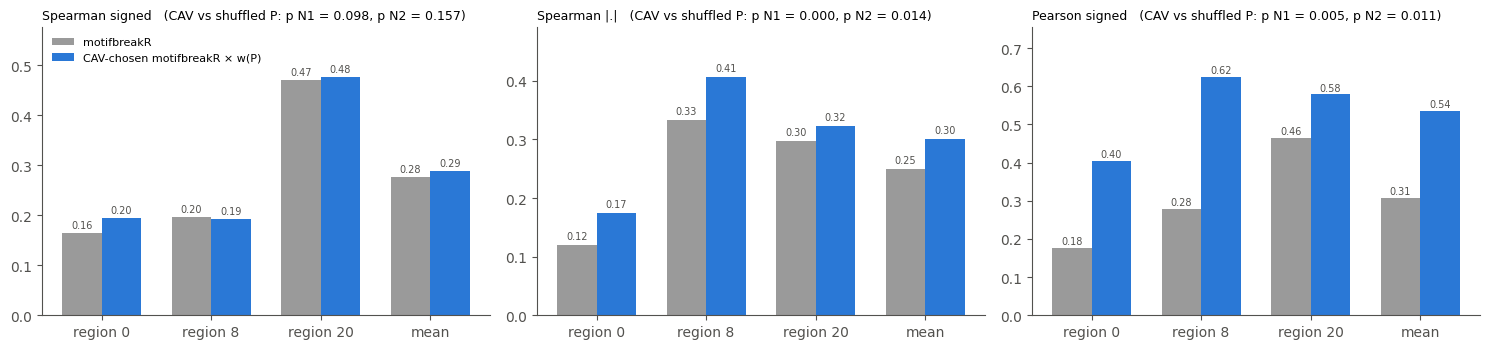

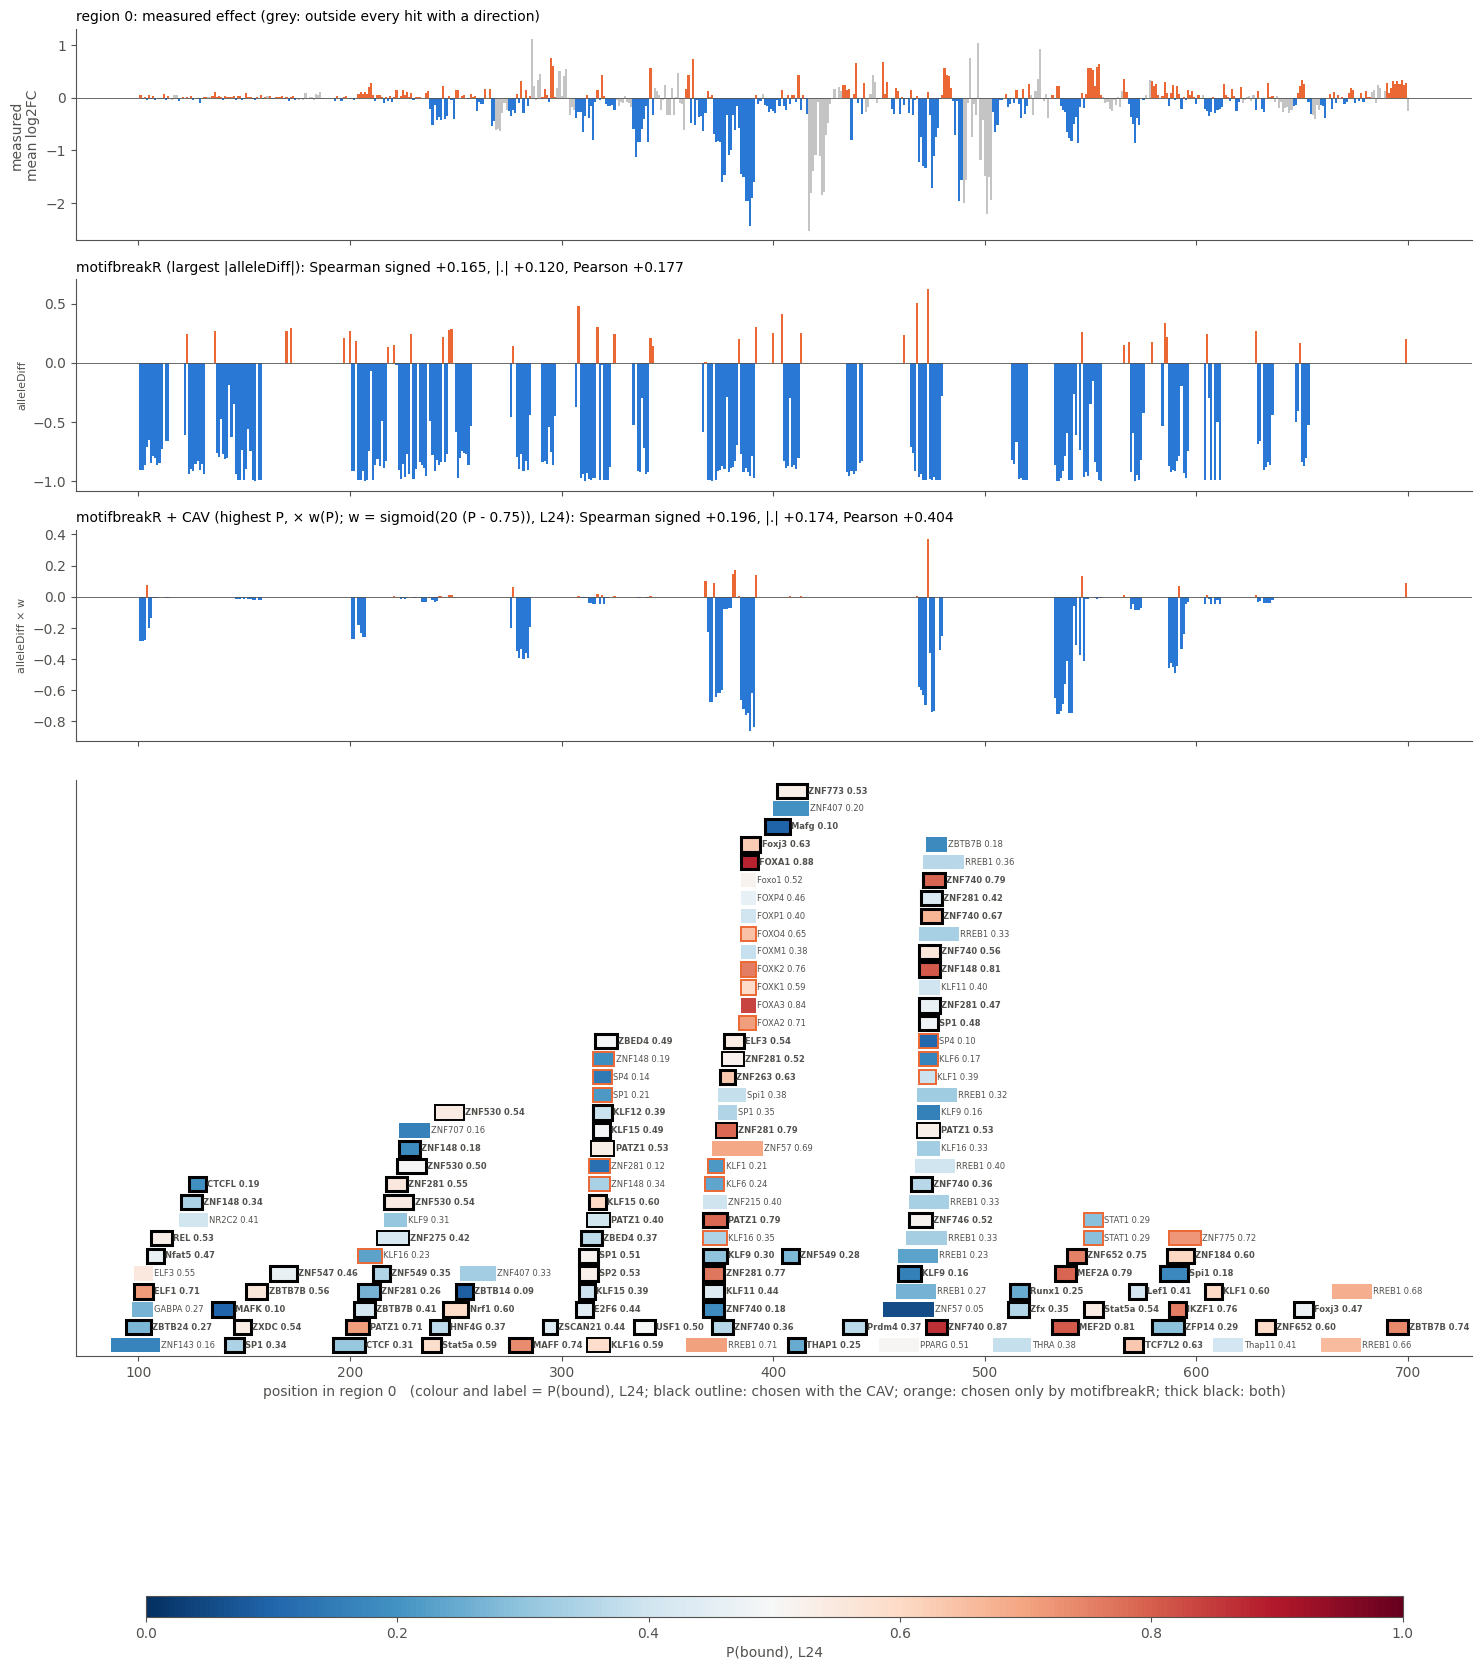

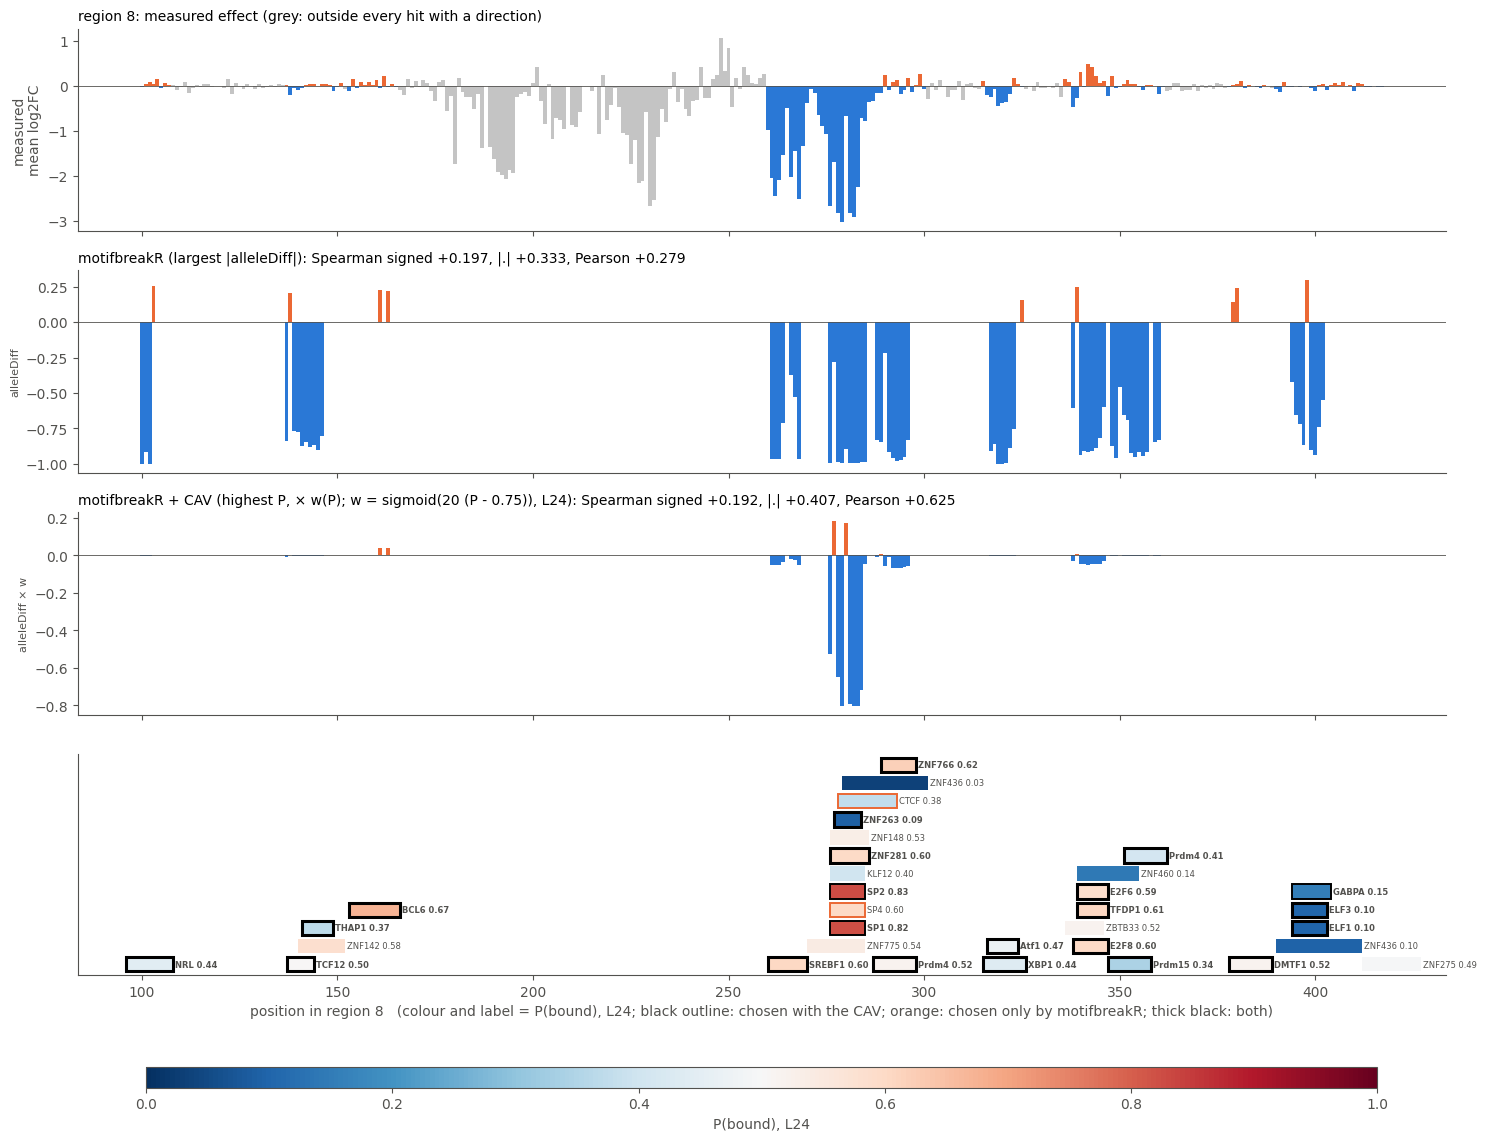

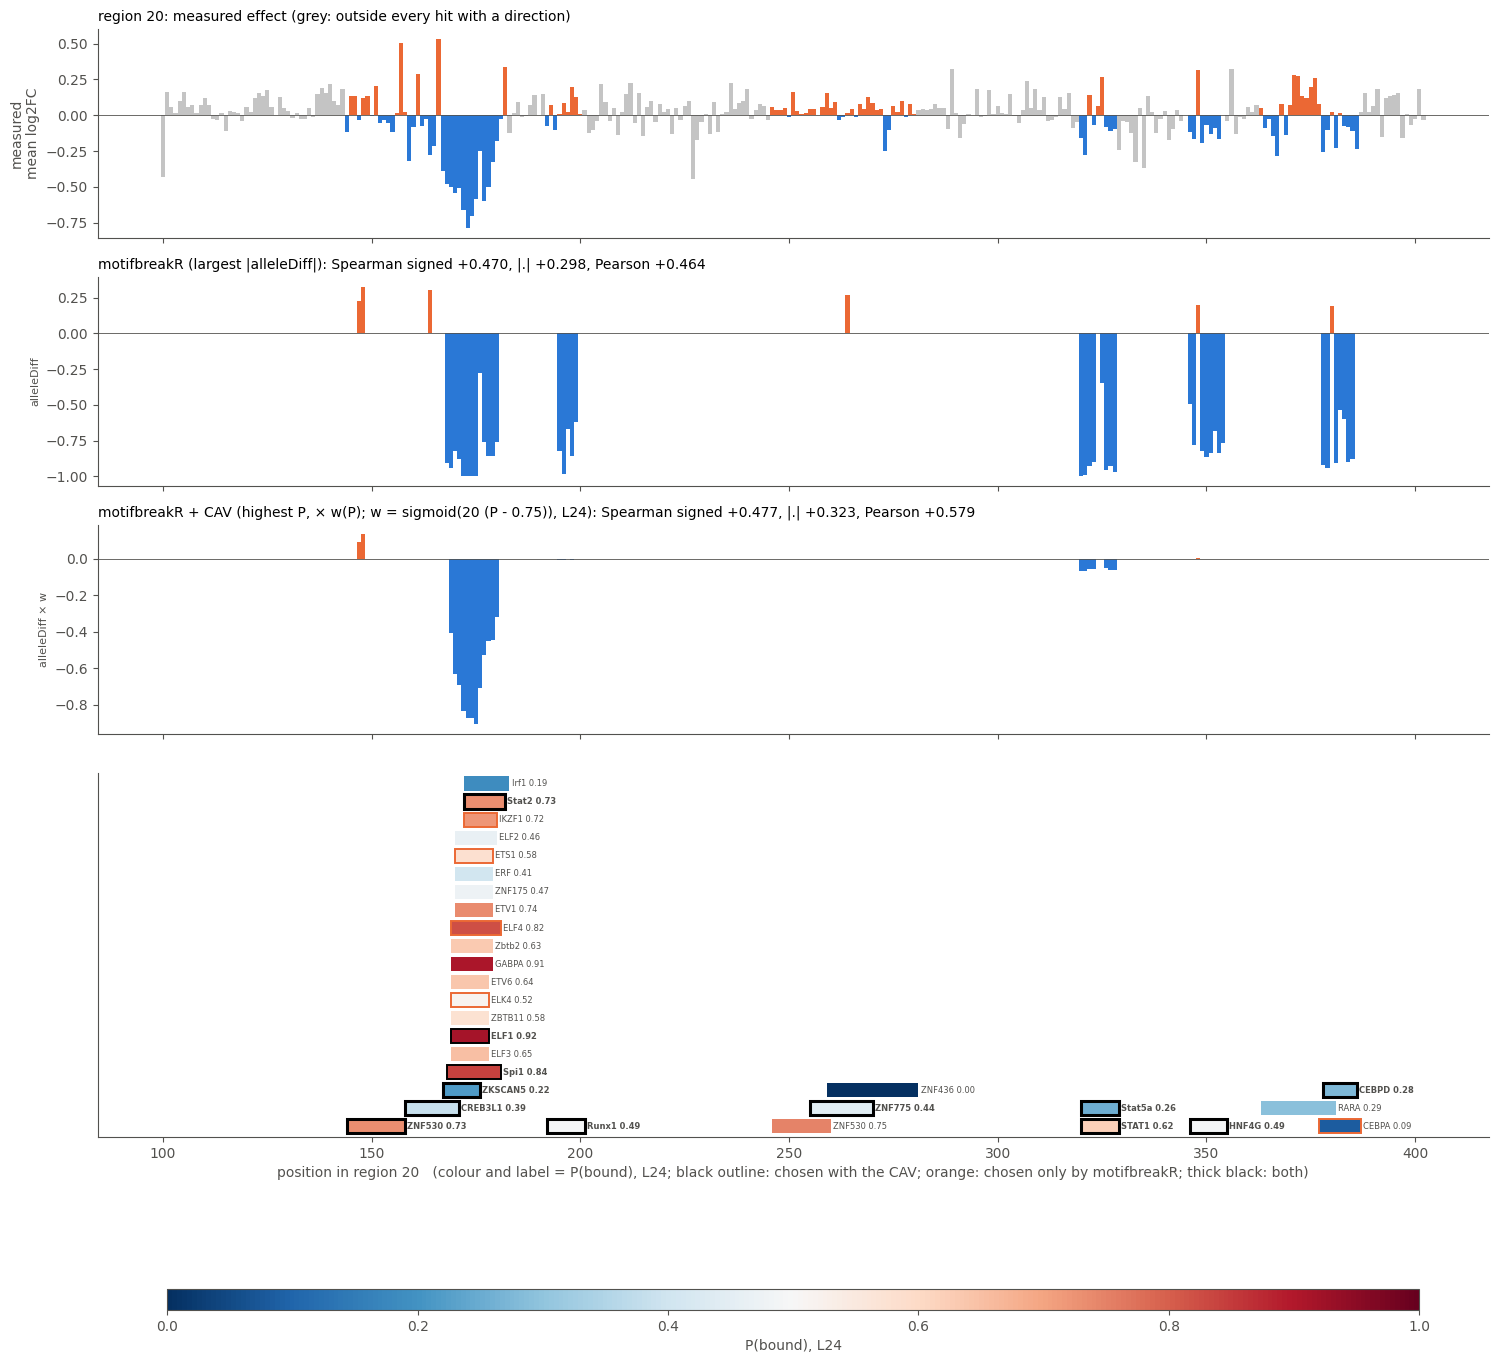

In [34]:
# ===== Figures: motifbreakR vs motifbreakR + CAV (run after the three cells above) =====
BASE, OURS = "motifbreakR", "CAV-chosen motifbreakR × w(P)"


def mc_choice(r, p_hit):
    # per SNV, the motif chosen by motifbreakR (largest |alleleDiff|) and by the CAV (highest P); None if no candidate
    m, t = MC[r], MC[r]["t"]
    P = np.full(len(t), -np.inf)
    np.maximum.at(P, m["lj"], p_hit[m["lh"]])
    out = {}
    for name, key in ((BASE, np.abs(t["alleleDiff"].values)), (OURS, P + 1e-9 * np.abs(t["alleleDiff"].values))):
        o = np.lexsort((-key, t["i"].values))
        first = o[np.r_[True, t["i"].values[o][1:] != t["i"].values[o][:-1]]]
        ch = np.array([None] * m["n"], dtype=object)
        ch[t["i"].values[first]] = t["motif"].values[first]
        out[name] = ch
    return out


# ---------- 1. summary: both rules, every region and the mean ----------
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
regs = list(D)
x = np.arange(len(regs) + 1)
for a, mt in zip(ax, METRICS):
    j = METRICS.index(mt)
    for off, k, c in ((-0.18, BASE, "#9a9a9a"), (0.18, OURS, "#2a78d6")):
        vals = list(obs_mc[k][:, j]) + [obs_mc[k][:, j].mean()]
        a.bar(x + off, vals, width=0.36, color=c, label=k)
        for xi, v in zip(x + off, vals):
            a.text(xi, v + (0.01 if v >= 0 else -0.03), f"{v:.2f}", ha="center", fontsize=7, color=INK)
    p1, p2 = TM.loc[OURS, f"{mt}: p N1"], TM.loc[OURS, f"{mt}: p N2"]
    a.set_xticks(x); a.set_xticklabels([f"region {r}" for r in regs] + ["mean"])
    a.axhline(0, color=INK, lw=.6)
    lo_, hi_ = a.get_ylim(); a.set_ylim(min(lo_, 0), hi_ + 0.15 * (hi_ - min(lo_, 0)))
    a.set_title(f"{mt}   (CAV vs shuffled P: p N1 = {p1:.3f}, p N2 = {p2:.3f})", loc="left", fontsize=9)
ax[0].legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(f"{OUT}/motifbreakr_plus_cav_summary_L{LP}.png", dpi=150, bbox_inches="tight"); plt.show()

# ---------- 2. tracks: log2FC / motifbreakR / motifbreakR + CAV / motifs ----------
cm, nm = plt.get_cmap("RdBu_r"), mcolors.TwoSlopeNorm(vmin=0, vcenter=0.5, vmax=1)
col = lambda v: np.where(v < 0, C1, C2)
for r, d in D.items():
    p = PL[r]
    pr = mc_predict(r, p)
    ch = mc_choice(r, p)
    S_ = pd.DataFrame({"local": d["local"], "y": d["y"], "a": pr[BASE], "b": pr[OURS]})
    pos_all = d["snv"].groupby("local")["log2FC"].mean()
    pos = S_.groupby("local")[["a", "b"]].mean()
    sc = {k: scores(S_[k].values, S_["y"].values) for k in ("a", "b")}
    # a hit is marked as chosen if its motif was chosen for at least one SNV it covers
    snv_of_row = np.repeat(np.arange(len(d["st"])), np.diff(np.r_[d["st"], len(d["sn"])]))
    row_motif = d["hits"].loc[d["hid"], "motif"].values
    chosen = {k: set(d["hid"][row_motif == v[snv_of_row]]) for k, v in ch.items()}

    hh = d["hits"].loc[d["hs"], ["motif", "start", "end"]].copy()
    hh["hit_id"], hh["P"] = d["hs"], p
    hh = hh.sort_values(["start", "end"]).reset_index(drop=True)
    hh["label"] = [f"{m} {q:.2f}" for m, q in zip(hh["motif"], hh["P"])]
    span = pos_all.index.max() - pos_all.index.min() + 1
    ends, lane = [], []
    for a_, b_, lab in zip(hh["start"], hh["end"], hh["label"]):
        b_ = b_ + 1 + 0.0045 * span * len(lab)
        kk = next((i for i, e in enumerate(ends) if e <= a_), len(ends))
        if kk == len(ends):
            ends.append(b_)
        else:
            ends[kk] = b_
        lane.append(kk)
    nrow = max(lane) + 1 if lane else 1
    fig, ax = plt.subplots(4, 1, figsize=(15, 8 + 0.3 * nrow), sharex=True,
                           gridspec_kw={"height_ratios": [2.2, 2.2, 2.2, 0.3 * nrow + 0.4]})
    ax[0].bar(pos_all.index, pos_all.values, width=1, color=np.where(~pos_all.index.isin(pos.index), GREY, col(pos_all.values)))
    ax[0].set_ylabel("measured\nmean log2FC")
    ax[0].set_title(f"region {r}: measured effect (grey: outside every hit with a direction)", loc="left", fontsize=10)
    for a, k, name, ylab in ((ax[1], "a", "motifbreakR (largest |alleleDiff|)", "alleleDiff"),
                             (ax[2], "b", f"motifbreakR + CAV (highest P, × w(P); w = sigmoid({K} (P - {MID})), L{LP})", "alleleDiff × w")):
        a.bar(pos.index, pos[k].values, width=1, color=col(pos[k].values))
        a.set_ylabel(ylab, fontsize=8)
        a.set_title(f"{name}: Spearman signed {sc[k][0]:+.3f}, |.| {sc[k][1]:+.3f}, Pearson {sc[k][2]:+.3f}", loc="left", fontsize=10)
    for a in ax[:3]:
        a.axhline(0, color=INK, lw=.6)
    for (_, h), kk in zip(hh.iterrows(), lane):
        inC, inB = h["hit_id"] in chosen[OURS], h["hit_id"] in chosen[BASE]
        ec = "black" if inC else (C2 if inB else "none")
        ax[3].add_patch(plt.Rectangle((h["start"], kk), h["end"] - h["start"], 0.8, facecolor=cm(nm(h["P"])),
                                      edgecolor=ec, linewidth=(2.2 if (inC and inB) else 1.4) if ec != "none" else 0))
        ax[3].text(h["end"] + 0.5, kk + 0.4, h["label"], va="center", fontsize=6, color=INK,
                   fontweight="bold" if inC else "normal")
    ax[3].set_ylim(-0.2, nrow); ax[3].set_yticks([])
    ax[3].set_xlabel(f"position in region {r}   (colour and label = P(bound), L{LP}; black outline: chosen with the CAV; "
                     f"orange: chosen only by motifbreakR; thick black: both)")
    fig.colorbar(plt.cm.ScalarMappable(norm=nm, cmap=cm), ax=ax[3], shrink=.9, label=f"P(bound), L{LP}",
                 orientation="horizontal", pad=0.25, aspect=60)
    plt.tight_layout()
    plt.savefig(f"{OUT}/track_r{r}_motifbreakr_plus_cav_L{LP}.png", dpi=150, bbox_inches="tight"); plt.show()


### layerwise

layer 0 done; layer 1 done; layer 2 done; layer 3 done; layer 4 done; layer 5 done; layer 6 done; layer 7 done; layer 8 done; layer 9 done; layer 10 done; layer 11 done; layer 12 done; layer 13 done; layer 14 done; layer 15 done; layer 16 done; layer 17 done; layer 18 done; layer 19 done; layer 20 done; layer 21 done; layer 22 done; layer 23 done; layer 24 done; layer 25 done; layer 26 done; layer 27 done; layer 28 done; layer 29 done

=== motifbreakR + CAV by layer (3-region mean; w = sigmoid(20 (P - 0.75)); nulls 200 shuffles per layer)

--- Spearman signed: motifbreakR alone +0.277; layers with p < .05: N1 0, N2 1, both 0 of 30; layers above motifbreakR: 10
layer              0      3      6      9      12     15     18     21     24     27     29
obs            +0.254 +0.248 +0.258 +0.269 +0.254 +0.260 +0.274 +0.288 +0.288 +0.278 +0.254
null N1        +0.259 +0.260 +0.262 +0.260 +0.260 +0.260 +0.258 +0.260 +0.260 +0.261 +0.260
p N1           +0.610 +0.745 +0.575 +0.325 +0.600 +0.50

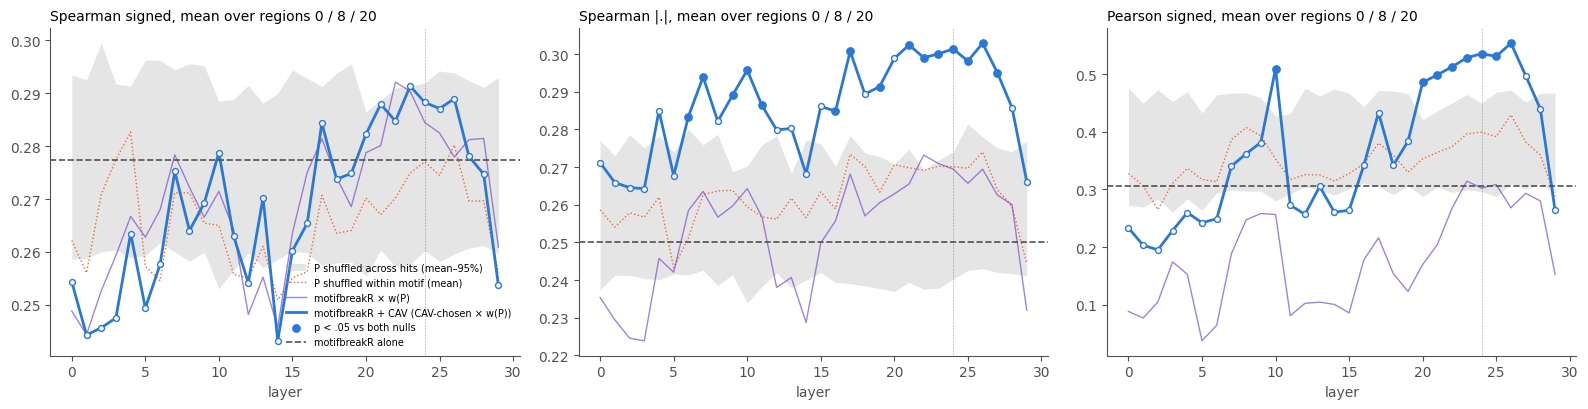

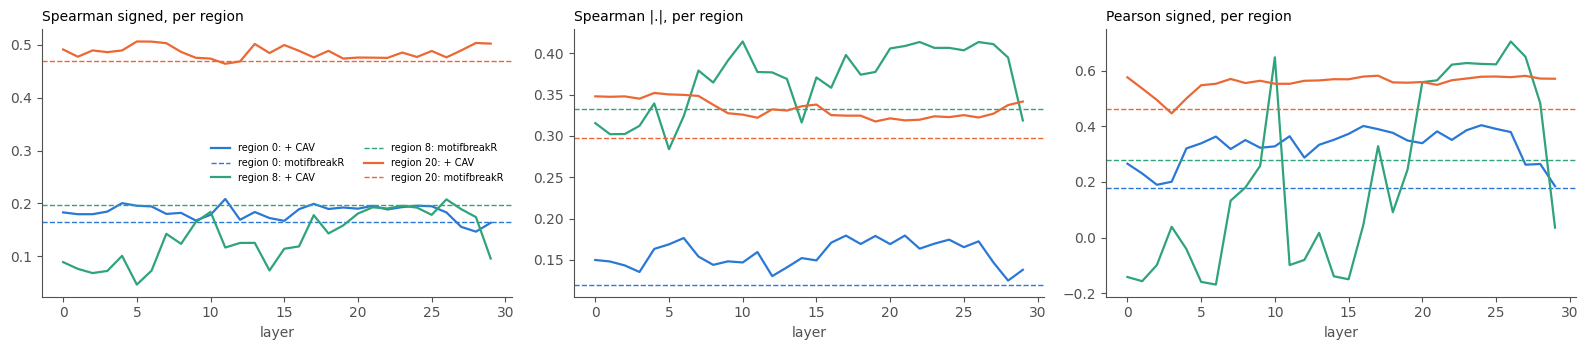

In [35]:
# ===== motifbreakR + CAV at every layer (run after the cells above) =====
# For each layer l: P(bound) from that layer's fits, the same four motifbreakR rules, 3-region mean, and the nulls
# (P of that layer shuffled across hits, N1, and within motif, N2). motifbreakR alone does not depend on the layer.
N_PERM_LAYER = 200
BASE, OURS = "motifbreakR", "CAV-chosen motifbreakR × w(P)"
LAYERS_ALL = list(D[next(iter(D))]["P"].columns)


def perm_global_l(l, rng):
    return {r: rng.permutation(d["P"][l].values) for r, d in D.items()}


def perm_motif_l(l, rng):
    out = {r: d["P"][l].values.copy() for r, d in D.items()}
    for mem in GROUPS.values():
        if len(mem) > 1:
            vals = np.array([D[r]["P"][l].values[i] for r, i in mem])[rng.permutation(len(mem))]
            for (r, i), v in zip(mem, vals):
                out[r][i] = v
    return out


rng = np.random.default_rng(7)
rows = []
for l in LAYERS_ALL:
    o = {k: v.mean(0) for k, v in mc_eval({r: d["P"][l].values for r, d in D.items()}).items()}
    n1_ = np.array([[v.mean(0) for v in mc_eval(perm_global_l(l, rng)).values()] for _ in range(N_PERM_LAYER)])
    n2_ = np.array([[v.mean(0) for v in mc_eval(perm_motif_l(l, rng)).values()] for _ in range(N_PERM_LAYER)])
    for ki, k in enumerate(MC_RULES):
        for j, mt in enumerate(METRICS):
            rows.append({"layer": l, "rule": k, "metric": mt, "obs": o[k][j],
                         "null N1": np.nanmean(n1_[:, ki, j]), "N1 95%": np.nanpercentile(n1_[:, ki, j], 95),
                         "p N1": np.mean(n1_[:, ki, j] >= o[k][j]),
                         "null N2": np.nanmean(n2_[:, ki, j]), "N2 95%": np.nanpercentile(n2_[:, ki, j], 95),
                         "p N2": np.mean(n2_[:, ki, j] >= o[k][j])})
    print(f"layer {l} done", end="; " if l != LAYERS_ALL[-1] else "\n", flush=True)
ML = pd.DataFrame(rows)
ML.to_csv(f"{OUT}/motifbreakr_plus_cav_by_layer.csv", index=False)

show_l = [l for l in LAYERS_ALL if l % 3 == 0 or l == LAYERS_ALL[-1] or l == LP]
print(f"\n=== motifbreakR + CAV by layer (3-region mean; w = sigmoid({K} (P - {MID})); nulls {N_PERM_LAYER} shuffles per layer)")
for mt in METRICS:
    base = ML[(ML.rule == "motifbreakR") & (ML.metric == mt)]["obs"].iloc[0]
    t = ML[(ML.rule == OURS) & (ML.metric == mt)].set_index("layer")
    print(f"\n--- {mt}: motifbreakR alone {base:+.3f}; layers with p < .05: N1 {int((t['p N1'] < .05).sum())}, "
          f"N2 {int((t['p N2'] < .05).sum())}, both {int(((t['p N1'] < .05) & (t['p N2'] < .05)).sum())} of {len(t)}; "
          f"layers above motifbreakR: {int((t['obs'] > base).sum())}")
    print(t.loc[show_l, ["obs", "null N1", "p N1", "null N2", "p N2"]].assign(**{"vs motifbreakR": t.loc[show_l, "obs"] - base})
          .T.to_string(float_format=lambda x: f"{x:+.3f}"))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, mt in zip(ax, METRICS):
    base = ML[(ML.rule == "motifbreakR") & (ML.metric == mt)]["obs"].iloc[0]
    t = ML[(ML.rule == OURS) & (ML.metric == mt)].sort_values("layer")
    a.fill_between(t.layer, t["null N1"], t["N1 95%"], color="#9a9a9a", alpha=.25, lw=0, label="P shuffled across hits (mean–95%)")
    a.plot(t.layer, t["null N2"], c="#eb6834", lw=1, ls=":", label="P shuffled within motif (mean)")
    t2 = ML[(ML.rule == "motifbreakR × w(P)") & (ML.metric == mt)].sort_values("layer")
    a.plot(t2.layer, t2.obs, c="#7a4fc8", lw=1, alpha=.7, label="motifbreakR × w(P)")
    a.plot(t.layer, t.obs, c="#2a78d6", lw=2, label="motifbreakR + CAV (CAV-chosen × w(P))")
    sig = (t["p N1"] < .05) & (t["p N2"] < .05)
    a.scatter(t.layer[sig], t.obs[sig], c="#2a78d6", s=28, zorder=3, label="p < .05 vs both nulls")
    a.scatter(t.layer[~sig], t.obs[~sig], facecolors="white", edgecolors="#2a78d6", s=18, zorder=3)
    a.axhline(base, c=INK, lw=1.2, ls="--", label="motifbreakR alone")
    a.axvline(LP, c=INK, lw=.4, ls=":")
    a.set_xlabel("layer"); a.set_title(f"{mt}, mean over regions {' / '.join(map(str, D))}", loc="left", fontsize=10)
ax[0].legend(frameon=False, fontsize=7, loc="best")
plt.tight_layout(); plt.savefig(f"{OUT}/motifbreakr_plus_cav_by_layer.png", dpi=150, bbox_inches="tight"); plt.show()

# per-region curves of the main rule
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
for a, mt in zip(ax, METRICS):
    j = METRICS.index(mt)
    for r, c in zip(D, ("#2a78d6", "#2fa37a", "#eb6834")):
        ys = [scores(mc_predict(r, D[r]["P"][l].values)[OURS], D[r]["y"])[j] for l in LAYERS_ALL]
        a.plot(LAYERS_ALL, ys, c=c, lw=1.6, label=f"region {r}: + CAV")
        a.axhline(scores(mc_predict(r, PL[r])["motifbreakR"], D[r]["y"])[j], c=c, lw=1, ls="--", label=f"region {r}: motifbreakR")
    a.set_xlabel("layer"); a.set_title(f"{mt}, per region", loc="left", fontsize=10)
ax[0].legend(frameon=False, fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(f"{OUT}/motifbreakr_plus_cav_by_layer_regions.png", dpi=150, bbox_inches="tight"); plt.show()


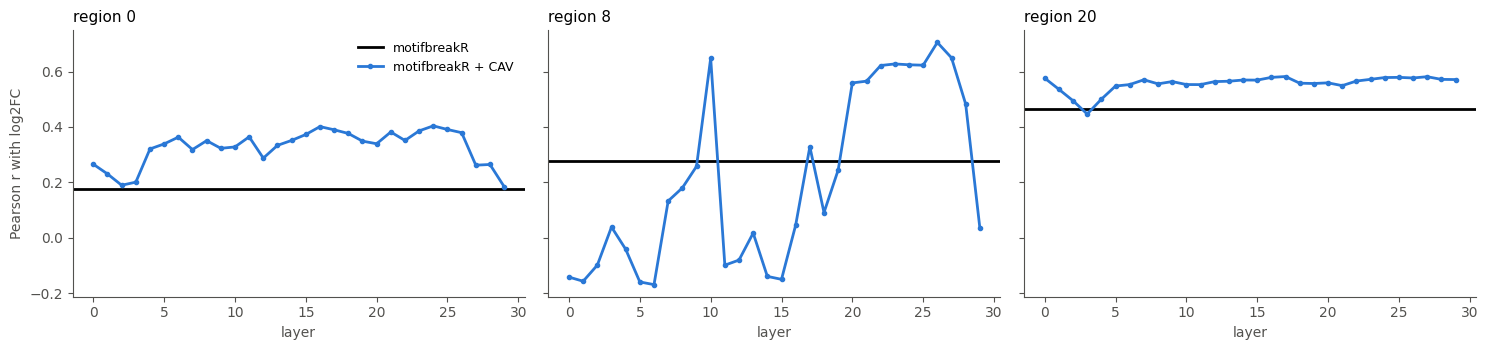

In [37]:
# Pearson by layer, per region: motifbreakR vs motifbreakR + CAV
BASE, OURS = "motifbreakR", "CAV-chosen motifbreakR × w(P)"
pear = lambda v, y: np.corrcoef(v, y)[0, 1] if np.std(v) > 0 else np.nan
LAYERS_ALL = list(D[next(iter(D))]["P"].columns)

fig, ax = plt.subplots(1, len(D), figsize=(5 * len(D), 3.6), sharey=True)
for a, (r, d) in zip(np.atleast_1d(ax), D.items()):
    ys = [pear(mc_predict(r, d["P"][l].values)[OURS], d["y"]) for l in LAYERS_ALL]
    base = pear(mc_predict(r, PL[r])[BASE], d["y"])
    a.axhline(base, c="black", lw=2, label="motifbreakR")
    a.plot(LAYERS_ALL, ys, c="#2a78d6", lw=2, marker="o", ms=3, label="motifbreakR + CAV")
    a.set_title(f"region {r}", loc="left", fontsize=11)
    a.set_xlabel("layer")
np.atleast_1d(ax)[0].set_ylabel("Pearson r with log2FC")
np.atleast_1d(ax)[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT}/pearson_by_layer_simple.png", dpi=150, bbox_inches="tight"); plt.show()

## 6 End

In [8]:
from google.colab import runtime
runtime.unassign()